# 02. Исследование журнала событий СМВУ 2019-2026

**Что исследуем.** Система мониторинга и управления (СМВУ) инженерных коллекторов Москвы пишет в журнал все, что
сообщают датчики: замеры газа и температуры, смены состояний насосов, вентиляторов, дверей, люков, дымовых
извещателей. Задача хакатона – по этому журналу прогнозировать инциденты на 24 часа вперед с указанием места.
Прежде чем строить целевую переменную и признаки, нужно понять сам журнал: из чего складывается поток событий,
какие в нем есть режимы и артефакты сбора, какие события похожи на инциденты, а какие – на шум или работы бригад.

**Как устроен ноутбук.** В разделе 0 – данные, их объем и очистка, и вопросы, на которые отвечает исследование.
Разделы 1-9 – само исследование: каждый начинается с вопроса, по ходу фиксирует наблюдения, гипотезы и проверки
и заканчивается кратким итогом. Раздел 10 – сводка результатов и что из них следует для построения целевой
переменной (этап 2) и признаков (этап 3).

0. Данные: объем, очистка, вопросы исследования
1. Из чего состоит поток событий
2. Покрытие во времени и жизненный цикл каналов
3. Внедрение новой СМВУ в 2021 году: границы периода и последствия
4. Телеметрия: газ, температура, ИБП
5. Состояния и тревоги: словарь, длительность, дребезг
6. Ступени и провалы суммарного потока
7. Потеря связи: пачки «Неопределен»
8. Сезонность и время суток
9. Объекты, иерархия, пикеты
10. Итоги

Все времена в ноутбуке московские.

## 0. Данные
### 0.1 Подготовка
Очищенный журнал лежит в `datasets/processed/events` (Parquet по годам и месяцам), справочник каналов с объектами
и пикетами – в `channels.parquet`, отчет об очистке по годовым файлам – в `etl_report.parquet`.
Журнал большой (сотни миллионов строк), поэтому тяжелые расчеты делаем один раз в Spark и сохраняем компактные
витрины (почасовой поток по типам датчиков, активность канала по дням, словарь состояний, смены состояний и т. д.),
а дальше анализируем их в pandas.

In [1]:
import time

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display
from pyspark.sql import Window
from pyspark.sql import functions as F

from annanas import aggregates as agg
from annanas import smvu
from annanas.paths import EDA_DIR, EVENTS_DIR, PROCESSED_DIR
from annanas.spark import get_spark

spark = get_spark("02_eda")
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "true")  # быстрый toPandas
EDA_DIR.mkdir(parents=True, exist_ok=True)

events = spark.read.parquet(str(EVENTS_DIR))
channels_pd = agg.read_vitrine(PROCESSED_DIR / "channels.parquet")
channels = spark.createDataFrame(channels_pd[["ид_канала_данных", "тип_датчика", "ид_объект"]])
etl_report = agg.read_vitrine(PROCESSED_DIR / "etl_report.parquet")

KNOWN_IDS = set(channels_pd["ид_канала_данных"])
UNKNOWN = "нет в справочнике"
OTHER = "прочие"
GAS = "Газовый датчик"
PER = [smvu.ДО, smvu.ПЕРЕХОД, smvu.ПОСЛЕ]

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/09/24 20:42:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/09/24 20:42:40 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


In [2]:
# Оформление графиков: фиксированная категориальная палитра, тонкие линии, приглушенные оси
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GREY, SHADE, INK, INK2 = "#9a9994", "#c9c7bf", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 110, "figure.constrained_layout.use": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "lines.linewidth": 1.5, "axes.prop_cycle": plt.cycler(color=PALETTE),
})


def window(df: pd.DataFrame, start, end, col: str = "день") -> pd.DataFrame:
    """Строки с start <= df[col] < end."""
    return df[(df[col] >= pd.Timestamp(start)) & (df[col] < pd.Timestamp(end))]


def month_start(s: pd.Series) -> pd.Series:
    return s.dt.to_period("M").dt.to_timestamp()


def week_start(s: pd.Series) -> pd.Series:
    return s.dt.to_period("W").dt.start_time


def mark_customer_2021(ax):
    """Светлый фон на 2021 календарном году: по словам заказчика, тогда внедрялась новая СМВУ.
    Используется до раздела 3, где границы переходного периода находятся по данным."""
    lo, hi = ax.get_xlim()
    ax.axvspan(pd.Timestamp("2021-01-01"), pd.Timestamp("2022-01-01"), color=SHADE, alpha=0.25, lw=0, zorder=0,
               label="2021: новая СМВУ (со слов заказчика)")
    ax.set_xlim(lo, hi)


def shade_transition(ax):
    """Серый фон – переходный период СМВУ [T0, T1), найденный в разделе 3.1; границы оси не расширяет."""
    lo, hi = ax.get_xlim()
    ax.axvspan(T0, T1, color=SHADE, alpha=0.5, lw=0, zorder=0, label="переход СМВУ")
    ax.set_xlim(lo, hi)


def mark_transition(ax):
    """Пунктирные вертикали на границах перехода – для графиков внутри 2021 года."""
    for t in (T0, T1):
        ax.axvline(t, color=INK2, ls="--", lw=1, zorder=1)


def thousands(ax, axis="y"):
    f = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(f)


def legend_right(ax):
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))

### 0.2 Витрины
Витрины строятся один раз (десятки минут) и дальше читаются из `datasets/processed/eda/`. Кроме общих витрин
из `annanas.aggregates` здесь определены три своих:
- `unknown_channels` – что пишут каналы, которых нет в справочнике (по часам, классу записи и состоянию);
- `undefined_daily` – сколько записей «Неопределен» канал дал за сутки: канал, который за день записал только
  «Неопределен», мы не будем считать активным;
- `alarm_episodes` – эпизоды тревоги: подряд идущие тревожные записи канала до первой нетревожной
  (подробно в разделе 5).

Витрины читаются через Spark (`toPandas()` в сессии с московским временем), поэтому все метки времени московские.

In [3]:
def unknown_channels_profile():
    """События каналов, которых нет в справочнике: по часам, классу записи, состоянию и флагу тревожности."""
    return (events.join(F.broadcast(channels.select("ид_канала_данных")), "ид_канала_данных", "left_anti")
            .groupBy(F.date_trunc("hour", "дата_время").alias("час"), "класс_записи", "состояние", "тревожное")
            .agg(F.count("*").alias("количество_событий")))


def undefined_daily():
    """Число записей «Неопределен» канала за сутки."""
    return (events.filter(F.col("состояние") == "Неопределен")
            .groupBy(F.to_date("дата_время").alias("день"), "ид_канала_данных")
            .agg(F.count("*").alias("количество_неопределен")))


def alarm_episodes():
    """Эпизоды тревоги: подряд идущие тревожные записи канала (порядок дата_время, ид_события) до первой
    нетревожной. Конец эпизода – время первой нетревожной записи; если ее нет, эпизод открыт.
    В витрине state_runs `секунд_до_следующего` – время до следующей записи любого вида, поэтому
    длительность тревоги по ней занижена: здесь она считается по эпизоду."""
    w = Window.partitionBy("ид_канала_данных").orderBy("дата_время", "ид_события")
    prev = F.lag("тревожное").over(w)
    r = (V["state_runs"]
         .withColumn("предыдущее_тревожное", prev)
         .filter(F.col("тревожное"))
         .withColumn("начало_эпизода",
                     (F.col("предыдущее_тревожное").isNull() | ~F.col("предыдущее_тревожное")).cast("int"))
         .withColumn("номер_эпизода", F.sum("начало_эпизода").over(w.rowsBetween(Window.unboundedPreceding, 0))))
    return (r.groupBy("ид_канала_данных", "номер_эпизода")
            .agg(F.min("дата_время").alias("начало"), F.max("время_следующего").alias("время_после_последней"),
                 F.max(F.col("время_следующего").isNull().cast("int")).alias("открыт"),
                 F.count("*").alias("записей"),
                 F.min(F.struct("дата_время", "ид_события", "состояние"))["состояние"].alias("первое_состояние"),
                 F.max(F.struct("дата_время", "ид_события", "следующее_состояние"))["следующее_состояние"]
                 .alias("следующее_состояние"),
                 F.array_sort(F.collect_set("состояние")).alias("состояния"))
            .withColumn("конец", F.when(F.col("открыт") == 0, F.col("время_после_последней")))
            .drop("время_после_последней"))


BUILD = [  # (витрина, построитель, shuffle-партиций): окна meas_gaps и state_runs тяжелые
    ("hourly_type", lambda: agg.hourly_type(events, channels), 64),
    ("daily_channel", lambda: agg.daily_channel(events), 64),
    ("state_vocab", lambda: agg.state_vocab(events, channels), 64),
    ("undefined_bursts", lambda: agg.undefined_bursts(events, channels), 64),
    ("unknown_channels", unknown_channels_profile, 64),
    ("meas_gaps", lambda: agg.meas_gaps(events), 400),
    ("state_runs", lambda: agg.state_runs(events), 400),
    ("undefined_daily", undefined_daily, 64),
    ("alarm_episodes", alarm_episodes, 400),   # после state_runs: строится из нее
]
V = {}
for name, builder, parts in BUILD:
    spark.conf.set("spark.sql.shuffle.partitions", str(parts))
    t0 = time.perf_counter()
    V[name] = agg.build_or_load(name, builder, EDA_DIR, spark)
    print(f"{name}: {time.perf_counter() - t0:.0f} с", flush=True)
spark.conf.set("spark.sql.shuffle.partitions", "64")
{k: f"{v.count():,}" for k, v in V.items()}

hourly_type: 0 с


daily_channel: 0 с


state_vocab: 0 с


undefined_bursts: 0 с


unknown_channels: 0 с


meas_gaps: 0 с


state_runs: 0 с


undefined_daily: 0 с


alarm_episodes: 0 с


{'hourly_type': '695,738',
 'daily_channel': '4,376,102',
 'state_vocab': '12,142',
 'undefined_bursts': '668,645',
 'unknown_channels': '196,816',
 'meas_gaps': '920,377',
 'state_runs': '88,237,751',
 'undefined_daily': '1,032,126',
 'alarm_episodes': '2,233,393'}

In [4]:
def with_channel_attrs(df: pd.DataFrame, cols=("тип_датчика", "ид_объект")) -> pd.DataFrame:
    """Left join со справочником: каналы вне справочника остаются, тип = UNKNOWN, объект = -1."""
    out = df.merge(channels_pd[["ид_канала_данных", *cols]], on="ид_канала_данных", how="left")
    if "тип_датчика" in cols:
        out["тип_датчика"] = out["тип_датчика"].fillna(UNKNOWN)
    if "ид_объект" in cols:
        out["ид_объект"] = out["ид_объект"].fillna(-1).astype("int32")
    return out


# Компактные витрины – целиком в pandas
hourly = V["hourly_type"].toPandas()
hourly["тип_датчика"] = hourly["тип_датчика"].fillna(UNKNOWN)
hourly["год"] = hourly["час"].dt.year

vocab = V["state_vocab"].toPandas()
vocab["тип_датчика"] = vocab["тип_датчика"].fillna(UNKNOWN)

bursts = V["undefined_bursts"].toPandas()
bursts["ид_объект"] = bursts["ид_объект"].fillna(-1).astype("int32")
bursts["минута"] = pd.to_datetime(bursts["минута"])

unk = V["unknown_channels"].toPandas()

# daily_channel – десятки миллионов строк: берем в компактных типах
daily_ch = (V["daily_channel"]
            .select("день", F.col("ид_канала_данных").cast("int"), "класс_записи",
                    F.col("количество_событий").cast("int"), F.col("количество_тревожных").cast("int"),
                    *[F.col(c).cast("float") for c in ("среднее_значение", "минимум_значения", "максимум_значения")])
            .toPandas())
daily_ch["день"] = pd.to_datetime(daily_ch["день"])
und_day = V["undefined_daily"].select("день", F.col("ид_канала_данных").cast("int"),
                                      F.col("количество_неопределен").cast("int")).toPandas()
und_day["день"] = pd.to_datetime(und_day["день"])
daily_ch = daily_ch.merge(und_day.assign(класс_записи="состояние"), on=["день", "ид_канала_данных", "класс_записи"],
                          how="left")
daily_ch["количество_неопределен"] = daily_ch["количество_неопределен"].fillna(0).astype("int32")
daily_ch = with_channel_attrs(daily_ch)
daily_ch["год"] = daily_ch["день"].dt.year.astype("int16")
daily_ch["в_справочнике"] = daily_ch["ид_канала_данных"].isin(KNOWN_IDS)

gaps = V["meas_gaps"].toPandas()
gaps["день"] = pd.to_datetime(gaps["день"])
gaps = with_channel_attrs(gaps)
gaps["год"] = gaps["день"].dt.year

# Смены состояний (десятки миллионов строк) остаются в Spark, к ним добавляем тип датчика
runs = (V["state_runs"]
        .join(F.broadcast(channels.select("ид_канала_данных", "тип_датчика")), "ид_канала_данных", "left")
        .fillna({"тип_датчика": UNKNOWN}))

DATA_START, DATA_END = daily_ch["день"].min(), daily_ch["день"].max()
print(f"daily_ch: {len(daily_ch):,} строк, {daily_ch.memory_usage(deep=True).sum() / 2**30:.2f} GB;",
      f"период {DATA_START:%Y-%m-%d} … {DATA_END:%Y-%m-%d}")

daily_ch: 4,376,102 строк, 1.14 GB; период 2019-01-01 … 2026-06-30


### 0.3 Объем данных
Сначала – насколько велик журнал и из чего он состоит в самом общем виде: сколько событий в год, какая доля из
них тревожные, сколько приходится на замеры (числовые значения) и на смены состояний (текст вроде «Норма»,
«Неисправен»), и какая доля событий приходит от каналов, которых нет в справочнике.

In [5]:
cls = hourly.pivot_table(index="год", columns="класс_записи", values="количество_событий", aggfunc="sum", fill_value=0)
vol = pd.DataFrame({
    "событий": cls.sum(axis=1),
    "измерений": cls["измерение"],
    "состояний": cls["состояние"],
    "тревожных": hourly.groupby("год")["количество_тревожных"].sum(),
    "вне_справочника": hourly[hourly["тип_датчика"] == UNKNOWN].groupby("год")["количество_событий"].sum(),
}).fillna(0).astype("int64")
vol.loc["всего"] = vol.sum()
vol["доля_измерений_%"] = (vol["измерений"] / vol["событий"] * 100).round(1)
vol["доля_тревожных_%"] = (vol["тревожных"] / vol["событий"] * 100).round(2)
vol["доля_вне_справочника_%"] = (vol["вне_справочника"] / vol["событий"] * 100).round(2)
seen_ids = set(daily_ch["ид_канала_данных"].unique())
print(f"период данных: {DATA_START:%Y-%m-%d} … {DATA_END:%Y-%m-%d}")
print(f"каналов в справочнике: {len(KNOWN_IDS):,}, объектов: {channels_pd['ид_объект'].nunique()};",
      f"каналов, писавших в журнал: {len(seen_ids):,}, из них нет в справочнике: {len(seen_ids - KNOWN_IDS):,}")
vol

период данных: 2019-01-01 … 2026-06-30
каналов в справочнике: 11,485, объектов: 78; каналов, писавших в журнал: 12,627, из них нет в справочнике: 1,142


,событий,измерений,состояний,тревожных,вне_справочника,доля_измерений_%,доля_тревожных_%,доля_вне_справочника_%
год,,,,,,,,
2019,20991837,9626993,11364844,134132,2481504,45.9,0.64,11.82
2020,28172398,12920153,15252245,325662,3278453,45.9,1.16,11.64
2021,53698948,36076170,17622778,1199639,3323693,67.2,2.23,6.19
2022,43483149,33875898,9607251,133504,328990,77.9,0.31,0.76
2023,31374676,22662927,8711749,106945,21106,72.2,0.34,0.07
2024,49023883,39085453,9938430,115203,5257,79.7,0.23,0.01
2025,55541796,45790871,9750925,256471,530,82.4,0.46,0.00
2026,30695389,24705860,5989529,195422,122,80.5,0.64,0.00
всего,312982076,224744325,88237751,2466978,9439655,71.8,0.79,3.02


**Что видно.** В журнале 312 982 076 событий за 2019-01-01 … 2026-06-30 (2026 год – только первое полугодие).
Поток неравномерен по годам: от 21,0 млн событий в 2019 году до 55,5 млн в 2025-м. Тревожных событий всего
2 466 978, то есть 0,79 % потока; в 2021 году их доля заметно выше, чем в остальные годы (2,23 % против
0,23-1,16 %) – к этому вернемся в разделе 3. Доля замеров растет: 45,9 % в 2019 году и 82,4 % в 2025-м, то есть
прирост потока дают именно замеры. Каналы, которых нет в справочнике, дают 11,82 % событий 2019 года и почти
исчезают к 2023-му; для них нет ни типа датчика, ни объекта. В справочнике 11 485 каналов на 78 объектах,
а писали в журнал 12 627 каналов, из них 1 142 вне справочника.

### 0.4 Как данные очищены
Исходные годовые CSV прочитаны целиком и очищены одним и тем же порядком. Удалены строки заголовка, которые
встречаются внутри файла, и полные дубли строк (по `ид_события` не дедуплицировали: он не уникален, у замеров
и у состояний свои последовательности ID). Флаг `тревожное` приведен к логическому типу (в исходниках бывает и
`t/f`, и `true/false`); из `значение_датчика` выделены класс записи (`измерение` / `состояние`), числовое
значение и текст состояния. Строки с непарсящейся датой отбросили бы, но таких нет. События каналов вне
справочника не удалялись: они остаются в данных с типом «нет в справочнике». Ниже – что очистка сделала с
каждым годовым файлом.

In [6]:
etl_cols = ["год_файла", "строк_в_файле", "строк_заголовка", "полных_дублей", "битых_дат", "строк_после_очистки",
            "тревожных", "строк_каналов_вне_справочника"]
etl_tab = etl_report[etl_cols].set_index("год_файла").sort_index()
etl_tab.loc["всего"] = etl_tab.sum()
etl_tab

,строк_в_файле,строк_заголовка,полных_дублей,битых_дат,строк_после_очистки,тревожных,строк_каналов_вне_справочника
год_файла,,,,,,,
2019,20993328,0,1491,0,20991837,134132,2481504
2020,28172398,0,0,0,28172398,325662,3278453
2021,53698948,0,0,0,53698948,1199639,3323693
2022,43483149,0,0,0,43483149,133504,328990
2023,31937125,0,562449,0,31374676,106945,21106
2024,49023883,0,0,0,49023883,115203,5257
2025,55541797,1,0,0,55541796,256471,530
2026,30695389,0,0,0,30695389,195422,122
всего,313546017,1,563940,0,312982076,2466978,9439655


Очистка почти ничего не удалила: 563 940 полных дублей (1 491 в файле 2019 года и 562 449 в файле 2023-го),
одна строка заголовка внутри файла 2025 года, битых дат нет. После очистки остались те же 312 982 076 событий,
что и в таблице 0.3, и 2 466 978 тревожных.

### 0.5 Вопросы исследования
1. Из чего складывается поток событий и что определяет его объем (раздел 1)?
2. Все ли дни покрыты данными, как появляются и исчезают каналы, что за каналы вне справочника (раздел 2)?
3. **Информация заказчика:** в 2021 году внедрялась новая СМВУ, какое-то время старая и новая системы работали
   параллельно, операторы не могли полноценно работать в обеих, и много тревог оставалось неснятыми. Видно ли
   это в данных, где границы этого периода и как он изменил данные (раздел 3)?
4. Как ведет себя телеметрия, есть ли тревоги по числовым значениям, какое молчание датчика – норма (раздел 4)?
5. Какие состояния бывают и какие из них тревожные, сколько длятся тревоги, где кончается дребезг (раздел 5)?
6. Чем объясняются ступени и провалы суммарного потока (раздел 6)?
7. Как выглядит потеря связи и как ее формализовать (раздел 7)?
8. Есть ли у тревог сезонность и суточный ритм (раздел 8)?
9. Как тревоги распределены по объектам, устойчивы ли «проблемные» объекты, годятся ли пикеты как локация
   (раздел 9)?

Договоренности: каналы вне справочника не отбрасываем (join всегда `left`, тип – «нет в справочнике», объект –
`-1`); тревоги сравниваем в абсолютах по типам, а не долей от суммарного потока, потому что знаменатель
(поток) сам сильно меняется.

## 1. Из чего состоит поток событий
В разделе 0 видно, что поток за семь лет вырос почти втрое и что рост дали замеры. Хочется понять, какие именно
датчики дают поток и тревоги, и не определяет ли объем журнала какой-то один источник. Если да, то суммарный
поток мало говорит о состоянии коллекторов, и дальше его нужно раскладывать.

In [7]:
# Доля типов датчиков в потоке по годам, %
by_type = hourly.groupby(["год", "тип_датчика"])["количество_событий"].sum().unstack(fill_value=0)
by_type_pct = (by_type.div(by_type.sum(axis=1), axis=0) * 100).round(2).T
by_type_pct.sort_values(2025, ascending=False)

год,2019,2020,2021,2022,2023,2024,2025,2026
тип_датчика,,,,,,,,
Газовый датчик,41.97,44.93,67.37,77.73,72.18,79.54,82.36,80.50
Датчик движения,34.39,25.94,12.62,14.66,20.47,14.18,12.52,11.09
КД Дверь,2.95,2.46,1.20,1.46,2.09,1.50,1.23,1.00
Датчик дыма,0.25,1.45,4.12,0.48,0.70,0.33,0.62,1.15
Состояние УИР-Р,0.51,7.18,1.68,1.69,0.64,1.91,0.60,1.47
Датчик температуры,0.68,0.61,0.29,0.40,0.60,0.38,0.47,0.42
Состояние фазы,3.11,1.85,2.23,0.70,0.79,0.50,0.46,1.24
Состояние насоса,0.63,0.59,0.93,0.45,0.65,0.51,0.45,0.92
Переключатель,1.60,1.54,2.02,0.62,0.78,0.42,0.40,1.03


In [8]:
# Тревожные события по типам в абсолютах
alarms_by_type = hourly.groupby(["год", "тип_датчика"])["количество_тревожных"].sum().unstack(fill_value=0).T
alarms_by_type.sort_values(2025, ascending=False)

год,2019,2020,2021,2022,2023,2024,2025,2026
тип_датчика,,,,,,,,
КД АВ,32759,23615,20437,25538,26664,24937,62923,13944
Состояние насоса,45908,36588,41681,41802,36382,37873,46451,31168
Газовый датчик,1892,2180,9224,1264,940,845,35864,1640
Датчик температуры,1339,2216,2566,2373,3838,3132,25241,19343
Состояние вентилятора,7218,24662,17173,18760,15938,18028,25216,18659
Датчик движения,19747,107067,12910,16020,5678,10928,22542,9787
Датчик дыма,2387,24318,1038814,6189,3235,4048,13731,77925
КД Дверь,2571,14661,6340,2307,826,1328,6850,2623
Состояние фазы,366,1150,1404,3966,3809,5599,5970,3692


Газовые датчики дают 41,97 % потока в 2019 году, 44,93 % в 2020-м, 67,37 % в 2021-м и 72-82 % в 2022-2026 годах;
датчик движения, наоборот, опускается с 34,39 % до 11-20 %. Тревоги устроены совсем иначе: газ дает их мало,
а основное устойчивое ядро – «Состояние насоса» (36-46 тыс. в год), «КД АВ» (20-33 тыс. в 2019-2024 годах) и «Состояние
вентилятора» (16-25 тыс. с 2020 года). Поверх ядра есть аномальные годы: 1 038 814 тревог дыма в 2021 году,
107 067 тревог движения в 2020-м, 35 864 тревоги газа в 2025-м при обычных 0,8-2,2 тыс.

Раз поток – это в основном газ, проверим, не дает ли его один объект. Посмотрим тройку объектов по доле событий
года – по всем событиям и отдельно по замерам.

In [9]:
obj_names = channels_pd.drop_duplicates("ид_объект").set_index("ид_объект")["диспетчерское_название_объекта"]


def top_objects(df, k=3):
    s = df.groupby(["год", "ид_объект"])["количество_событий"].sum()
    share = (s / s.groupby(level="год").transform("sum")).rename("доля").reset_index()
    top = share.sort_values(["год", "доля"], ascending=[True, False]).groupby("год").head(k)
    return top.assign(объект=top["ид_объект"].map(obj_names).fillna(UNKNOWN), доля=top["доля"].round(3))


display(top_objects(daily_ch))
top_objects(daily_ch[daily_ch["класс_записи"] == "измерение"])

,год,ид_объект,доля,объект
14,2019,3902,0.146,ДП объект Эпсилон
0,2019,-1,0.118,нет в справочнике
42,2019,5122,0.112,ДУ объект Альфа
92,2020,5122,0.303,ДУ объект Альфа
50,2020,-1,0.116,нет в справочнике
61,2020,3356,0.070,ПС объект Тау
147,2021,5122,0.550,ДУ объект Альфа
105,2021,-1,0.062,нет в справочнике
126,2021,4369,0.059,ДУ ПС объект Ро
216,2022,5122,0.544,ДУ объект Альфа


,год,ид_объект,доля,объект
10,2019,3902,0.241,ДП объект Эпсилон
28,2019,5122,0.230,ДУ объект Альфа
17,2019,4369,0.195,ДУ ПС объект Ро
65,2020,5122,0.645,ДУ объект Альфа
51,2020,4369,0.138,ДУ ПС объект Ро
59,2020,4610,0.115,ДУ объект Дельта
115,2021,5122,0.807,ДУ объект Альфа
97,2021,4369,0.086,ДУ ПС объект Ро
89,2021,3360,0.040,ДУ объект Омикрон
174,2022,5122,0.696,ДУ объект Альфа


In [10]:
# Объект-лидер за весь период и его вес по годам: во всем потоке, в замерах, в тревогах и по отдельным суткам
obj_total = daily_ch[daily_ch["ид_объект"] >= 0].groupby("ид_объект")["количество_событий"].sum()
ALPHA = int(obj_total.idxmax())
print(f"лидер по событиям за весь период: {obj_names[ALPHA]} (ид_объект {ALPHA}),",
      f"{obj_total.max() / daily_ch['количество_событий'].sum():.1%} всех событий")
by_year = daily_ch.groupby("год")
gas_rows = daily_ch["тип_датчика"] == GAS
alpha_rows = daily_ch["ид_объект"] == ALPHA
meas_rows = daily_ch["класс_записи"] == "измерение"
lead = pd.DataFrame({
    "газ, % потока": daily_ch[gas_rows].groupby("год")["количество_событий"].sum() / by_year["количество_событий"].sum() * 100,
    "газ, % замеров": (daily_ch[gas_rows & meas_rows].groupby("год")["количество_событий"].sum()
                       / daily_ch[meas_rows].groupby("год")["количество_событий"].sum() * 100),
    "лидер, % потока": daily_ch[alpha_rows].groupby("год")["количество_событий"].sum() / by_year["количество_событий"].sum() * 100,
    "лидер, % замеров": (daily_ch[alpha_rows & meas_rows].groupby("год")["количество_событий"].sum()
                         / daily_ch[meas_rows].groupby("год")["количество_событий"].sum() * 100),
    "лидер, % тревог": daily_ch[alpha_rows].groupby("год")["количество_тревожных"].sum() / by_year["количество_тревожных"].sum() * 100,
})
day_sh = daily_ch.groupby("день").agg(событий=("количество_событий", "sum"))
day_sh["газ"] = daily_ch[gas_rows].groupby("день")["количество_событий"].sum()
day_sh["лидер"] = daily_ch[alpha_rows].groupby("день")["количество_событий"].sum()
day_sh = day_sh.fillna(0).assign(год=lambda x: x.index.year, доля_газа=lambda x: x["газ"] / x["событий"],
                                 доля_лидера=lambda x: x["лидер"] / x["событий"])
lead["газ по суткам: медиана, %"] = day_sh.groupby("год")["доля_газа"].median() * 100
lead["газ по суткам: максимум, %"] = day_sh.groupby("год")["доля_газа"].max() * 100
lead["день максимума газа"] = day_sh.groupby("год")["доля_газа"].idxmax().dt.strftime("%Y-%m-%d")
lead["дней с газом ≥ 90 %"] = day_sh[day_sh["доля_газа"] >= 0.9].groupby("год").size()
lead["лидер по суткам: максимум, %"] = day_sh.groupby("год")["доля_лидера"].max() * 100
ch_gas = channels_pd["тип_датчика"] == GAS
print("газовых каналов у лидера:", (ch_gas & (channels_pd["ид_объект"] == ALPHA)).sum(), "из", ch_gas.sum(),
      "газовых каналов справочника; каналов у объекта всего:", (channels_pd["ид_объект"] == ALPHA).sum())
print("дней с долей газа ≥ 90 % за все годы:", int((day_sh["доля_газа"] >= 0.9).sum()))
lead.fillna({"дней с газом ≥ 90 %": 0}).round(1)

лидер по событиям за весь период: ДУ объект Альфа (ид_объект 5122), 50.2% всех событий


газовых каналов у лидера: 55 из 529 газовых каналов справочника; каналов у объекта всего: 164
дней с долей газа ≥ 90 % за все годы: 327


,"газ, % потока","газ, % замеров","лидер, % потока","лидер, % замеров","лидер, % тревог","газ по суткам: медиана, %","газ по суткам: максимум, %",день максимума газа,дней с газом ≥ 90 %,"лидер по суткам: максимум, %"
год,,,,,,,,,,
2019,42.0,91.2,11.2,23.0,9.8,42.1,84.9,2019-02-23,0.0,27.9
2020,44.9,97.7,30.3,64.5,3.9,41.8,92.3,2020-12-31,4.0,80.7
2021,67.4,99.5,55.0,80.7,1.7,69.2,94.8,2021-01-07,11.0,82.6
2022,77.7,99.5,54.4,69.6,7.3,76.4,96.9,2022-10-16,68.0,78.8
2023,72.2,99.2,38.1,52.4,9.6,69.1,95.1,2023-12-17,35.0,79.5
2024,79.5,99.6,60.9,76.2,12.1,79.7,98.4,2024-04-06,74.0,85.8
2025,82.4,99.6,63.4,76.5,18.9,81.2,97.6,2025-07-13,103.0,78.2
2026,80.5,99.7,51.8,64.1,4.6,80.2,97.0,2026-02-23,32.0,71.9


**Да, у потока есть доминирующий источник.** Это «ДУ объект Альфа» (дальше просто Альфа): 50,2 % всех событий за
весь период, с 2020 года первый каждый год: 30,3 % всех событий в 2020-м, 55,0 % в 2021-м, 63,4 % в 2025-м, а в отдельные сутки – до 85,8 %.
В замерах его доля еще выше: 52,4-80,7 % в 2020-2026 годах. При этом у Альфы 55 газовых каналов из 529 в справочнике, и тревог она дает лишь
1,7-18,9 % в год. В 2019 году лидера нет: Эпсилон 14,6 %, Альфа 11,2 %.

Промежуточный вывод: объем событий объекта ничего не говорит о его риске – Альфа много пишет, но мало тревожит.
По суткам газ бывает и 90 % потока и выше (327 таких дней, максимум 98,4 %), но по годам его доля 42-82 %,
а в 2019-2020 годах газ и Альфа доминируют гораздо слабее.

Посмотрим на поток во времени: какие типы дают замеры и состояния по месяцам.

фокусные типы: ['Газовый датчик', 'Датчик движения', 'Состояние УИР-Р', 'Датчик дыма', 'Состояние насоса', 'КД АВ', 'Состояние вентилятора']


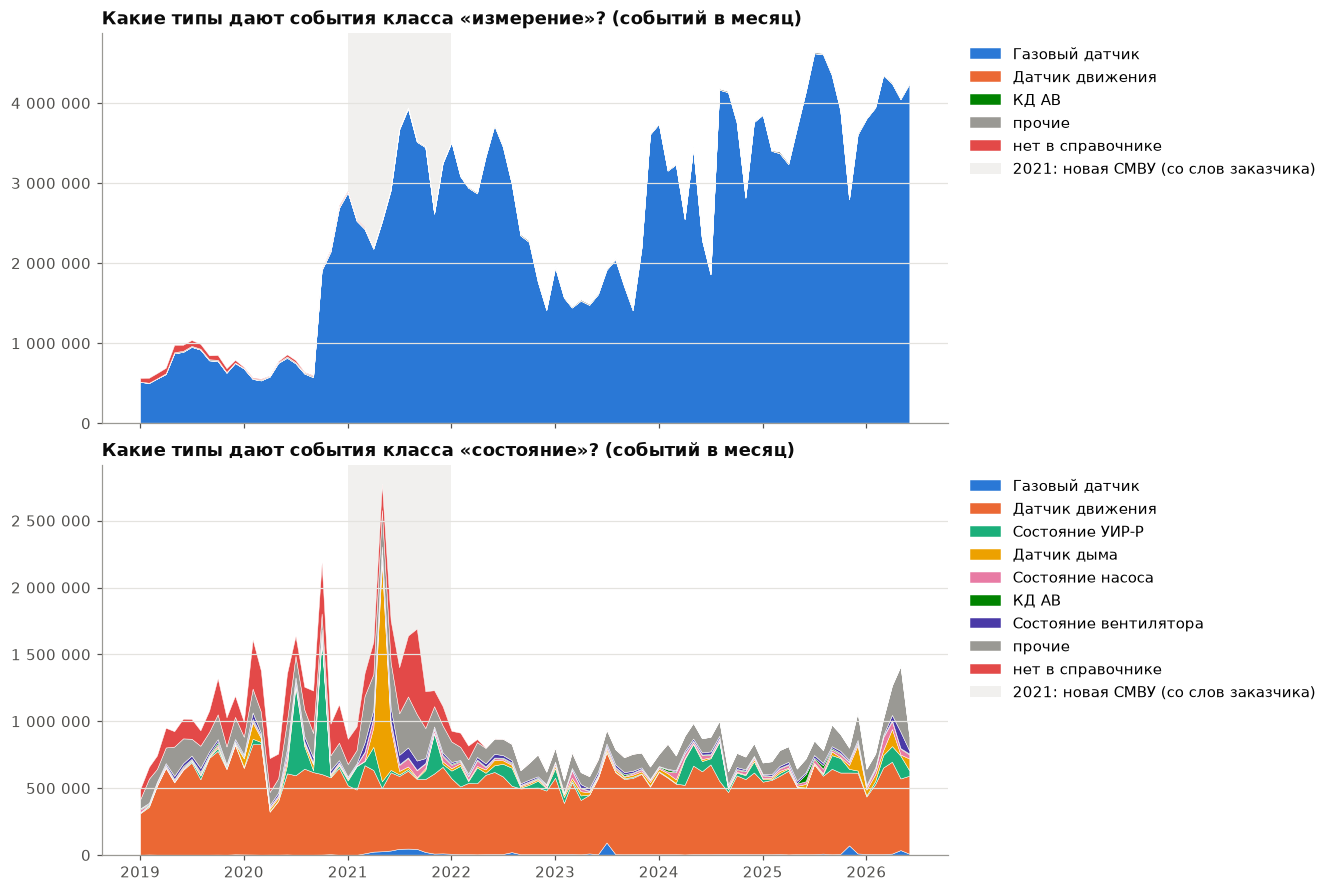

In [11]:
monthly = (hourly.assign(месяц=month_start(hourly["час"]))
           .groupby(["класс_записи", "месяц", "тип_датчика"])[["количество_событий", "количество_тревожных"]].sum())
_tot = hourly[hourly["тип_датчика"] != UNKNOWN].groupby("тип_датчика")[["количество_событий", "количество_тревожных"]].sum()
# Цвет следует за типом во всех графиках: топ-3 по событиям + топ по тревогам (всего 7 «фокусных» типов),
# остальное сворачивается в «прочие», каналы вне справочника – отдельный цвет
FOCUS = list(dict.fromkeys([*_tot["количество_событий"].nlargest(3).index,
                            *_tot["количество_тревожных"].sort_values(ascending=False).index]))[:7]
TYPE_COLOR = {t: PALETTE[i] for i, t in enumerate(FOCUS)} | {UNKNOWN: PALETTE[7], OTHER: GREY}


def fold_types(wide: pd.DataFrame) -> pd.DataFrame:
    """Колонки-типы → фокусные типы + «прочие» + «нет в справочнике» (порядок фиксирован)."""
    keep = [t for t in FOCUS if t in wide.columns]
    rest = [c for c in wide.columns if c not in keep and c != UNKNOWN]
    out = wide[keep].copy()
    out[OTHER] = wide[rest].sum(axis=1)
    if UNKNOWN in wide.columns:
        out[UNKNOWN] = wide[UNKNOWN]
    return out.loc[:, out.sum() > 0]


def plot_lines(ax, wide: pd.DataFrame, **kw):
    for c in wide.columns:
        ax.plot(wide.index, wide[c], color=TYPE_COLOR.get(c), label=c, **kw)


print("фокусные типы:", FOCUS)
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, rc in zip(axes, ["измерение", "состояние"]):
    w = fold_types(monthly.loc[rc, "количество_событий"].unstack(fill_value=0))
    ax.stackplot(w.index, w.T.values, labels=w.columns, colors=[TYPE_COLOR[c] for c in w.columns],
                 edgecolor="white", linewidth=0.3)
    mark_customer_2021(ax)
    thousands(ax)
    ax.set_title(f"Какие типы дают события класса «{rc}»? (событий в месяц)")
    legend_right(ax)
plt.show()

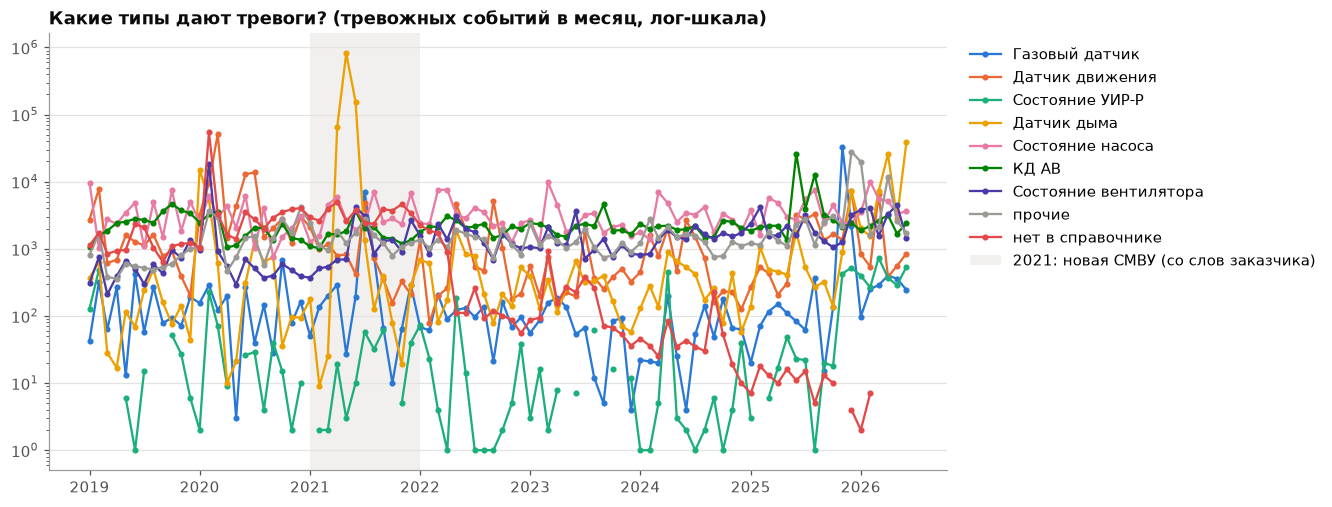

In [12]:
# Тревоги по месяцам и типам: на лог-шкале месяц без тревог – разрыв линии, а не обрыв вниз
alarms_m = fold_types(monthly["количество_тревожных"].groupby(level=["месяц", "тип_датчика"]).sum().unstack(fill_value=0))
fig, ax = plt.subplots()
plot_lines(ax, alarms_m.replace(0, np.nan), marker="o", ms=3)
ax.set_yscale("log")
mark_customer_2021(ax)
ax.set_title("Какие типы дают тревоги? (тревожных событий в месяц, лог-шкала)")
legend_right(ax)
plt.show()

На графике замеров видны ступени, и первая из них – осенью 2020 года, то есть раньше 2021-го, про который
говорит заказчик. После нее уровень замеров держится, дальше есть провалы и новые ступени. Гипотеза: ступени
задает не состояние коллекторов, а режим опроса газа на Альфе. Проверим ее в разделах 4 (частота опроса) и 6
(разбор каждой ступени). На графике тревог в 2021 году выделяется всплеск дыма на два порядка выше обычного,
а в 2025-2026 годах – рост тревог газа, температуры, «КД АВ» и дыма. Первое разберем в разделе 3 вместе
с рассказом заказчика о 2021 годе, второе – в разделах 5 и 6.

**Итог раздела 1.**
- Поток вырос с 20 991 837 событий (2019) до 55 541 796 (2025) почти целиком за счет замеров газа; замеры на
  91,2 % газовые в 2019 году и на 99,2-99,7 % с 2021-го.
- Один объект, Альфа, дает 38-63 % событий года с 2021 года, но лишь 1,7-18,9 % тревог. Суммарный поток и доля
  тревог в нем поэтому описывают в основном опрос одного объекта; дальше тревоги анализируем в абсолютах по
  типам, а объемы – нормированными на число каналов.
- Тревоги – 0,79 % потока. Устойчивое ядро – насосы, «КД АВ», вентиляторы; сверху отдельные всплески
  (дым 2021, движение 2020, газ и температура 2025-2026), каждый из которых надо проверять отдельно.
- Открытые вопросы: что за ступень осенью 2020 года и откуда всплеск дыма 2021 года.

## 2. Покрытие во времени и жизненный цикл каналов
Прежде чем сравнивать периоды, нужно убедиться, что данные покрывают их одинаково: нет ли пустых и неполных дней,
и одни ли и те же каналы пишут в разные годы. Если каналы массово появляются и исчезают, сравнение «в лоб» будет
сравнением разных сетей датчиков.

### 2.1 Пустые и неполные дни

In [13]:
day_tot = hourly.groupby(hourly["час"].dt.floor("D"))["количество_событий"].sum()
full_days = pd.date_range(day_tot.index.min(), day_tot.index.max(), freq="D")
day_tot = day_tot.reindex(full_days, fill_value=0)
print("дни без событий:", [f"{d:%Y-%m-%d}" for d in day_tot.index[day_tot == 0]])

# Неполные дни: меньше 30 % от скользящей медианы за 4 недели
ref = day_tot.rolling(28, center=True, min_periods=7).median()
partial = pd.DataFrame({"событий": day_tot, "медиана_28д": ref})[(day_tot > 0) & (day_tot < 0.3 * ref)]
partial.assign(доля=(partial["событий"] / partial["медиана_28д"]).round(2))

дни без событий: ['2024-04-07', '2024-04-08', '2026-06-01']


,событий,медиана_28д,доля
2020-11-28,28174,124287.0,0.23
2020-11-29,26053,124287.0,0.21
2021-11-28,37590,132762.5,0.28
2024-04-06,4412,136033.0,0.03
2024-04-09,799,136452.0,0.01
2024-04-10,28015,136814.0,0.20
2024-11-09,32242,128715.0,0.25
2024-11-10,31208,128715.0,0.24


In [14]:
# Часы без единого события: по годам и серии подряд длиной от 3 ч
hours_all = pd.date_range(DATA_START, DATA_END + pd.Timedelta(hours=23), freq="h")
h_tot = (hourly.groupby("час")[["количество_событий", "количество_тревожных"]].sum()
         .reindex(hours_all, fill_value=0))
zero = h_tot["количество_событий"].eq(0)
print("часов без событий по годам:", zero.groupby(zero.index.year).sum().to_dict())
zid = (~zero).cumsum()[zero]
gaps_h = (pd.DataFrame({"час": zid.index, "серия": zid.values}).groupby("серия")["час"]
          .agg(с="min", по="max", часов="size").reset_index(drop=True))
gaps_h[gaps_h["часов"] >= 3]

часов без событий по годам: {2019: 0, 2020: 0, 2021: 0, 2022: 0, 2023: 0, 2024: 77, 2025: 0, 2026: 24}


,с,по,часов
0,2024-04-06 02:00:00,2024-04-09 04:00:00,75
3,2026-06-01 00:00:00,2026-06-01 23:00:00,24


Пустых дней три: 2024-04-07, 2024-04-08 и 2026-06-01. Но обрыв апреля 2024 года шире двух дней: 75 часов подряд
без единого события (2024-04-06 02:00 … 2024-04-09 04:00), а сутки 04-06, 04-09 и 04-10 неполные (3 %, 1 % и
20 % обычного уровня). Всего часов без событий 77 в 2024 году и 24 в 2026-м, в остальные годы – ни одного.
Отдельно выделяются неполные дни в конце ноября: 2020-11-28/29 (21-23 % медианы), 2021-11-28 (28 %),
2024-11-09/10 (24-25 %). Повторение в одно и то же время года наводит на мысль о регулярном событии; проверим
в разделе 6, что именно в эти дни замолкает.

### 2.2 Жизненный цикл каналов
Для каждого канала находим первый и последний день с событиями, число активных дней и основной класс записей.
Вопросы: все ли каналы справочника пишут, как долго дискретные каналы молчат, когда каналы появляются и
исчезают.

In [15]:
life = (daily_ch.groupby("ид_канала_данных")
        .agg(первый_день=("день", "min"), последний_день=("день", "max"), активных_дней=("день", "nunique"),
             количество_событий=("количество_событий", "sum"), количество_тревожных=("количество_тревожных", "sum"))
        .reset_index())
main_class = (daily_ch.groupby(["ид_канала_данных", "класс_записи"])["количество_событий"].sum()
              .unstack(fill_value=0).idxmax(axis=1))
life["основной_класс"] = life["ид_канала_данных"].map(main_class)
life = life.merge(channels_pd, on="ид_канала_данных", how="outer")
life["в_справочнике"] = life["ид_канала_данных"].isin(KNOWN_IDS)
life["тип_датчика"] = life["тип_датчика"].fillna(UNKNOWN)
life["не_писал"] = life["первый_день"].isna()
life["дней_жизни"] = (life["последний_день"] - life["первый_день"]).dt.days + 1

print("каналов в справочнике:", life["в_справочнике"].sum(),
      "| никогда не писали:", (life["в_справочнике"] & life["не_писал"]).sum(),
      "| пишут, но нет в справочнике:", (~life["в_справочнике"]).sum())
(life[life["в_справочнике"]].groupby("тип_датчика")["не_писал"].agg(никогда_не_писали="sum", каналов="count")
 .assign(доля=lambda d: (d["никогда_не_писали"] / d["каналов"]).round(3)).sort_values("каналов", ascending=False))

каналов в справочнике: 11485 | никогда не писали: 0 | пишут, но нет в справочнике: 1142


,никогда_не_писали,каналов,доля
тип_датчика,,,
Датчик дыма,0,4337,0.0
Состояние фазы,0,957,0.0
КД Дверь,0,917,0.0
Датчик движения,0,804,0.0
Переключатель,0,801,0.0
Состояние УИР-Р,0,762,0.0
Датчик температуры,0,600,0.0
Газовый датчик,0,529,0.0
Тепловой датчик,0,472,0.0


In [16]:
# Доля дней жизни канала, в которые он писал (для дискретных каналов ожидаемо низкая)
seen = life[~life["не_писал"]]
display(seen.assign(доля_активных_дней=seen["активных_дней"] / seen["дней_жизни"])
        .groupby("тип_датчика")["доля_активных_дней"].describe(percentiles=[.1, .5, .9]).round(3))
# Смешаны ли в одном типе каналы замеров и каналы состояний (основной класс записи канала)
pd.crosstab(seen["тип_датчика"], seen["основной_класс"])

,count,mean,std,min,10%,50%,90%,max
тип_датчика,,,,,,,,
9-секционный люк,9.0,0.083,0.030,0.034,0.034,0.103,0.104,0.104
Газовый датчик,529.0,0.407,0.267,0.026,0.063,0.368,0.797,0.957
Датчик движения,804.0,0.198,0.185,0.026,0.056,0.131,0.421,0.972
Датчик дыма,4337.0,0.073,0.043,0.014,0.028,0.061,0.129,0.295
Датчик затопления,25.0,0.048,0.031,0.022,0.024,0.035,0.089,0.134
Датчик температуры,600.0,0.284,0.201,0.029,0.078,0.222,0.599,0.944
ИБП,80.0,0.101,0.052,0.021,0.041,0.097,0.164,0.270
КД АВ,397.0,0.103,0.068,0.029,0.049,0.083,0.195,0.618
КД Дверь,917.0,0.201,0.165,0.021,0.048,0.158,0.379,0.979


основной_класс,измерение,состояние
тип_датчика,,
9-секционный люк,0,9
Газовый датчик,461,68
Датчик движения,0,804
Датчик дыма,0,4337
Датчик затопления,0,25
Датчик температуры,440,160
ИБП,3,77
КД АВ,0,397
КД Дверь,0,917


Все 11 485 каналов справочника хоть раз писали: «мертвых» каналов в справочнике нет. Еще 1 142 канала пишут,
но в справочник не входят. Дискретные каналы молчат неделями: медиана доли активных дней жизни у дыма 6,1 %,
у тепловых 3,6 %, у УИР-Р 5,3 %, у «КД АВ» 8,3 %. Значит, «нет событий» у такого канала – норма (состояние не
менялось), а не отказ. У газа 36,8 %, потому что тип смешанный: 461 канал замеров и 68 каналов состояний.

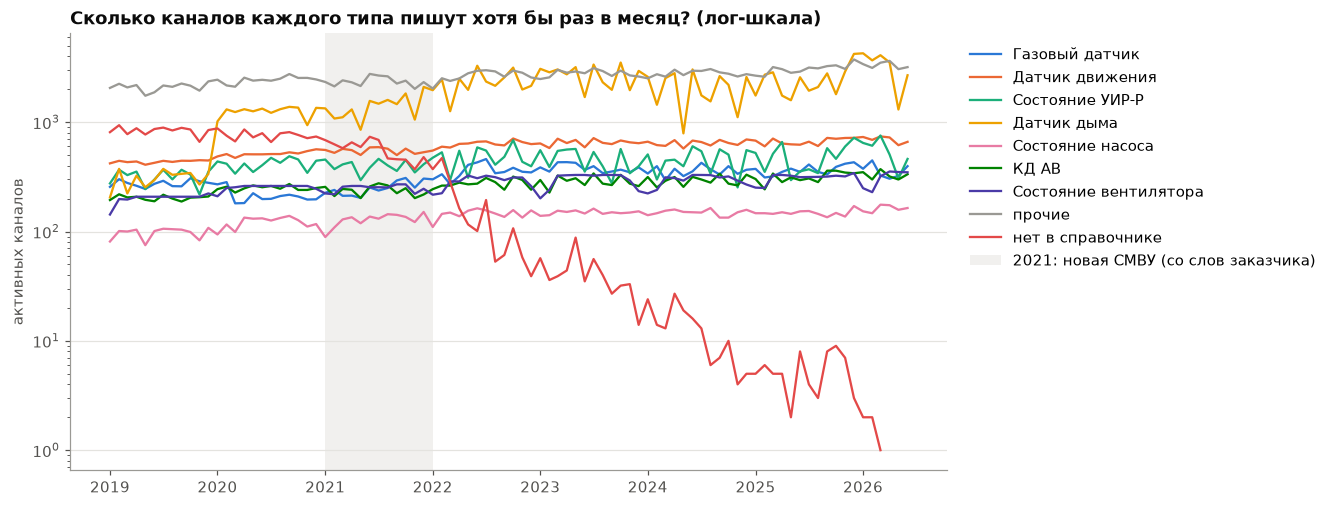

In [17]:
# Активные каналы по месяцам и типам (канал активен, если за месяц было хотя бы одно событие)
monthly_active = (daily_ch.assign(месяц=month_start(daily_ch["день"]))
                  .groupby(["месяц", "тип_датчика"])["ид_канала_данных"].nunique().unstack(fill_value=0))
fig, ax = plt.subplots()
plot_lines(ax, fold_types(monthly_active).replace(0, np.nan))
ax.set_yscale("log")  # типы различаются по числу каналов на два порядка
mark_customer_2021(ax)
ax.set_title("Сколько каналов каждого типа пишут хотя бы раз в месяц? (лог-шкала)")
ax.set_ylabel("активных каналов")
legend_right(ax)
plt.show()

окно цензурирования, сут (p50 / p90 / max): [129.0, 268.2] 2340.2999999999993
исчезли по годам (в справочнике / нет в справочнике):


в_справочнике,False,True
последний_день,,
2019,107,0
2020,183,0
2021,286,0
2022,453,2
2023,78,0
2024,23,1
2025,7,24
2026,2,34


с окном 30 сут считались бы исчезнувшими еще: 3186 каналов


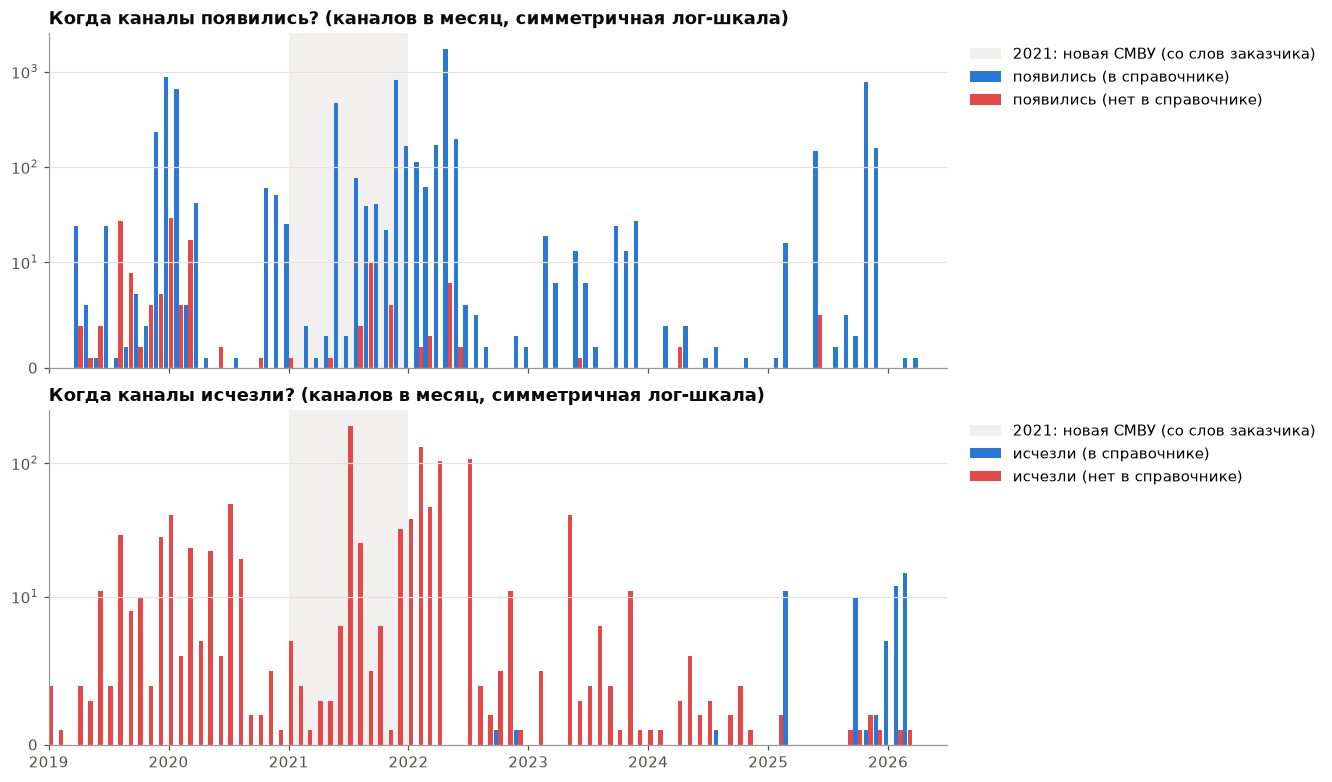

месяцы, где появились или исчезли ≥ 50 каналов:


,появились (в справочнике),появились (нет в справочнике),исчезли (в справочнике),исчезли (нет в справочнике)
2019-12-01,235,7,0,28
2020-01-01,872,29,0,41
2020-02-01,650,6,0,6
2020-11-01,60,0,0,5
2020-12-01,51,0,0,1
2021-06-01,471,0,0,8
2021-07-01,3,0,0,189
2021-08-01,76,4,0,25
2021-12-01,811,0,0,32
2022-01-01,164,0,0,38


In [18]:
# Появления и исчезновения каналов по месяцам. Края данных цензурированы: редкий дискретный канал мог писать до 2019
# года или пишет после 30.06.2026, просто с паузами в месяцы. Поэтому канал «появился» / «исчез», только если от
# начала / до конца данных больше max(90 сут, 3 × p95 паузы между его активными днями); остальные – цензурированы.
act_days = daily_ch[["ид_канала_данных", "день"]].drop_duplicates().sort_values(["ид_канала_данных", "день"])
pause_p95 = (act_days.groupby("ид_канала_данных")["день"].diff().dt.days
             .groupby(act_days["ид_канала_данных"]).quantile(0.95))
life["окно_цензуры_сут"] = np.maximum(90, 3 * life["ид_канала_данных"].map(pause_p95).fillna(0))
births = life.loc[(life["первый_день"] - DATA_START).dt.days > life["окно_цензуры_сут"]]
deaths = life.loc[(DATA_END - life["последний_день"]).dt.days > life["окно_цензуры_сут"]]
print("окно цензурирования, сут (p50 / p90 / max):", life["окно_цензуры_сут"].quantile([.5, .9]).tolist(),
      life["окно_цензуры_сут"].max())
print("исчезли по годам (в справочнике / нет в справочнике):")
display(deaths.groupby([deaths["последний_день"].dt.year, "в_справочнике"]).size().unstack(fill_value=0))
print("с окном 30 сут считались бы исчезнувшими еще:",
      (life["последний_день"].notna() & ~life.index.isin(deaths.index)
       & (life["последний_день"] < DATA_END - pd.Timedelta(days=30))).sum(), "каналов")
bd = pd.DataFrame({
    "появились (в справочнике)": births[births["в_справочнике"]].groupby(month_start(births["первый_день"])).size(),
    "появились (нет в справочнике)": births[~births["в_справочнике"]].groupby(month_start(births["первый_день"])).size(),
    "исчезли (в справочнике)": deaths[deaths["в_справочнике"]].groupby(month_start(deaths["последний_день"])).size(),
    "исчезли (нет в справочнике)": deaths[~deaths["в_справочнике"]].groupby(month_start(deaths["последний_день"])).size(),
}).fillna(0).astype(int)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, kind in zip(axes, ["появились", "исчезли"]):
    for col, color, shift in [(f"{kind} (в справочнике)", PALETTE[0], -7), (f"{kind} (нет в справочнике)", PALETTE[7], 7)]:
        ax.bar(bd.index + pd.Timedelta(days=shift), bd[col], width=13, color=color, label=col)
    ax.set_yscale("symlog", linthresh=10)
    ax.set_xlim(DATA_START, DATA_END)
    mark_customer_2021(ax)
    ax.set_title(f"Когда каналы {kind}? (каналов в месяц, симметричная лог-шкала)")
    legend_right(ax)
plt.show()
print("месяцы, где появились или исчезли ≥ 50 каналов:")
bd[(bd >= 50).any(axis=1)]

Окно цензурирования индивидуальное: медиана 129 сут, p90 268 сут. С единым окном в 30 дней «исчезнувшими»
ошибочно считались бы еще 3 186 каналов, в основном редкие дискретные.
- **Каналы справочника появляются волнами:** декабрь 2019 – февраль 2020 (235 + 872 + 650), июнь 2021 (471),
  декабрь 2021 (811), май 2022 (1 715), ноябрь 2025 (776).
- **Каналы справочника почти не исчезают:** 2 в 2022 году, 1 в 2024-м, 24 в 2025-м и 34 в первом полугодии
  2026-го. Справочник – снимок текущей сети.
- **Каналы вне справочника исчезают волнами** в июле 2021 (189), затем в феврале (133), апреле (104) и июле
  2022 года (108).

Волны июня 2021 года и исчезновения каналов вне справочника в 2021-2022 годах по времени близки к внедрению
новой СМВУ, о котором говорит заказчик. Связаны ли они с ним, проверим в разделе 3, когда найдем границы
переходного периода.

### 2.3 Повторяющиеся названия на одном объекте
В справочнике на одном объекте встречаются каналы с одинаковым названием. Возможных объяснений четыре, и они
дают разные следы в данных:
- **замена оборудования** – старый канал перестает писать, новый с тем же названием начинает: группы будут
  «последовательными»;
- **несколько каналов одного устройства** (например, состояние и управление) – каналы живут параллельно
  и имеют разные типы;
- **смена классификации** – последовательные группы с разными типами;
- **несколько одинаковых датчиков в одной точке** – параллельные однотипные группы.

Группа – каналы справочника с одинаковыми (объект, название), которые хоть раз писали. Ограничение: у каналов вне
справочника нет названия и объекта, поэтому замену «канал вне справочника → канал справочника» здесь не увидеть.

In [19]:
def chain_stats(g: pd.DataFrame) -> pd.Series:
    g = g.sort_values(["первый_день", "последний_день"])
    prev_last = g["последний_день"].cummax().shift()
    seq = bool((g["первый_день"] > prev_last).iloc[1:].all())
    return pd.Series({
        "число_каналов": len(g), "последовательная": seq,
        "день_смены": g["первый_день"].iloc[1] if seq else pd.NaT,
        "разрыв_сут": (g["первый_день"].iloc[1] - g["последний_день"].iloc[0]).days if seq else np.nan,
        "типы": tuple(sorted(g["тип_датчика"].unique())),
        # пересечение жизни всех каналов группы (сут; < 0 – есть разрыв) и «все начали в один день»
        "пересечение_сут": (g["последний_день"].min() - g["первый_день"].max()).days + 1,
        "общий_старт": g["первый_день"].nunique() == 1,
    })


KEY = ["ид_объект", "название_датчика"]
dup = life[life["в_справочнике"] & ~life["не_писал"]]
dup = dup[dup.duplicated(KEY, keep=False)]
pairs = dup.groupby(KEY)[["первый_день", "последний_день", "тип_датчика"]].apply(chain_stats).reset_index()
pairs = pairs.astype({"число_каналов": int, "последовательная": bool, "разрыв_сут": float, "пересечение_сут": int,
                      "общий_старт": bool})
pairs["день_смены"] = pd.to_datetime(pairs["день_смены"])
pairs["разные_типы"] = pairs["типы"].map(len) > 1
print("групп с повтором названия:", len(pairs), "| каналов в них:", pairs["число_каналов"].sum())
pd.crosstab(pairs["последовательная"], pairs["разные_типы"], margins=True).rename(
    index={True: "последовательные", False: "параллельные"}, columns={True: "разные типы", False: "один тип"})

групп с повтором названия: 442 | каналов в них: 1096


разные_типы,один тип,разные типы,All
последовательная,,,
параллельные,412,30,442
All,412,30,442


In [20]:
# Какие комбинации типов встречаются в параллельных и последовательных группах
pairs.groupby("последовательная")["типы"].value_counts().groupby(level=0).head(10)

последовательная  типы                                  
False             (Датчик дыма,)                            296
                  (Тепловой датчик,)                         40
                  (Датчик температуры,)                      37
                  (КД Дверь,)                                15
                  (Переключатель, Состояние вентилятора)     15
                  (Переключатель, Состояние фазы)            15
                  (Состояние УИР-Р,)                          7
                  (Состояние насоса,)                         6
                  (Датчик движения,)                          5
                  (9-секционный люк,)                         3
Name: count, dtype: int64

In [21]:
# Последовательные группы: когда и с каким разрывом. Если их нет – насколько пересекаются жизни каналов в группе
# и как часто все каналы группы начинают писать в один день
seq_pairs = pairs[pairs["последовательная"]]
print(f"последовательных групп: {len(seq_pairs)} из {len(pairs)}")
if len(seq_pairs):
    display(seq_pairs["разрыв_сут"].describe(percentiles=[.1, .5, .9]))
    display(seq_pairs.groupby(month_start(seq_pairs["день_смены"])).size().rename("переключений"))
print(f"все каналы группы начали писать в один день: {pairs['общий_старт'].mean():.1%} групп")
pairs["пересечение_сут"].describe(percentiles=[.05, .25, .5, .75]).rename("пересечение жизни каналов группы, сут")

последовательных групп: 0 из 442
все каналы группы начали писать в один день: 85.5% групп


count     442.000000
mean     1838.642534
std       769.896703
min       149.000000
5%        149.050000
25%      1480.000000
50%      1651.000000
75%      2697.750000
max      2737.000000
Name: пересечение жизни каналов группы, сут, dtype: float64

Результат однозначный. Последовательных групп 0 из 442: жизни каналов одной группы пересекаются минимум на 149
суток (медиана 1 651), и в 85,5 % групп все каналы начали писать в один день. Значит:
- **замена оборудования** внутри справочника не подтверждается;
- **смена классификации** тоже (последовательных разнотипных групп нет);
- **несколько каналов одного устройства** подтверждается для 30 групп: «Переключатель + Состояние вентилятора»
  (15) и «Переключатель + Состояние фазы» (15) – у вентилятора или фидера есть канал состояния и канал управления;
- остальные 412 групп однотипные и параллельные: **несколько одинаковых датчиков в одной точке** (296 групп
  дымовых, 40 тепловых, 37 температурных). Одинаковое название на объекте – это метка места (пикет), а не
  идентификатор устройства.

In [22]:
# Диапазоны ид_канала_данных по кварталу первого появления: новые каналы получают новые ID?
(life[~life["не_писал"]]
 .assign(квартал_появления=lambda d: d["первый_день"].dt.to_period("Q"),
         группа=lambda d: np.where(d["в_справочнике"], "в справочнике", UNKNOWN))
 .groupby(["квартал_появления", "группа"])["ид_канала_данных"].agg(["count", "min", "median", "max"])
 .unstack("группа"))

count                             min                          median                             max                  
группа            в справочнике нет в справочнике в справочнике нет в справочнике в справочнике нет в справочнике в справочнике нет в справочнике
квартал_появления                                                                                                                                
2019Q1                   4292.0             943.0        2866.0            2867.0      120688.5          143524.0      217386.0          219882.0
2019Q2                     49.0              10.0       93756.0          100504.0      212276.0          223033.5      223567.0          223576.0
2019Q3                     29.0              36.0      103988.0          143572.0      104050.0          224436.5      224475.0          224700.0
2019Q4                    248.0              15.0      104004.0          196693.0      229606.5          226795.0      230701.0          229710.0
2020Q1                   1528.0              90.0      143616.0          143529.0      229093.5          230684.5      236719.0          236720.0
2020Q2                     51.0               2.0      236727.0          244702.0      236763.0          244707.0      236795.0          244712.0
2020Q3                      1.0               NaN      245555.0               NaN      245555.0               NaN      245555.0               NaN
2020Q4                    111.0               1.0       77708.0          247493.0      230810.0          247493.0      251516.0          247493.0
2021Q1                     29.0               1.0      162774.0          251572.0      230841.0          251572.0      255335.0          251572.0
2021Q2                    475.0               1.0      256139.0          250747.0      262120.0          250747.0      262737.0          250747.0
2021Q3                    118.0              14.0      212474.0           50818.0      230904.5          105786.5      262948.0          245474.0
2021Q4                    877.0               6.0      171375.0           50873.0      267975.0          263423.5      269766.0          263426.0
2022Q1                    339.0               5.0      266604.0          266773.0      269459.0          278035.0      278336.0          278057.0
2022Q2                   2086.0              10.0        8776.0          267935.0      287083.5          286965.5      289253.0          287888.0
2022Q3                     13.0               NaN       93718.0               NaN      267001.0               NaN      290855.0               NaN
2022Q4                      3.0               NaN      298483.0               NaN      298484.0               NaN      298485.0               NaN
2023Q1                     21.0               NaN      267016.0               NaN      302190.0               NaN      302200.0               NaN
2023Q2                     21.0               1.0      245476.0          305211.0      305212.0          305211.0      305222.0          305211.0
2023Q3                     10.0               NaN      245479.0               NaN      245484.5               NaN      308077.0               NaN
2023Q4                     64.0               NaN       51139.0               NaN      171621.5               NaN      314387.0               NaN
2024Q1                      4.0               NaN      316137.0               NaN      316155.5               NaN      316174.0               NaN
2024Q2                      4.0               2.0       47585.0          319099.0       47853.0          319099.5       48121.0          319100.0
2024Q3                      3.0               NaN      297164.0               NaN      297165.0               NaN      321167.0               NaN
2024Q4                      1.0               NaN      321855.0               NaN      321855.0               NaN      321855.0               NaN
2025Q1                     17.0               NaN      143513.0               NaN   

Новые каналы получают новые, большие ID: 256 139-262 737 в 2021Q2, медиана 287 084 в 2022Q2, 330 498-334 938
в 2025Q4. Номер канала грубо кодирует «поколение» установки.

### 2.4 Каналы вне справочника по годам
В разделе 0 видно, что доля событий вне справочника резко падает в 2021-2022 годах. Сколько это каналов и
тревог? Сверяем с отчетом очистки, где та же величина посчитана по годовым файлам.

In [23]:
unk_year = (daily_ch.groupby(["год", "в_справочнике"])
            .agg(строк=("количество_событий", "sum"), тревог=("количество_тревожных", "sum"),
                 каналов=("ид_канала_данных", "nunique"))
            .unstack("в_справочнике", fill_value=0))
unk_share = pd.DataFrame({
    "строк вне справочника": unk_year[("строк", False)],
    "доля строк": (unk_year[("строк", False)] / unk_year["строк"].sum(axis=1)).round(4),
    "каналов вне справочника": unk_year[("каналов", False)],
    "доля каналов": (unk_year[("каналов", False)] / unk_year["каналов"].sum(axis=1)).round(4),
    "тревог вне справочника": unk_year[("тревог", False)],
})
display(unk_share)
# Сверка с отчетом очистки (там год файла, а не год события: строки на стыке лет могут разойтись)
etl_report.set_index("год_файла")[["строк_после_очистки", "строк_каналов_вне_справочника"]].assign(
    доля=lambda d: (d["строк_каналов_вне_справочника"] / d["строк_после_очистки"]).round(4))

,строк вне справочника,доля строк,каналов вне справочника,доля каналов,тревог вне справочника
год,,,,,
2019,2481504,0.1182,1004,0.1786,15173
2020,3278453,0.1164,990,0.1366,84246
2021,3323693,0.0619,829,0.0961,41221
2022,328990,0.0076,558,0.0520,7660
2023,21106,0.0007,106,0.0102,2624
2024,5257,0.0001,30,0.0029,641
2025,530,0.0000,12,0.0010,122
2026,122,0.0000,2,0.0002,9


,строк_после_очистки,строк_каналов_вне_справочника,доля
год_файла,,,
2019,20991837,2481504,0.1182
2020,28172398,3278453,0.1164
2021,53698948,3323693,0.0619
2022,43483149,328990,0.0076
2023,31374676,21106,0.0007
2024,49023883,5257,0.0001
2025,55541796,530,0.0000
2026,30695389,122,0.0000


Каналов вне справочника 1 004 (11,82 % строк) в 2019 году, 990 (11,64 %) в 2020-м, 829 (6,19 %) в 2021-м, 558
(0,76 %) в 2022-м, 106 (0,07 %) в 2023-м, дальше 30 → 12 → 2. Тревог у них 15 173, 84 246, 41 221 и 7 660 в
2019-2022 годах. Цифры совпадают с отчетом очистки. **Гипотеза:** справочник – снимок текущей (новой) СМВУ,
а каналы вне справочника – каналы старой системы, которые исчезли при переходе 2021 года. Проверим ее в
разделе 3.7.

**Итог раздела 2.**
- Данные непрерывны, кроме обрыва 2024-04-06 02:00 … 2024-04-09 04:00 (75 часов), пустого дня 2026-06-01 и
  неполных ноябрьских дней 2020, 2021 и 2024 годов (их природу выясним в разделе 6).
- Все каналы справочника пишут, почти никто из них не исчезает; дискретные каналы молчат неделями, и это норма.
- Одноименные каналы на объекте – параллельные датчики одной точки, а не цепочки замен.
- Каналы подключаются волнами; каналы вне справочника дают до 12 % событий и до 84 тыс. тревог в год
  в 2019-2021 годах и уходят в 2021-2023 годах.

## 3. Внедрение новой СМВУ в 2021 году
**Что говорит заказчик.** В 2021 году внедрялась новая СМВУ. Какое-то время старая и новая системы работали
параллельно, операторы не могли полноценно работать в обеих, и много тревог оставалось неснятыми.

Если это так, в данных должно быть видно:
1. период с четкими началом и концом, в котором данные ведут себя иначе (две системы пишут в один журнал –
   скачок потока, возможно, дубли);
2. в этом периоде аномально много тревог, и если их не снимали – длинные, незакрытые тревоги;
3. после перехода – изменения в устройстве данных: другие каналы, их ID, словарь состояний, уровень потока.

Уже есть две зацепки: в 2021 году доля тревожных событий в 1,9-9,7 раза выше, чем в остальные годы (раздел 0),
и на графике тревог 2021 года выделяется всплеск дыма (раздел 1). Сначала находим границы периода по данным,
потом проверяем остальное.

### 3.1 Границы периода
**Начало.** Если в журнал начала писать вторая система, у потока должен появиться новый устойчивый уровень.
Почасовой ряд для этого слишком шумный: в нем суточный и недельный ритм и короткие провалы, после которых поток
возвращается к прежнему уровню. Поэтому сначала ищем день: для каждого дня 2021 года сравниваем медиану суточного
потока за следующие 7 дней с медианой за предыдущие 28 дней. Отношение больше 1 – новый уровень выше прежнего,
меньше 1 – ниже.

In [24]:
tot_h = h_tot["количество_событий"]
d_win = day_tot.loc["2020-11-01":"2022-01-31"]
prev28 = d_win.rolling(28).median().shift(1)        # медиана суток [t-28, t-1]
next7 = d_win[::-1].rolling(7).median()[::-1]       # медиана суток [t, t+6]
lvl_ratio = (next7 / prev28).loc["2021-01-01":"2021-12-31"]
cands = []
for t_, _ in np.log2(lvl_ratio).abs().sort_values(ascending=False).items():
    if all(abs(t_ - c) > pd.Timedelta(days=7) for c in cands):
        cands.append(t_)
    if len(cands) == 6:
        break
steps = pd.DataFrame({"медиана_28_сут_до": prev28[cands], "медиана_7_сут_после": next7[cands],
                      "отношение": lvl_ratio[cands].round(3)}).sort_index()
step_day = lvl_ratio.idxmax()
print(f"день наибольшего устойчивого роста уровня: {step_day:%Y-%m-%d} (×{lvl_ratio.max():.3f})")
steps

день наибольшего устойчивого роста уровня: 2021-04-22 (×1.350)


,медиана_28_сут_до,медиана_7_сут_после,отношение
2021-01-01,124875.0,98222.0,0.787
2021-04-23,119177.5,160900.0,1.350
2021-05-08,133216.5,178690.0,1.341
2021-05-16,148799.0,193866.0,1.303
2021-06-08,182033.0,142615.0,0.783
2021-11-25,150893.5,66886.0,0.443


Самый сильный устойчивый рост уровня в 2021 году – с 22-23 апреля: медиана суток 119 178 → 160 900 событий
(×1,35; в таблице кандидат записан 23-м числом, у 22-го то же отношение). Два следующих кандидата вверх (8 и 16 мая)
лежат уже внутри нового режима: поток продолжает расти (почему – в 3.2 и 3.3). Ступени вниз – новогодние
праздники (1 января), 8 июня (×0,783, к нему вернемся, когда будем искать конец) и молчание газа одного объекта в конце ноября
(раздел 6). Теперь находим час внутри дня: в почасовом ряду рядом с 22 апреля ищем час с наибольшим отношением
медианы следующих 24 часов к медиане предыдущих 24, а затем уточняем момент по минутам. Для этого считаем события
каждой минуты за три часа до и после этого часа и ищем первую минуту, с которой медиана следующих 15 минут выше
середины между уровнями «до» и «после».

In [25]:
h21 = tot_h.loc["2021-01-01":"2021-12-31 23:00"]
prev24 = h21.rolling(24).median().shift(1)          # медиана часов [h-24, h-1]
next24 = h21[::-1].rolling(24).median()[::-1]       # медиана часов [h, h+23]
step_h = (next24 / prev24).loc[step_day - pd.Timedelta(days=2):step_day + pd.Timedelta(days=2)]
h_star = step_h.idxmax()
lo, hi = h_star - pd.Timedelta(hours=3), h_star + pd.Timedelta(hours=3)
pm = (events.filter((F.col("год") == lo.year) & F.col("месяц").isin(lo.month, hi.month)
                    & (F.col("дата_время") >= F.lit(lo.to_pydatetime())) & (F.col("дата_время") < F.lit(hi.to_pydatetime())))
      .groupBy(F.date_trunc("minute", "дата_время").alias("минута")).count().toPandas())
pm = pm.set_index("минута")["count"].reindex(pd.date_range(lo, hi, freq="min", inclusive="left"), fill_value=0)
level_before = pm.loc[:h_star - pd.Timedelta(hours=1, minutes=1)].median()
level_after = pm.loc[h_star + pd.Timedelta(hours=1):].median()
mid = (level_before + level_after) / 2
fwd15 = pm[::-1].rolling(15).median()[::-1]   # медиана минут [m, m+14]
jump_minute = fwd15[fwd15 > mid].index.min()
T0_found = jump_minute.floor("h")
print(f"час наибольшей ступени вверх: {h_star} (×{step_h.max():.2f} за 24 ч); событий в минуту до: {level_before:.0f}, после: {level_after:.0f}")
print(f"первая минута нового уровня: {jump_minute}; начало периода на почасовой сетке: {T0_found}")
pm.resample("10min").sum().loc[jump_minute - pd.Timedelta(hours=1):jump_minute + pd.Timedelta(hours=1)].to_frame("событий за 10 мин").T

час наибольшей ступени вверх: 2021-04-22 08:00:00 (×1.70 за 24 ч); событий в минуту до: 50, после: 135
первая минута нового уровня: 2021-04-22 07:38:00; начало периода на почасовой сетке: 2021-04-22 07:00:00


,2021-04-22 06:40:00,2021-04-22 06:50:00,2021-04-22 07:00:00,2021-04-22 07:10:00,2021-04-22 07:20:00,2021-04-22 07:30:00,2021-04-22 07:40:00,2021-04-22 07:50:00,2021-04-22 08:00:00,2021-04-22 08:10:00,2021-04-22 08:20:00,2021-04-22 08:30:00
событий за 10 мин,740,458,806,563,529,658,1157,1130,1361,1586,1538,1813


In [26]:
# Из чего состоит скачок: события в час по типам и классам за 3 часа до и после первого часа нового уровня
jw = window(hourly, T0_found - pd.Timedelta(hours=3), T0_found + pd.Timedelta(hours=4), col="час")
jt = jw.pivot_table(index=["тип_датчика", "класс_записи"], columns="час", values="количество_событий",
                    aggfunc="sum", fill_value=0)
jt["прирост"] = jt.loc[:, T0_found + pd.Timedelta(hours=1):].mean(axis=1) - jt.loc[:, :T0_found - pd.Timedelta(hours=1)].mean(axis=1)
jt.sort_values("прирост", key=abs, ascending=False).head(8)

,час,2021-04-22 04:00:00,2021-04-22 05:00:00,2021-04-22 06:00:00,2021-04-22 07:00:00,2021-04-22 08:00:00,2021-04-22 09:00:00,2021-04-22 10:00:00,прирост
тип_датчика,класс_записи,,,,,,,,
Датчик движения,состояние,0,0,8,951,3406,3446,2981,3275.000000
нет в справочнике,состояние,131,140,380,387,536,956,1235,692.000000
Датчик дыма,состояние,0,2,0,0,213,704,573,496.000000
КД Дверь,состояние,0,0,14,113,362,480,435,421.000000
Состояние вентилятора,состояние,48,28,76,133,872,131,48,299.666667
Газовый датчик,измерение,2926,2840,2924,2727,3190,2813,3105,139.333333
Переключатель,состояние,128,76,190,221,476,116,112,103.333333
Состояние УИР-Р,состояние,0,0,8,0,3,51,167,71.000000


Новый уровень начинается 22 апреля в 07:38: до этого в минуту приходило около 50 событий, после – около 135,
а в часы 07:00 и 08:00 – 4 843 и 9 574 событий против 2 789-4 000 в предыдущие часы. На почасовой сетке начало
периода – 07:00, первый час, в котором уже есть события нового режима. Из чего состоит скачок, видно в таблице:
до 06:00 записей состояния «Датчика движения» не было вовсе, в 07:00 их 951, с 08:00 – 3 400 в час; добавились
состояния каналов вне справочника (+692 в час), «КД Двери» (+421) и дымовых датчиков (213 в 08:00, 704 в 09:00 –
еще без тревог). Замеры газа не изменились. То есть в журнал разом пошли потоки состояний, которых раньше не было.
Это согласуется с версией заказчика о подключении второй системы, но прямо ее не доказывает.

**Конец.** По суткам поток с 8 июня заметно ниже прежнего (×0,783 в таблице выше), но сама по себе эта ступень
не говорит, что именно перестало писать. Главная зацепка – всплеск тревог дыма 2021 года. Проверим, какие типы дают избыток тревог весной 2021 года и где он кончается.
Порог «аномального» часа для каждого типа – 99-й перцентиль почасовых тревог типа в январе-марте 2021 года
(но не меньше 1). Для каждого типа смотрим первый и последний аномальный час, их 5-й и 95-й перцентили и самую
длинную серию аномальных часов подряд.

In [27]:
hours_21 = pd.date_range("2021-01-01", "2021-08-01", freq="h", inclusive="left")
a21 = (window(hourly, "2021-01-01", "2021-08-01", col="час")
       .pivot_table(index="час", columns="тип_датчика", values="количество_тревожных", aggfunc="sum", fill_value=0)
       .reindex(hours_21, fill_value=0))
thr = a21.loc[:"2021-03-31"].quantile(0.99).clip(lower=1)
excess = a21.loc["2021-03-01":] > thr


def longest_run(mask: pd.Series):
    """Самая длинная серия True подряд: (начало, конец – первый час после серии, длина в часах)."""
    ids = (~mask).cumsum()[mask]
    if ids.empty:
        return pd.NaT, pd.NaT, 0
    size = ids.value_counts()
    hrs = ids.index[ids == size.idxmax()]
    return hrs.min(), hrs.max() + pd.Timedelta(hours=1), int(size.max())


rows = {}
for t in a21.columns:
    h = excess.index[excess[t].values]
    if len(h):
        rs, re_, rl = longest_run(excess[t])
        rows[t] = {"порог_q99": thr[t], "аномальных_часов": len(h), "первый": h.min(),
                   "q05": h[int(0.05 * (len(h) - 1))], "q95": h[int(0.95 * (len(h) - 1))], "последний": h.max(),
                   "серия_ч": rl, "серия_с": rs, "серия_по": re_}
bounds = pd.DataFrame(rows).T.sort_values("аномальных_часов", ascending=False)
bounds

,порог_q99,аномальных_часов,первый,q05,q95,последний,серия_ч,серия_с,серия_по
Датчик дыма,1.0,1316,2021-03-04 13:00:00,2021-04-25 08:00:00,2021-07-14 13:00:00,2021-07-30 14:00:00,1107,2021-04-23 07:00:00,2021-06-08 10:00:00
ИБП,4.0,95,2021-03-01 21:00:00,2021-04-01 23:00:00,2021-07-21 12:00:00,2021-07-30 15:00:00,5,2021-06-23 19:00:00,2021-06-24 00:00:00
КД АВ,20.0,92,2021-03-11 19:00:00,2021-03-17 11:00:00,2021-07-19 11:00:00,2021-07-28 12:00:00,6,2021-06-17 10:00:00,2021-06-17 16:00:00
нет в справочнике,22.41,76,2021-03-04 10:00:00,2021-04-01 16:00:00,2021-07-08 15:00:00,2021-07-21 11:00:00,5,2021-06-05 04:00:00,2021-06-05 09:00:00
Состояние фазы,2.0,73,2021-03-10 17:00:00,2021-03-26 09:00:00,2021-07-22 14:00:00,2021-07-31 10:00:00,3,2021-05-14 09:00:00,2021-05-14 12:00:00
Состояние насоса,34.82,50,2021-03-01 12:00:00,2021-03-07 03:00:00,2021-07-19 11:00:00,2021-07-30 16:00:00,4,2021-03-18 09:00:00,2021-03-18 13:00:00
Датчик движения,44.0,46,2021-03-26 17:00:00,2021-03-27 15:00:00,2021-07-31 11:00:00,2021-07-31 15:00:00,5,2021-07-27 09:00:00,2021-07-27 14:00:00
Газовый датчик,2.41,45,2021-03-16 09:00:00,2021-03-18 10:00:00,2021-07-22 16:00:00,2021-07-30 16:00:00,4,2021-04-19 09:00:00,2021-04-19 13:00:00
КД Люк,1.0,41,2021-03-02 09:00:00,2021-03-16 11:00:00,2021-07-12 11:00:00,2021-07-15 10:00:00,3,2021-04-26 11:00:00,2021-04-26 14:00:00
Датчик температуры,3.0,35,2021-03-10 05:00:00,2021-03-10 07:00:00,2021-07-22 16:00:00,2021-07-22 18:00:00,4,2021-06-06 18:00:00,2021-06-06 22:00:00


Устойчивая серия аномальных часов есть только у «Датчика дыма» (1 107 часов подряд); у остальных типов самая
длинная серия не больше 6 часов. Порог у дыма обрезан до 1 тревоги в час, поэтому «первый / последний / q05 /
q95» цепляют одиночные тревоги вне полосы. Надежнее второй критерий: полоса – это часы, где тревог дыма больше 50
в час 24 часа подряд.

In [28]:
sm = a21["Датчик дыма"]
sus = sm.rolling(24).min().shift(-23) > 50            # True: этот час и 23 следующих выше 50
band_start, last_win = sus[sus].index.min(), sus[sus].index.max()
after_band = sm.loc[last_win:]
band_end = after_band[after_band <= 50].index.min()   # первый час после полосы
T1_found = band_end
run_s, run_e, run_len = longest_run(excess["Датчик дыма"])
print(f"полоса тревог дыма (> 50 в час): {band_start} … {band_end} (первый час после полосы)")
print(f"самая длинная серия часов выше порога q99: {run_s} … {run_e}, {run_len} ч")
smoke_ids = channels_pd.loc[channels_pd["тип_датчика"] == "Датчик дыма", "ид_канала_данных"].tolist()
last_alarm = (events.filter((F.col("год") == 2021) & (F.col("месяц") == band_end.month) & F.col("тревожное")
                            & F.col("ид_канала_данных").isin(smoke_ids)
                            & (F.col("дата_время") < F.lit(band_end.to_pydatetime()))
                            & (F.col("дата_время") >= F.lit((band_end - pd.Timedelta(hours=2)).to_pydatetime())))
              .agg(F.max("дата_время")).first()[0])
print(f"последняя тревога дыма перед концом полосы: {last_alarm}")
edges = pd.DataFrame({"событий": tot_h, "тревог дыма": sm})
display(edges.loc[band_start - pd.Timedelta(hours=2):band_start + pd.Timedelta(hours=2)].T)
edges.loc[band_end - pd.Timedelta(hours=5):band_end + pd.Timedelta(hours=2)].T

полоса тревог дыма (> 50 в час): 2021-04-23 07:00:00 … 2021-06-08 10:00:00 (первый час после полосы)
самая длинная серия часов выше порога q99: 2021-04-23 07:00:00 … 2021-06-08 10:00:00, 1107 ч


последняя тревога дыма перед концом полосы: 2021-06-08 09:57:38


,2021-04-23 05:00:00,2021-04-23 06:00:00,2021-04-23 07:00:00,2021-04-23 08:00:00,2021-04-23 09:00:00
событий,7346.0,5926.0,8217.0,10584.0,9878.0
тревог дыма,0.0,0.0,81.0,266.0,359.0


,2021-06-08 05:00:00,2021-06-08 06:00:00,2021-06-08 07:00:00,2021-06-08 08:00:00,2021-06-08 09:00:00,2021-06-08 10:00:00,2021-06-08 11:00:00,2021-06-08 12:00:00
событий,5768.0,6068.0,8273.0,9556.0,10712.0,10462.0,11253.0,9012.0
тревог дыма,658.0,792.0,730.0,789.0,617.0,0.0,0.0,0.0


Оба критерия дают одну и ту же полосу: тревоги дыма идут сплошь с 2021-04-23 07:00 до 2021-06-08 10:00 (последний
час полосы 09:00 – 617 тревог, в 10:00 – ни одной; последняя тревога – в 09:57:38). Полоса начинается ровно через
сутки после скачка потока (сами дымовые датчики начали писать состояния уже 22-го в 08:00) и обрывается сразу. Конец полосы мы и принимаем за конец переходного периода. Это наше решение: дату
отключения старой системы журнал не хранит, и подтвердить ее может только заказчик.

**Проверка.** Дальше в проекте период перехода задается константами `annanas.smvu`. Сверяем их с найденными
границами.

In [29]:
check = pd.DataFrame({"найдено в данных": [T0_found, T1_found],
                      "annanas.smvu": [pd.Timestamp(smvu.ПЕРЕХОД_НАЧАЛО), pd.Timestamp(smvu.ПЕРЕХОД_КОНЕЦ)]},
                     index=["начало перехода", "конец перехода"])
check["совпадает"] = check["найдено в данных"] == check["annanas.smvu"]
display(check)
assert check["совпадает"].all(), "границы в annanas.smvu разошлись с найденными в данных"
T0, T1 = T0_found, T1_found
print(f"границы, которые используем дальше, совпадают с найденными: [{T0}, {T1}), {(T1 - T0) / pd.Timedelta(days=1):.1f} сут")

,найдено в данных,annanas.smvu,совпадает
начало перехода,2021-04-22 07:00:00,2021-04-22 07:00:00,True
конец перехода,2021-06-08 10:00:00,2021-06-08 10:00:00,True


границы, которые используем дальше, совпадают с найденными: [2021-04-22 07:00:00, 2021-06-08 10:00:00), 47.1 сут


Границы совпадают. С этого места у каждого события есть период СМВУ: `до` (раньше T0), `переход` ([T0, T1)) и
`после` (T1 и позже), а на графиках по времени переход закрашен серым.

доля перехода в окне март-июль 2021: 30.8%


,аномальных_часов,серия_ч,доля_внутри_перехода
Датчик дыма,1316,1107,0.844
ИБП,95,5,0.389
КД АВ,92,6,0.283
нет в справочнике,76,5,0.382
Состояние фазы,73,3,0.384
Состояние насоса,50,4,0.200
Датчик движения,46,5,0.065
Газовый датчик,45,4,0.200
КД Люк,41,3,0.244
Датчик температуры,35,4,0.286


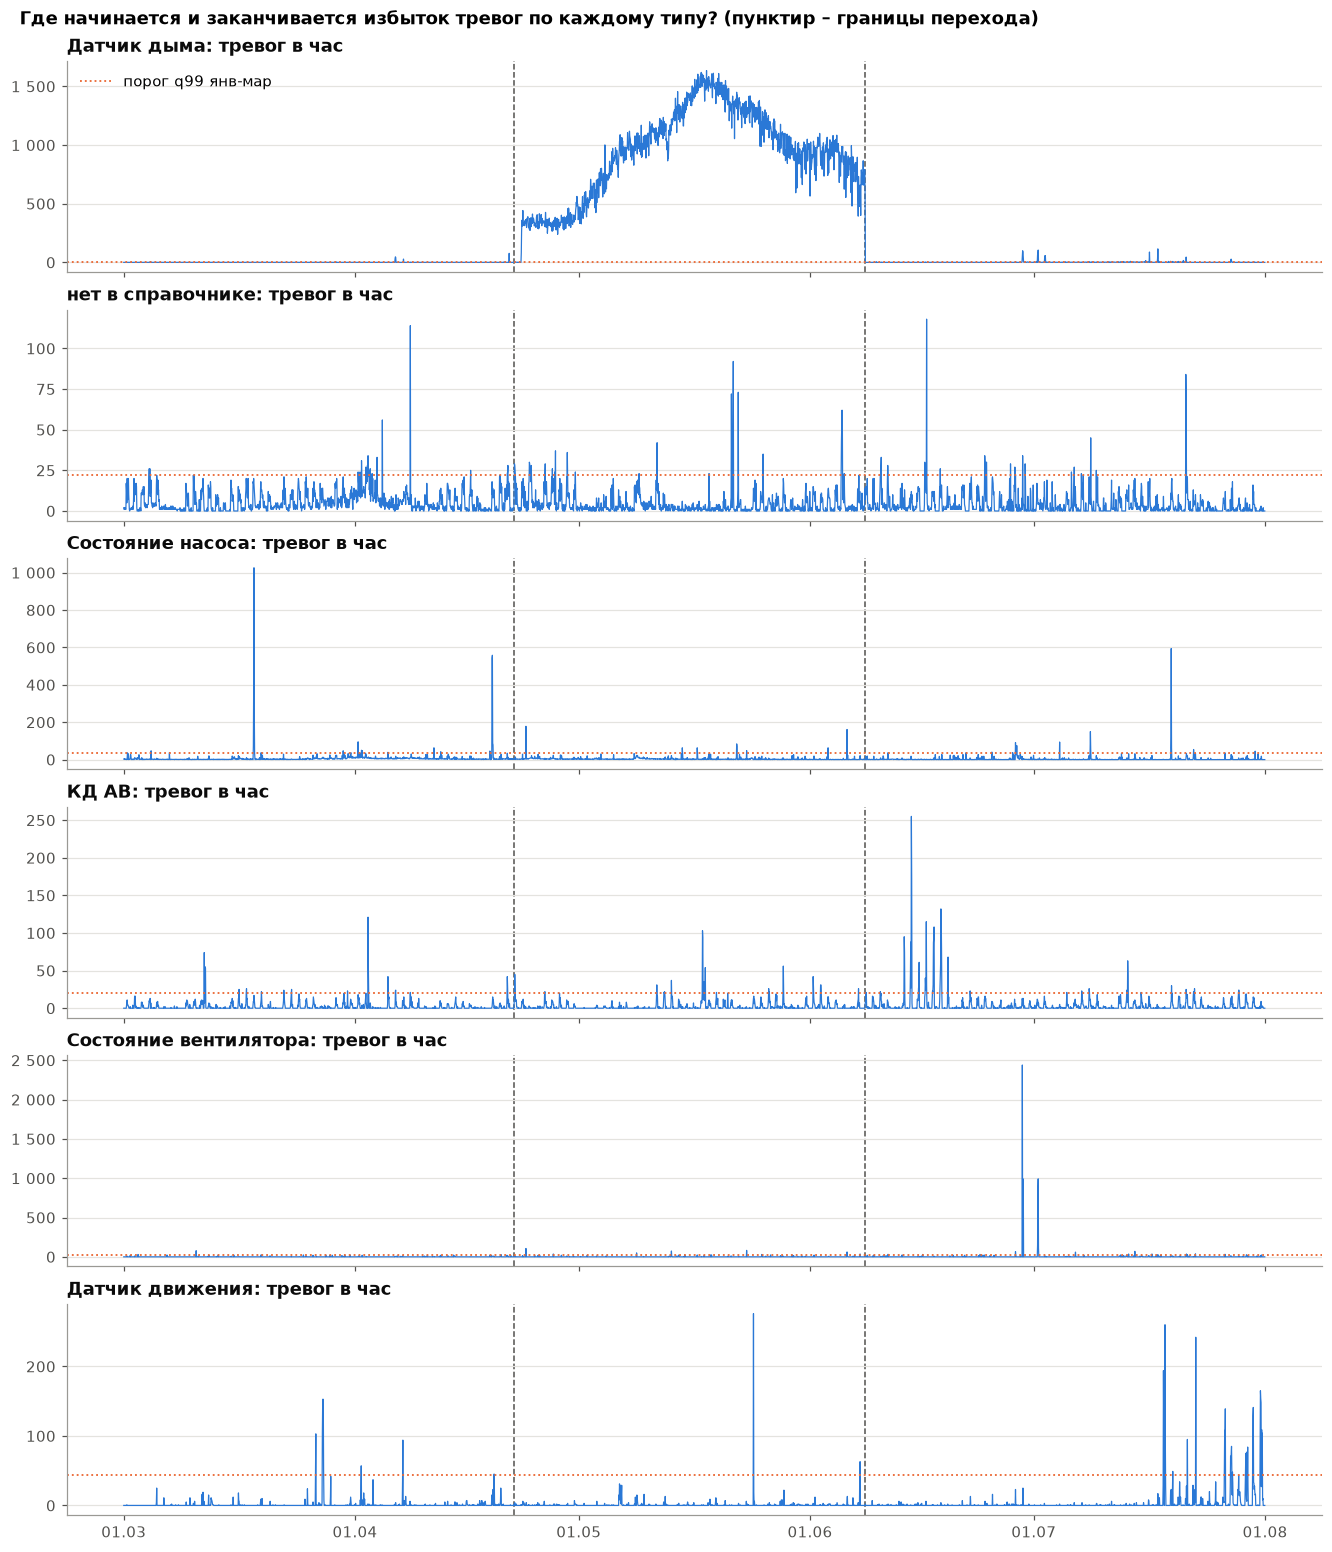

тревог дыма в [T0, T1): 1,035,741 из 1,036,346 за апрель-июнь (99.94%)


In [30]:
hourly["период_смву"] = smvu.period_of(hourly["час"])
bounds["доля_внутри_перехода"] = [
    round(float(((excess.index[excess[t].values] >= T0) & (excess.index[excess[t].values] < T1)).mean()), 3)
    for t in bounds.index]
share_tr = ((excess.index >= T0) & (excess.index < T1)).mean()
print(f"доля перехода в окне март-июль 2021: {share_tr:.1%}")
display(bounds[["аномальных_часов", "серия_ч", "доля_внутри_перехода"]])

# Почасовые тревоги топ-6 типов, март-июль 2021: один тип – одна панель, своя шкала
top6 = a21.loc["2021-03-01":].sum().nlargest(6).index
fig, axes = plt.subplots(6, 1, figsize=(12, 14), sharex=True)
for ax, t in zip(axes, top6):
    s = a21.loc["2021-03-01":, t]
    ax.plot(s.index, s.values, color=PALETTE[0], lw=0.8)
    ax.axhline(thr[t], color=PALETTE[1], ls=":", lw=1.2, label="порог q99 янв-мар")
    mark_transition(ax)
    thousands(ax)
    ax.set_title(f"{t}: тревог в час")
axes[0].legend(loc="upper left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
fig.suptitle("Где начинается и заканчивается избыток тревог по каждому типу? (пунктир – границы перехода)",
             x=0.01, ha="left", fontweight="bold")
plt.show()
inside = sm[(sm.index >= T0) & (sm.index < T1)].sum()
apr_jun = sm.loc["2021-04-01":"2021-06-30"].sum()
print(f"тревог дыма в [T0, T1): {inside:,} из {apr_jun:,} за апрель-июнь ({inside / apr_jun:.2%})")

Избыток тревог в переходе дает только дым: сплошная полоса в сотни тревог в час между пунктирами. У остальных
типов лишь одиночные пики, которые бывают и до, и после перехода: доля их аномальных часов внутри перехода 0-0,39
при доле перехода в окне 30,8 %, серии не длиннее 6 часов. Внутри [T0, T1) лежит 99,94 % тревог дыма за
апрель-июнь. Первая часть рассказа заказчика подтверждается: период есть, у него резкие границы, и в нем
аномально много тревог. Следующий вопрос – что это за тревоги и правда ли их не снимали.

### 3.2 Что именно тревожит в переходе
Считаем тревоги в сутки по парам (тип датчика, состояние) в трех периодах: `до` (2020-01-01 … T0), `переход` и
`после` (T1 … 2022-12-31). Для этого один раз строим витрину словаря состояний с точным периодом СМВУ
(в общей витрине словаря время есть только с точностью до месяца, а границы перехода внутри месяцев).

In [31]:
def vocab_by_period():
    """Словарь состояний с точным периодом СМВУ: тип × состояние × флаг × период × год."""
    return (smvu.add_smvu_period(events.filter(F.col("класс_записи") == "состояние"))
            .join(F.broadcast(channels.select("ид_канала_данных", "тип_датчика")), "ид_канала_данных", "left")
            .groupBy("тип_датчика", "состояние", "тревожное", "период_смву", "год")
            .agg(F.count("*").alias("количество_событий"),
                 F.countDistinct("ид_канала_данных").alias("число_каналов")))


V["vocab_period"] = agg.build_or_load("vocab_period", vocab_by_period, EDA_DIR, spark)
vocab_p = V["vocab_period"].toPandas()
vocab_p["тип_датчика"] = vocab_p["тип_датчика"].fillna(UNKNOWN)
assert vocab_p["количество_событий"].sum() == vocab["количество_событий"].sum()

per_days = {smvu.ДО: (T0 - pd.Timestamp("2020-01-01")) / pd.Timedelta(days=1),
            smvu.ПЕРЕХОД: (T1 - T0) / pd.Timedelta(days=1),
            smvu.ПОСЛЕ: (pd.Timestamp("2023-01-01") - T1) / pd.Timedelta(days=1)}
per = vocab_p[vocab_p["год"].between(2020, 2022) & vocab_p["тревожное"]]
rate = (per.groupby(["тип_датчика", "состояние", "период_смву"])["количество_событий"].sum().unstack(fill_value=0)
        .reindex(columns=PER, fill_value=0).div(pd.Series(per_days)).round(1))
rate["переход/до"] = (rate[smvu.ПЕРЕХОД] / rate[smvu.ДО].replace(0, np.nan)).round(1)
no_smoke = rate.drop(("Датчик дыма", "Неисправен"))[PER].sum()
print("тревог в сутки без пары «Датчик дыма / Неисправен»:", no_smoke.round(1).to_dict())
rate.sort_values(smvu.ПЕРЕХОД, ascending=False).head(15)

тревог в сутки без пары «Датчик дыма / Неисправен»: {'до': 736.1, 'переход': 356.8, 'после': 406.9}


период_смву                                         до  переход  после  переход/до
тип_датчика           состояние                                                   
Датчик дыма           Неисправен                  37.9  21976.3    7.1       579.8
КД АВ                 Не замкнут                  59.7     59.3   66.6         1.0
Состояние насоса      Работают все насосы в АНС   35.6     54.9   24.3         1.5
нет в справочнике     Не замкнут                 171.9     54.5   33.7         0.3
                      Работают все насосы в АНС   10.4     44.2    4.9         4.2
Датчик движения       Обнаружено движение        232.6     23.6   40.0         0.1
ИБП                   Питание от батарей           3.3     14.1   12.1         4.3
Состояние насоса      Неисправен                  23.8     13.1   37.6         0.6
Состояние вентилятора Неисправен                  22.8     12.3   28.9         0.5
                      Обесточен                   32.7     12.2   28.7         0.4
Состояние насоса      Обесточен                   22.6     12.0   35.1         0.5
                      Затоплен                    19.9     11.7   20.3         0.6
КД Дверь              Не замкнут                  37.1     10.7    8.9         0.3
Датчик температуры    Не определено                2.8      6.6    2.9         2.4
Состояние фазы        Неисправен                   2.9      4.8    8.6         1.7

Весь избыток – одна пара «Датчик дыма / Неисправен»: 21 976,3 тревоги в сутки в переходе против 37,9 до (×579,8)
и 7,1 после. Без этой пары тревог в переходе даже меньше, чем до и после: 356,8 в сутки против 736,1 и 406,9.

Теперь главное в словах заказчика – «тревоги оставались неснятыми». Если это так, тревоги в переходе должны
длиться дольше обычного: чаще висеть больше суток, оставаться открытыми (без последующей нормальной записи),
за тревогой должна чаще следовать снова тревога. Проверяем двумя способами. Первый – по записям смен состояния:
время до следующей записи канала. Второй – по эпизодам тревоги (подряд идущие тревожные записи канала до первой
нетревожной; так длительность не занижается, если за тревогой идет еще одна тревожная запись).

In [32]:
runs_p = smvu.add_smvu_period(runs)
dur_p = (runs_p.filter(F.col("тревожное") & F.col("год").between(2020, 2022))
         .groupBy("период_смву", "тип_датчика")
         .agg(F.count("*").alias("записей"),
              F.percentile_approx("секунд_до_следующего", 0.5).alias("медиана_с"),
              F.avg((F.col("секунд_до_следующего") > 86400).cast("int")).alias("доля_дольше_24ч"),
              F.avg(F.col("следующее_тревожное").cast("int")).alias("доля_тревога_за_тревогой"),
              F.avg(F.col("время_следующего").isNull().cast("int")).alias("доля_открытых"))
         .toPandas())
top_tr = dur_p[dur_p["период_смву"] == smvu.ПЕРЕХОД].nlargest(10, "записей")["тип_датчика"]
(dur_p[dur_p["тип_датчика"].isin(top_tr)]
 .pivot(index="тип_датчика", columns="период_смву")
 .reindex(columns=PER, level=1).round(3))

записей                 медиана_с               доля_дольше_24ч                доля_тревога_за_тревогой                доля_открытых               
период_смву                до  переход  после        до переход после              до переход  после                       до переход  после            до переход  после
тип_датчика                                                                                                                                                              
Датчик движения        112022     1127  22848         4       2     4           0.000    0.00  0.000                    0.001   0.000  0.004           0.0     0.0  0.000
Датчик дыма             24768  1035741   8812        92      92    81           0.007    0.00  0.020                    0.016   0.000  0.017           0.0     0.0  0.000
Датчик температуры       3302      374   3479        12      19    15           0.125    0.00  0.151                    0.395   0.008  0.058           0.0     0.0  0.000
ИБП                      1788      694   7754         2       2     2           0.000    0.00  0.000                    0.021   0.024  0.015           0.0     0.0  0.000
КД АВ                   28520     2794  38276        34      30    33           0.001    0.00  0.000                    0.002   0.000  0.001           0.0     0.0  0.000
КД Дверь                17699      507   5102         8      10     8           0.012    0.02  0.007                    0.001   0.010  0.008           0.0     0.0  0.000
Состояние вентилятора   26501     1153  32941         0       0     0           0.000    0.00  0.001                    0.399   0.501  0.498           0.0     0.0  0.000
Состояние насоса        48682     4325  67064         1       6     0           0.000    0.00  0.002                    0.448   0.317  0.494           0.0     0.0  0.000
Состояние фазы           1368      225   4927         4       9     4           0.001    0.00  0.010                    0.000   0.000  0.003           0.0     0.0  0.000
нет в справочнике       97050     5173  30904        15      12    22           0.001    0.00  0.002                    0.015   0.068  0.102           0.0     0.0  0.001

In [33]:
# Эпизоды тревоги (витрина alarm_episodes) с периодом СМВУ
ep = with_channel_attrs(V["alarm_episodes"].toPandas())
ep["длительность_с"] = (ep["конец"] - ep["начало"]).dt.total_seconds()
ep["период_смву"] = smvu.period_of(ep["начало"])
ep["год"] = ep["начало"].dt.year
ep = ep.sort_values(["ид_канала_данных", "начало"])
ep["с_предыдущего_с"] = ep.groupby("ид_канала_данных")["начало"].diff().dt.total_seconds()
e20 = ep[ep["год"].between(2020, 2022) & ep["тип_датчика"].isin(top_tr)]
(e20.groupby(["тип_датчика", "период_смву"])
 .agg(эпизодов=("длительность_с", "size"), медиана_с=("длительность_с", "median"),
      доля_дольше_24ч=("длительность_с", lambda s: (s > 86400).mean()), открытых=("открыт", "sum"))
 .unstack("период_смву").reindex(columns=PER, level=1).round(3))

эпизодов                 медиана_с               доля_дольше_24ч                открытых              
период_смву                 до  переход  после        до переход после              до переход  после       до переход после
тип_датчика                                                                                                                 
Датчик движения         111944     1127  22768       4.0     2.0   4.0           0.000   0.000  0.000        0       0     0
Датчик дыма              24374  1035598   8664      97.0    92.0  86.0           0.007   0.000  0.021        0       0     0
Датчик температуры        1996      371   3281     114.0    19.0  19.0           0.205   0.000  0.161        0       0     0
ИБП                       1751      677   7640       2.0     2.0   2.0           0.000   0.001  0.000        0       0     0
КД АВ                    28476     2793  38221      34.0    30.0  33.0           0.001   0.000  0.000        0       0     0
КД Дверь                 17684      502   5060       8.0    10.0   8.0           0.012   0.020  0.007        0       0     0
Состояние вентилятора    15923      575  16522       0.0     5.0  12.0           0.000   0.000  0.002        0       0     0
Состояние насоса         26858     2954  33928      35.0    36.0  25.0           0.001   0.000  0.004        0       0     0
Состояние фазы            1368      225   4913       4.0     9.0   4.0           0.001   0.000  0.010        0       0     0
нет в справочнике        95626     4823  27746      16.0    12.0  27.0           0.001   0.000  0.002       13       0    19

Длинных и незакрытых тревог в переходе нет. Эпизодов тревоги дыма в переходе 1 035 598, медиана 92 с (97 с до
перехода, 86 с после), дольше суток – 0,000, «тревога за тревогой» – 0,000, открытых – 0. Картина другая:
частый дребезг «Неисправен ↔ норма». Чьи это датчики?

In [34]:
fl = window(daily_ch, band_start.floor("D"), band_end.floor("D") + pd.Timedelta(days=1))
fl = fl[(fl["тип_датчика"] == "Датчик дыма") & (fl["количество_тревожных"] > 0)]
smoke_obj = (fl.groupby("ид_объект").agg(каналов=("ид_канала_данных", "nunique"), тревог=("количество_тревожных", "sum"))
             .join(obj_names.rename("объект")).sort_values("тревог", ascending=False))
smoke_ch = fl["ид_канала_данных"].unique()
sd = daily_ch[daily_ch["ид_канала_данных"].isin(smoke_ch)]
print(f"каналов дыма с тревогами в полосе: {len(smoke_ch)} на {fl['ид_объект'].nunique()} объектах;",
      f"писали до T0: {sd.loc[sd['день'] < T0, 'ид_канала_данных'].nunique()};",
      f"с тревогами после T1 (до 2021-10-01): "
      f"{window(sd, T1.normalize() + pd.Timedelta(days=1), '2021-10-01').loc[lambda x: x['количество_тревожных'] > 0, 'ид_канала_данных'].nunique()}")
top_ch = fl[fl["ид_объект"] == smoke_obj.index[0]].groupby("ид_канала_данных")["количество_тревожных"].sum()
print(f"на канал главного объекта: медиана {top_ch.median():,.0f} тревог за {fl['день'].nunique()} сут")
smoke_obj.assign(доля=(smoke_obj["тревог"] / smoke_obj["тревог"].sum()).round(4))

каналов дыма с тревогами в полосе: 116 на 6 объектах; писали до T0: 116; с тревогами после T1 (до 2021-10-01): 88
на канал главного объекта: медиана 13,452 тревог за 47 сут


,каналов,тревог,объект,доля
ид_объект,,,,
5343,77,1035564,объект Кси ПК202-ПК302,0.9998
4370,5,74,объект Ро,0.0001
3356,17,49,ПС объект Тау,0.0000
5113,12,18,объект Дельта,0.0000
5339,3,16,объект Пси,0.0000
5332,2,6,объект Кси ПК0-ПК202,0.0000


В полосе тревожили 116 каналов дыма на 6 объектах, но 99,98 % тревог (1 035 564) дают 77 каналов одного объекта –
«объект Кси ПК202-ПК302». Медиана – 13 452 тревоги на канал за 47 суток, примерно одна каждые 5 минут. Все 116
каналов писали и до перехода, 88 из них тревожат и после него (до конца сентября 2021).

**Вывод по 3.2.** Слова заказчика об аномальном числе тревог подтверждаются, а о неснятых тревогах – не
подтверждаются в той форме, в которой их можно проверить по журналу: тревоги короткие и закрываются нормальной
записью. Оговорка: факт квитирования тревоги оператором журнал не хранит, поэтому «оператор не отреагировал»
данными не опровергнуть; для этого нужен журнал ОДС. Наша интерпретация: избыток тревог – неисправность или сбой
интеграции дымовых датчиков на одном участке, совпавший по времени с параллельной работой систем. Для модели это
артефакт, который можно замаскировать точечно (объект и окно), а не общесистемный режим.

### 3.3 Изменился ли поток после перехода
Сравним поток до и после перехода на окнах одного сезона: «до» = 2021-01-01 … T0, «после» = T1 … 2021-09-30.

In [35]:
hour_n = hourly.groupby(["час", "период_смву"])["количество_событий"].sum().reset_index()
hour_n = hour_n[hour_n["час"].between("2021-01-01", "2021-09-30 23:00")]
med_h = hour_n.groupby("период_смву")["количество_событий"].median().reindex(PER)
print(f"медиана событий в час: до {med_h[smvu.ДО]:,.0f}, после {med_h[smvu.ПОСЛЕ]:,.0f}",
      f"(×{med_h[smvu.ПОСЛЕ] / med_h[smvu.ДО]:.2f})")
med_h

медиана событий в час: до 4,404, после 6,588 (×1.50)


период_смву
до         4404.0
переход    6760.0
после      6588.0
Name: количество_событий, dtype: float64

После перехода поток заметно выше: медиана 4 404 → 6 588 событий в час. Возможных объяснений несколько, и каждое
проверяется отдельно:
- стало больше активных каналов;
- каналы стали чаще опрашиваться;
- две системы пишут одни и те же события (дубли);
- сезонность: весной и летом поток и так растет;
- рост дает один объект.

Раскладываем поток в сутки на «активных каналов в сутки × событий на канал в сутки» по классу и типу.

In [36]:
WIN = {"до": ("2021-01-01", T0), "после": (T1, "2021-10-01")}
parts = []
for label, (s, e) in WIN.items():
    w = window(daily_ch, s, e)
    n_days = w["день"].nunique()
    g = w.groupby(["класс_записи", "тип_датчика"]).agg(канало_дней=("количество_событий", "size"),
                                                       событий=("количество_событий", "sum"),
                                                       каналов=("ид_канала_данных", "nunique"))
    parts.append(pd.DataFrame({
        "каналов": g["каналов"], "активных_в_сутки": g["канало_дней"] / n_days,
        "событий_на_канал_в_сутки": g["событий"] / g["канало_дней"], "событий_в_сутки": g["событий"] / n_days,
    }).add_suffix(f"_{label}"))
cmp = pd.concat(parts, axis=1).fillna(0)
cmp["прирост_событий_в_сутки"] = cmp["событий_в_сутки_после"] - cmp["событий_в_сутки_до"]
cmp["вклад_в_прирост"] = (cmp["прирост_событий_в_сутки"] / cmp["прирост_событий_в_сутки"].sum()).round(3)
print(f"событий в сутки: {cmp['событий_в_сутки_до'].sum():,.0f} → {cmp['событий_в_сутки_после'].sum():,.0f} "
      f"(×{cmp['событий_в_сутки_после'].sum() / cmp['событий_в_сутки_до'].sum():.2f})")
cmp.sort_values("прирост_событий_в_сутки", ascending=False).round(1).assign(вклад_в_прирост=cmp["вклад_в_прирост"]).head(10)

событий в сутки: 122,020 → 168,465 (×1.38)


каналов_до  активных_в_сутки_до  событий_на_канал_в_сутки_до  событий_в_сутки_до  каналов_после  активных_в_сутки_после  событий_на_канал_в_сутки_после  \
класс_записи тип_датчика                                                                                                                                                                      
измерение    Газовый датчик              183.0                114.4                        735.4             84129.5            280                   133.6                           877.1   
состояние    нет в справочнике           777.0                147.4                         42.4              6254.1            745                   168.5                            87.4   
             Состояние фазы              595.0                177.5                         13.4              2373.3            615                   198.7                            24.2   
             Переключатель               545.0                196.9                         11.1              2183.0            565                   296.9                            15.2   
             Состояние вентилятора       261.0                117.0                         10.0              1167.8            270                   204.4                            12.7   
             Газовый датчик              246.0                 18.9                         15.7               297.3            207                    30.8                            47.4   
             Состояние насоса            136.0                 31.9                         36.1              1148.5            145                    42.7                            39.4   
             Датчик дыма                1381.0                102.0                          3.1               319.9           1853                   139.3                             3.8   
             КД АВ                       272.0                 24.1                          5.0               120.7            278                    32.7                             6.1   
             Датчик температуры          369.0                 14.8                          3.5                50.9            467                    23.4                             5.0   

                                    событий_в_сутки_после  прирост_событий_в_сутки  вклад_в_прирост  
класс_записи тип_датчика                                                                             
измерение    Газовый датчик                      117143.5                  33014.0            0.711  
состояние    нет в справочнике                    14734.1                   8480.1            0.183  
             Состояние фазы                        4805.1                   2431.8            0.052  
             Переключатель                         4516.2                   2333.2            0.050  
             Состояние вентилятора                 2603.0                   1435.1            0.031  
             Газовый датчик                        1458.3                   1161.0            0.025  
             Состояние насоса                      1682.5                    533.9            0.011  
             Датчик дыма                            525.1                    205.1            0.004  
             КД АВ                                  198.5                     77.8            0.002  
             Датчик температуры                     117.5                     66.6            0.001

71,1 % прироста дает газовая телеметрия (+33 014 событий в сутки), 18,3 % – состояния каналов вне справочника
(+8 480), по 5 % – «Состояние фазы» и «Переключатель». Активных газовых каналов в сутки 114,4 → 133,6: больше, но
не настолько, чтобы объяснить рост. Проверяем частоту опроса. Газ делим на Альфу и остальные объекты: у них
разная частота, и медиана по смеси меняется просто от того, какая группа преобладает.

In [37]:
gaps["группа"] = np.where(gaps["тип_датчика"] != GAS, gaps["тип_датчика"],
                          np.where(gaps["ид_объект"] == ALPHA, "газ: Альфа", "газ: остальные"))
g21 = window(gaps, "2020-01-01", "2021-10-01").copy()
g21["период"] = np.where(g21["день"] < pd.Timestamp("2021-01-01"), "2020", smvu.period_of(g21["день"]))
(g21.groupby(["группа", "период"]).agg(медиана_интервала_с=("медианный_интервал_с", "median"),
                                      канало_дней=("количество_замеров", "size"),
                                      замеров_на_канало_день=("количество_замеров", "median"))
 .unstack("период").reindex(columns=["2020", *PER], level=1))

медиана_интервала_с                              канало_дней                           замеров_на_канало_день                        
период                            2020        до  переход     после        2020       до переход    после                   2020      до переход   после
группа                                                                                                                                                  
Датчик температуры             20772.0   31090.0  26048.5   21581.5     42303.0  10168.0  6399.0  15375.0                    2.0     2.0     2.0     2.0
ИБП                            37584.5  153716.0  94401.0  202606.5       333.0     53.0    23.0     46.0                    1.0     1.0     1.0     1.0
Состояние охраны               26957.0   27327.0  31101.0   29727.0      1864.0   1362.0   939.0   2517.0                    2.0     2.0     2.0     2.0
Состояние фазы                     NaN       NaN      NaN      46.0         NaN      NaN     NaN      1.0                    NaN     NaN     NaN     3.0
газ: Альфа                        62.0       8.0      8.0       9.0     13277.0   5136.0  1831.0   5682.0                  354.0  1344.0  1508.0  1997.0
газ: остальные                    63.0      62.0     62.0      62.0     18212.0   7677.0  4034.0   9543.0                  138.0   104.0   110.0    94.0
нет в справочнике               8416.0    7317.5  15346.0   30697.5     24555.0   7722.0  2439.0   3153.0                    3.0     3.0     2.0     2.0

Опрос не учащался: у Альфы медиана интервала 8 / 8 / 9 с (до / переход / после), у остальных газовых каналов
62 / 62 / 62 с. Интервал 62 с у Альфы был в 2020 году: ее опрос участился раньше, чем начался переход (к этому
вернемся в разделе 4). Следующая гипотеза – две системы пишут одно и то же. Полные дубли строк удалены при
очистке, поэтому ищем записи с одинаковыми (канал, время, класс записи) и считаем, сколько из них с одинаковым
значением.

In [38]:
dup21 = (smvu.add_smvu_period(events.filter(F.col("год") == 2021))
         .groupBy("период_смву", "класс_записи", "ид_канала_данных", "дата_время")
         .agg(F.count("*").alias("k"), F.countDistinct("значение_датчика").alias("значений"))
         .groupBy("период_смву", "класс_записи")
         .agg(F.sum("k").alias("записей"),
              F.sum(F.when(F.col("k") > 1, F.col("k")).otherwise(0)).alias("записей_с_общим_ключом"),
              F.sum(F.when((F.col("k") > 1) & (F.col("значений") == 1), F.col("k")).otherwise(0))
              .alias("записей_с_общим_ключом_и_значением"))
         .toPandas())
dup21.assign(доля_общий_ключ=(dup21["записей_с_общим_ключом"] / dup21["записей"]).round(4),
             доля_общее_значение=(dup21["записей_с_общим_ключом_и_значением"] / dup21["записей"]).round(4)
             ).sort_values(["класс_записи", "период_смву"])

,период_смву,класс_записи,записей,записей_с_общим_ключом,записей_с_общим_ключом_и_значением,доля_общий_ключ,доля_общее_значение
3,до,измерение,9452747,49332,0,0.0052,0.0000
5,переход,измерение,3813982,420,0,0.0001,0.0000
4,после,измерение,22809441,15335,44,0.0007,0.0000
0,до,состояние,4096375,109834,29408,0.0268,0.0072
2,переход,состояние,4114321,511127,4328,0.1242,0.0011
1,после,состояние,9412082,282149,60208,0.0300,0.0064


Дублей двух систем нет. В замерах совпадений (канал, время) 0,52 % до перехода, 0,01 % в переходе и 0,07 % после,
с одинаковым значением – почти ноль. В состояниях 12,42 % записей перехода делят ключ, но одинаковых значений среди
них 0,11 %: это не копии, а тот же дребезг дыма (смена «Неисправен ↔ норма» в одну секунду).

Остаются сезонность и один объект. Считаем поток без газа Альфы и сравниваем «после / до» в те же сезонные окна
других лет, когда перехода не было.

In [39]:
is_alpha_gas = daily_ch["ид_объект"].eq(ALPHA) & daily_ch["тип_датчика"].eq(GAS)
day_all = daily_ch.groupby("день")["количество_событий"].sum()
day_ex = daily_ch[~is_alpha_gas].groupby("день")["количество_событий"].sum()


def med(s, lo, hi):
    return s[(s.index >= pd.Timestamp(lo)) & (s.index < pd.Timestamp(hi))].median()


print(f"событий в сутки (медиана), до → после: {med(day_all, '2021-01-01', T0):,.0f} → {med(day_all, T1, '2021-10-01'):,.0f}",
      f"| без газа Альфы: {med(day_ex, '2021-01-01', T0):,.0f} → {med(day_ex, T1, '2021-10-01'):,.0f}")
print("медиана событий в час «после» / «до» в те же сезонные окна по годам:")
display(pd.Series({y: med(tot_h, T1.replace(year=y), f"{y}-10-01") / med(tot_h, f"{y}-01-01", T0.replace(year=y))
                   for y in range(2019, 2026)}, name="после/до").round(3))
# Какие каналы дали прирост газа: топ-30 по приросту событий в сутки и новые каналы
gd = daily_ch[daily_ch["тип_датчика"].eq(GAS) & daily_ch["класс_записи"].eq("измерение")]
per_ch = pd.DataFrame({lbl: window(gd, s, e).groupby("ид_канала_данных")["количество_событий"].sum()
                       / window(daily_ch, s, e)["день"].nunique() for lbl, (s, e) in WIN.items()}).fillna(0)
per_ch["прирост"] = per_ch["после"] - per_ch["до"]
top30 = per_ch.nlargest(30, "прирост")
print(f"каналов Альфы среди топ-30 по приросту газа: "
      f"{top30.index.isin(gd.loc[gd['ид_объект'] == ALPHA, 'ид_канала_данных']).sum()};",
      f"новые газовые каналы (не писали «до») дают {per_ch.loc[per_ch['до'] == 0, 'после'].sum():,.0f} событий в сутки «после»")
# Газ Альфы и остальных объектов: событий в сутки по месяцам 2020-2021
gm_d = (gd.assign(альфа=gd["ид_объект"].eq(ALPHA))
        .groupby([month_start(gd["день"]), "альфа"])["количество_событий"].sum().unstack()
        .div(gd.groupby(month_start(gd["день"]))["день"].nunique(), axis=0)
        .rename(columns={True: "газ Альфы", False: "газ остальных"}))
gm_d.loc["2020-01-01":"2021-12-01"].round(0)

событий в сутки (медиана), до → после: 122,511 → 171,014 | без газа Альфы: 58,802 → 70,898
медиана событий в час «после» / «до» в те же сезонные окна по годам:


2019    1.658
2020    1.618
2021    1.496
2022    1.010
2023    1.069
2024    1.142
2025    1.219
Name: после/до, dtype: float64

каналов Альфы среди топ-30 по приросту газа: 28; новые газовые каналы (не писали «до») дают 2,239 событий в сутки «после»


альфа,газ остальных,газ Альфы
день,,
2020-01-01,14377.0,7702.0
2020-02-01,12316.0,6796.0
2020-03-01,9544.0,7727.0
2020-04-01,12153.0,7292.0
2020-05-01,15296.0,9040.0
2020-06-01,15196.0,12110.0
2020-07-01,11614.0,12551.0
2020-08-01,7002.0,13052.0
2020-09-01,6321.0,12867.0


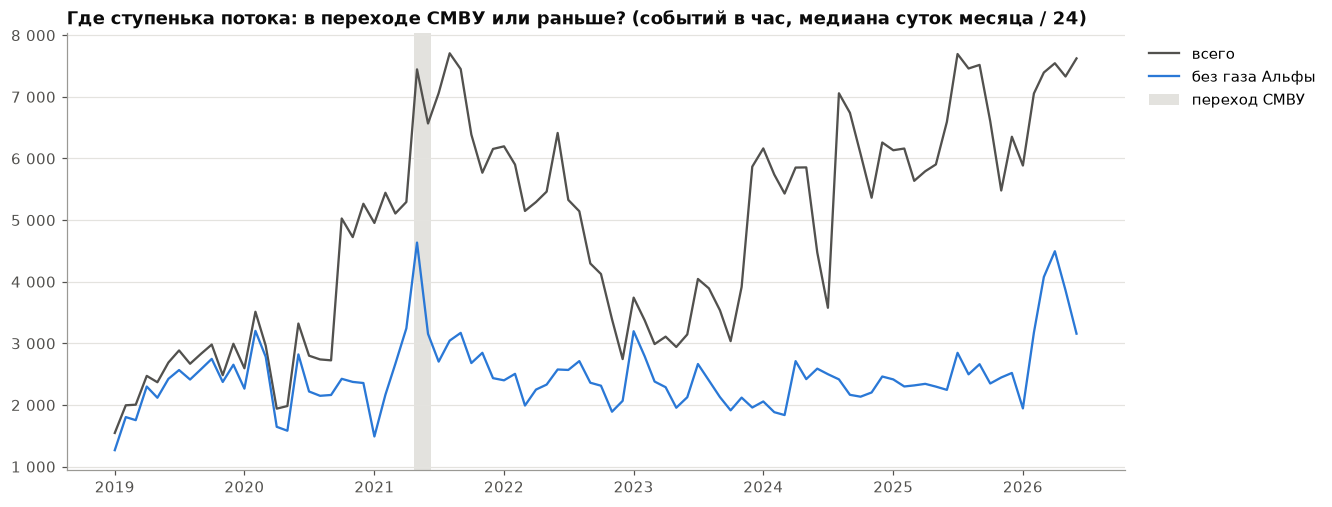

день,2020-06-01,2020-07-01,2020-08-01,2020-09-01,2020-10-01,2020-11-01,2020-12-01,2021-01-01,2021-02-01,2021-03-01,2021-04-01,2021-05-01,2021-06-01,2021-07-01,2021-08-01,2021-09-01,2021-10-01,2021-11-01,2021-12-01
всего,3321.0,2800.0,2740.0,2725.0,5026.0,4724.0,5265.0,4953.0,5444.0,5107.0,5294.0,7445.0,6568.0,7061.0,7706.0,7450.0,6388.0,5769.0,6155.0
без газа Альфы,2820.0,2219.0,2149.0,2163.0,2425.0,2375.0,2357.0,1489.0,2166.0,2668.0,3244.0,4635.0,3154.0,2704.0,3045.0,3170.0,2681.0,2847.0,2436.0


In [40]:
# Уровень потока по месяцам: всего и без газа Альфы (медиана суточного потока / 24 = событий в час)
lvl = pd.DataFrame({"всего": day_all, "без газа Альфы": day_ex}) / 24
lvl = lvl.groupby(month_start(lvl.index.to_series())).median()
fig, ax = plt.subplots()
ax.plot(lvl.index, lvl["всего"], color=INK2, label="всего")
ax.plot(lvl.index, lvl["без газа Альфы"], color=PALETTE[0], label="без газа Альфы")
shade_transition(ax)
thousands(ax)
ax.set_title("Где ступенька потока: в переходе СМВУ или раньше? (событий в час, медиана суток месяца / 24)")
legend_right(ax)
plt.show()
lvl.loc["2020-06-01":"2021-12-01"].round(0).T

**Вывод по 3.3.** Рост потока после перехода – не эффект новой СМВУ.
- Рост почти целиком дает газ Альфы: 28 из 30 газовых каналов с наибольшим приростом – ее, а без газа Альфы
  суточный поток растет лишь в 1,21 раза (58 802 → 70 898). Новые газовые каналы дают всего 2 239 событий в сутки.
- Это сезонность: в те же окна 2019 и 2020 годов, когда никакого перехода не было, поток вырос в 1,658 и 1,618
  раза. Газ Альфы и в 2020 году рос с апреля по июль (7 292 → 12 551 событий в сутки), а в 2021-м – с 51 473
  до 100 957.
- Устойчивая ступень уровня потока есть, но она в **октябре 2020**, за полгода до перехода: медиана событий в час
  2 725 (сентябрь 2020) → 5 026 (октябрь 2020), газ Альфы 12 867 → 55 649 событий в сутки. Без газа Альфы поток
  в июле-сентябре 2021 года (2 704-3 170 в час) на уровне марта-апреля (2 668-3 244): ступеньки на T1 нет.
  Май 2021 (4 635) выше из-за потока тревог дыма.
- Отдельно видно, что в июле 2021 года поток ненадолго падает. Посмотрим на это вместе с каналами.

### 3.4 Сменились ли каналы
Если новая система пришла со своими каналами, каналы старой должны массово замолкать к концу перехода, а новые –
появляться, причем, скорее всего, с новыми ID.

In [41]:
life["первый_период"] = smvu.period_of(life["первый_день"])
life["последний_период"] = smvu.period_of(life["последний_день"])
pd.crosstab([life["в_справочнике"], life["первый_период"]], life["последний_период"], margins=True)

последний_период              до  переход  после    All
в_справочнике первый_период                            
False         до             305        7    786   1098
              переход          0        0      1      1
              после            0        0     43     43
True          до               0        0   6338   6338
              переход          0        0      5      5
              после            0        0   5142   5142
All                          305        7  12315  12627

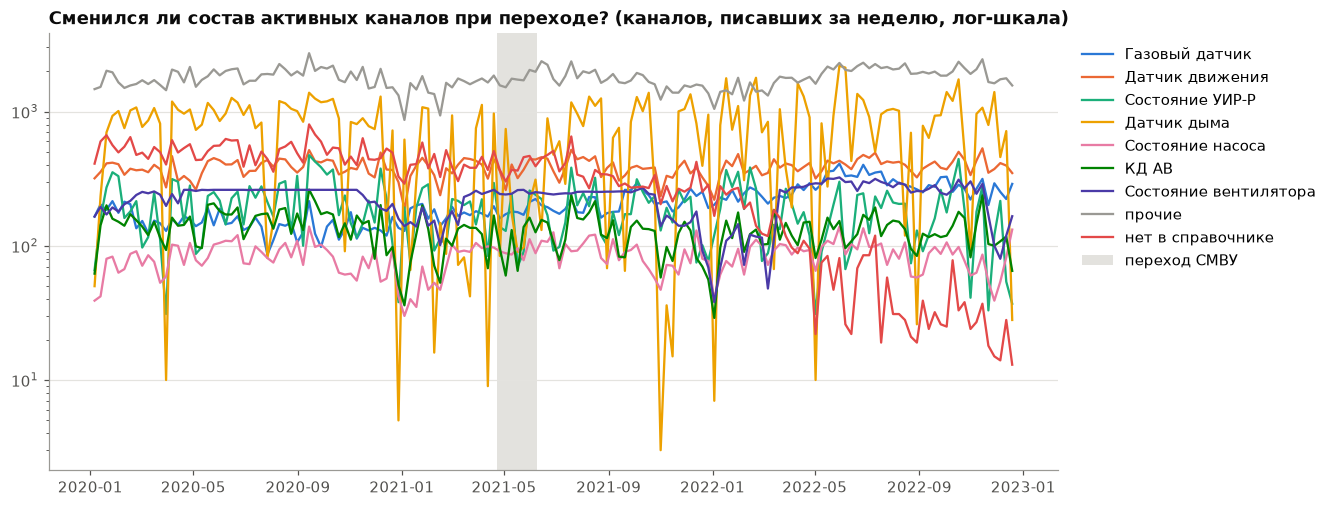

In [42]:
# Активные каналы по типам 2020-2022 (канал активен в неделю, если писал хотя бы раз)
d20 = window(daily_ch, "2020-01-01", "2023-01-01")
act_w = fold_types(d20.groupby([week_start(d20["день"]), "тип_датчика"])["ид_канала_данных"].nunique()
                   .unstack(fill_value=0)).iloc[1:-1]  # неполные крайние недели
fig, ax = plt.subplots()
plot_lines(ax, act_w.replace(0, np.nan))
ax.set_yscale("log")
shade_transition(ax)
ax.set_title("Сменился ли состав активных каналов при переходе? (каналов, писавших за неделю, лог-шкала)")
legend_right(ax)
plt.show()

In [43]:
# Волна новых каналов в конце июня 2021 и возмущение сразу после нее: тревоги по типам и поток по дням
jun_new = life[life["в_справочнике"] & life["первый_день"].between("2021-06-01", "2021-06-30")]
print("новые каналы справочника в июне 2021 по дням:", jun_new["первый_день"].value_counts().sort_index()
      .loc[lambda s: s >= 5].rename(lambda d: f"{d:%m-%d}").to_dict())
b_jun = life[life["в_справочнике"] & life["первый_день"].isin(pd.to_datetime(["2021-06-28", "2021-06-29"]))]
print(f"каналов справочника появились 28-29.06.2021: {len(b_jun)}, ID {b_jun['ид_канала_данных'].min()}…"
      f"{b_jun['ид_канала_данных'].max()};", b_jun["тип_датчика"].value_counts().to_dict(),
      b_jun["диспетчерское_название_объекта"].value_counts().head(3).to_dict())
print(f"каналов справочника появились в переходе: {(life['в_справочнике'] & (life['первый_период'] == smvu.ПЕРЕХОД)).sum()}")
d = window(hourly, "2021-06-25", "2021-07-06", col="час")
dd = d.pivot_table(index=d["час"].dt.date, columns="тип_датчика", values="количество_тревожных", aggfunc="sum",
                   fill_value=0)
dd[["Состояние вентилятора", GAS, "Датчик дыма"]].assign(
    тревог_всего=dd.sum(axis=1), событий=d.groupby(d["час"].dt.date)["количество_событий"].sum(),
    газ_Альфы=daily_ch[is_alpha_gas].groupby(daily_ch["день"].dt.date)["количество_событий"].sum())

новые каналы справочника в июне 2021 по дням: {'06-28': 379, '06-29': 91}
каналов справочника появились 28-29.06.2021: 470, ID 261872…262737; {'Датчик дыма': 459, 'Состояние УИР-Р': 5, 'КД Дверь': 3, 'ИБП': 3} {'объект Пси ПС': 268, 'объект Эпсилон ПС': 196, 'Шкафы ПС объект Эпсилон': 6}
каналов справочника появились в переходе: 5


тип_датчика,Состояние вентилятора,Газовый датчик,Датчик дыма,тревог_всего,событий,газ_Альфы
час,,,,,,
2021-06-25,38,12,0,457,164637,93959.0
2021-06-26,0,0,0,111,153969,103608.0
2021-06-27,0,0,0,163,150268,102401.0
2021-06-28,86,0,7,799,175618,99888.0
2021-06-29,3446,5,299,4157,151095,34307.0
2021-06-30,2,0,26,230,64182,2.0
2021-07-01,2080,0,273,2564,71955,NaN
2021-07-02,16,7007,127,7416,131605,64734.0
2021-07-03,0,0,11,100,143705,102202.0


**Массовой смены каналов при переходе не было.** Все 6 338 каналов справочника, писавших до перехода, пишут и после
с теми же ID; ни один канал справочника не замолк до T1; в переходе появилось только 5 новых каналов. Состав
активных каналов по типам через переход не меняется (график выше), а одноименных «цепочек замен» нет вовсе
(раздел 2.3). Волны новых каналов идут не на границах перехода: 28-29.06.2021 – 470 каналов (459 дымовых,
«объект Пси ПС» 268 и «объект Эпсилон ПС» 196), декабрь 2021 – 811, 2022Q2 – 2 086. Это расширение сети.

Зато в конце июня – начале июля видно короткое **послепереходное возмущение**: 29.06 – 4 157 тревог (3 446 у
вентиляторов), 01.07 – 2 564 (2 080 у вентиляторов), 02.07 – 7 416 (7 007 у газа), а поток 30.06 и 01.07 падает
до 64 182 и 71 955 событий в сутки при обычных 144-176 тыс. в соседние дни (газ Альфы 30.06 дает 2 события, 01.07 – ни одного).
Мы не знаем, связано ли оно с переходом; но для модели это такой же нетипичный отрезок, и его разумно маскировать.

### 3.5 Сменился ли словарь состояний
Новая система могла прийти со своими названиями состояний или своей разметкой тревожности.

In [44]:
names = (vocab_p.groupby(["состояние", "период_смву"])["количество_событий"].sum().unstack(fill_value=0)
         .reindex(columns=PER, fill_value=0))
print("названий состояний по периодам:", (names > 0).sum().to_dict(),
      "| только до:", list(names.index[(names[smvu.ДО] > 0) & (names[smvu.ПОСЛЕ] == 0)]),
      "| только после:", list(names.index[(names[smvu.ПОСЛЕ] > 0) & (names[smvu.ДО] == 0)]))
st = (vocab_p.groupby(["тип_датчика", "состояние", "период_смву"])["количество_событий"].sum().unstack(fill_value=0)
      .reindex(columns=PER, fill_value=0))
only_old, only_new = st[(st[smvu.ДО] > 0) & (st[smvu.ПОСЛЕ] == 0)], st[(st[smvu.ПОСЛЕ] > 0) & (st[smvu.ДО] == 0)]
print(f"пар (тип, состояние): {len(st)}; только до: {len(only_old)}, только после: {len(only_new)}")
display(only_old.sort_values(smvu.ДО, ascending=False))
only_new.sort_values(smvu.ПОСЛЕ, ascending=False).head(10)

названий состояний по периодам: {'до': 32, 'переход': 32, 'после': 32} | только до: [] | только после: []
пар (тип, состояние): 199; только до: 6, только после: 37


,период_смву,до,переход,после
тип_датчика,состояние,,,
Состояние фазы,Включен,866,0,0
Ручной извещатель,Обнаружено движение,39,0,0
Состояние фазы,Не замкнут,3,0,0
Датчик дыма,Обесточен,2,0,0
ИБП,Не замкнут,2,0,0
Датчик дыма,Есть питание,1,0,0


,период_смву,до,переход,после
тип_датчика,состояние,,,
Состояние УИР-Р,Не замкнут,0,0,1324
9-секционный люк,Норма,0,0,252
Ручной извещатель,Отключено устройство,0,0,232
9-секционный люк,Неопределен,0,0,159
КД Люк,Неисправен,0,0,120
9-секционный люк,Не замкнут,0,0,73
Тепловой датчик,Отключено устройство,0,0,24
Датчик температуры,Движения нет,0,0,24
Тепловой датчик,Неисправен,0,0,22


In [45]:
# Доля тревожных для одной и той же пары (тип, состояние) по годам; 2021 разбит на «до» и «после», переход исключен.
# Пары, где доля за разные годы расходится больше чем на 0,2, и записей за все годы > 1 000
v = vocab_p[vocab_p["период_смву"] != smvu.ПЕРЕХОД].copy()
v["срез"] = v["год"].astype(str).where(v["год"] != 2021, "2021 " + v["период_смву"])
SLICES = ["2019", "2020", "2021 до", "2021 после", "2022", "2023", "2024", "2025", "2026"]
t = v.pivot_table(index=["тип_датчика", "состояние"], columns=["срез", "тревожное"], values="количество_событий",
                  aggfunc="sum", fill_value=0)
share_y = pd.DataFrame({c: t[c].get(True, 0) / t[c].sum(axis=1).replace(0, np.nan)
                        for c in SLICES if c in t.columns.get_level_values(0)})
n_pair = v.groupby(["тип_датчика", "состояние"])["количество_событий"].sum().reindex(share_y.index)
drift = share_y[(share_y.max(axis=1) - share_y.min(axis=1) > 0.2) & (n_pair > 1000)]
drift.assign(записей=n_pair).round(2)

2019  2020  2021 до  2021 после  2022  2023  2024  2025  2026  записей
тип_датчика           состояние                                                                                    
Газовый датчик        Неисправен             0.76  0.21     0.59        0.95  0.67  0.33  0.39  0.95  1.00    49012
                      Обнаружен газ          0.89  0.64     0.47        0.54  0.45  0.37  0.34  0.58  0.99    17610
Датчик движения       Неисправен             0.05  0.98     0.49        0.04  0.10  0.57  0.16  0.37  0.08     1755
                      Отключено устройство    NaN  0.50     0.00         NaN  0.00  0.33  0.30  0.37  0.25     1156
Датчик дыма           Неисправен             0.25  0.79     0.21        0.26  0.13  0.14  0.18  0.49  1.00   133401
                      Обнаружен дым          0.35  0.49     0.04        0.19  0.12  0.07  0.10  0.30  1.00   163601
                      Отключено устройство   0.26  0.96     0.08        0.62  0.06  0.76  0.67  0.95  1.00     3951
Датчик температуры    Не определено          0.91  1.00     1.00        1.00  0.76  0.90  0.76  0.90  1.00     9926
                      Температура выше 40ºC  1.00  1.00     1.00        1.00  0.27  0.65  0.69  0.97  1.00     1910
                      Температура ниже 3ºC   0.97  1.00     1.00        1.00  0.84  0.84  0.79  0.92  1.00     9962
КД Дверь              Обнаружено движение    0.69  0.17     0.00        0.00  0.00  0.00  0.00  0.00  0.00   121314
Ручной извещатель     Не замкнут             0.25  0.11     0.02        0.08  0.10  0.02  0.04  0.63  0.99     2305
                      Неисправен             1.00  1.00     0.00         NaN  0.88   NaN  0.17  0.99  1.00    10660
Состояние УИР-Р       Не замкнут              NaN   NaN      NaN        0.03  0.00  0.00  0.00  0.17  1.00     1324
                      Рычаг сдернут          0.17  0.07     0.01        0.07  0.05  0.02  0.07  0.20  0.99    40816
Состояние вентилятора Неисправен             1.00  0.99     0.91        0.49  0.99  0.99  0.97  0.99  1.00    78073
                      Обесточен              1.00  1.00     0.91        0.49  0.99  0.99  0.97  0.99  1.00    82096
Состояние насоса      Затоплен               1.00  0.80     0.58        0.80  0.91  0.82  0.71  0.94  1.00    61630
                      Неисправен             1.00  0.82     0.60        0.85  0.94  0.90  0.77  0.96  1.00   108131
                      Обесточен              1.00  0.82     0.56        0.86  0.93  0.90  0.76  0.96  1.00    95591
Стекло                Не замкнут             1.00  1.00     1.00        1.00  0.56  1.00  1.00  1.00  1.00    10503
Тепловой датчик       Не замкнут             0.25  0.01     0.98        0.76  0.66  0.68  0.45  0.83  1.00     3678
нет в справочнике     Затоплен               0.95  0.60     0.79        0.86  1.00  0.92   NaN   NaN   NaN     2112
                      Не замкнут             0.22  0.68     0.34        0.58  0.49  0.26  0.23  0.79   NaN   199204
                      Не определено          0.96  1.00     1.00        1.00  0.90  0.67   NaN   NaN   NaN     1466
                      Неисправен             0.56  0.86     0.36        0.88  0.68  0.54  1.00  1.00  1.00    12427
                      Обнаружен газ          0.88  0.42     1.00        0.56   NaN   NaN   NaN   NaN   NaN     3957
                      Питание от батарей     1.00  1.00     1.00        1.00  1.00  1.00  0.77  0.93  1.00     2606

Словарь не сменился: во всех трех периодах одни и те же 32 названия. Из 199 пар (тип, состояние) только до
перехода встречаются 6 (крупнейшая – «Состояние фазы / Включен», 866 записей), только после – 37, в основном
единичные записи и новый тип «9-секционный люк». Сильно меняется другое – доля тревожных у одной и той же пары,
причем по годам, а не на границе перехода. «Газовый датчик / Неисправен»: 0,76 (2019), 0,21 (2020), 0,59
(2021 до), 0,95 (2021 после), 0,67 (2022), 0,33 (2023), 0,39 (2024), 0,95 (2025), 1,00 (2026). «Датчик дыма /
Обнаружен дым»: 0,35, 0,49, 0,04, 0,19, 0,12, 0,07, 0,10, 0,30, 1,00. В 2026 году почти все пары тревожны на
0,99-1,00 – это отдельное изменение разметки конца 2025 года, его разберем в разделе 5. Вывод: флаг `тревожное`
нельзя считать неизменным свойством состояния, а переход 2021 года – главной точкой его изменения.

### 3.6 Сопоставимы ли периоды для обучения
Чтобы решить, можно ли учить модель на данных до перехода, сравним частоту тревог на «живой» канал (канал между
первым и последним событием) по эпохам. Знаменатель – живые каналы, а не писавшие в этот час: дискретный канал
молчит, пока состояние не меняется.

In [46]:
EPOCHS = {"2019-2020": ("2019-01-01", "2021-01-01"), "2021 до перехода": ("2021-01-01", T0),
          "переход": (T0, T1), "2021 после перехода": (T1, "2022-01-01"),
          "2022-2023": ("2022-01-01", "2024-01-01"), "2024-2026": ("2024-01-01", DATA_END + pd.Timedelta(days=1))}
rates = {}
for name, (s, e) in EPOCHS.items():
    s, e = pd.Timestamp(s), pd.Timestamp(e)
    days = (e - s) / pd.Timedelta(days=1)
    alarms = window(hourly, s, e, col="час").groupby("тип_датчика")["количество_тревожных"].sum()
    alive = life[(life["первый_день"] < e) & (life["последний_день"] >= s)].groupby("тип_датчика").size()
    rates[name] = alarms / alive / days
ep_rate = pd.DataFrame(rates)
print("тревог в сутки на живой канал по эпохам:")
ep_rate.loc[ep_rate.sum(axis=1).sort_values(ascending=False).index].round(4)

тревог в сутки на живой канал по эпохам:


,2019-2020,2021 до перехода,переход,2021 после перехода,2022-2023,2024-2026
тип_датчика,,,,,,
Датчик дыма,0.0265,0.0029,15.9150,0.0053,0.0034,0.0242
Состояние насоса,0.8119,0.7818,0.6603,0.7992,0.6337,0.7035
КД АВ,0.2835,0.1620,0.2164,0.2126,0.1917,0.2812
Стекло,0.3243,0.4084,0.1717,0.1920,0.1225,0.1220
ИБП,0.0900,0.1157,0.3506,0.2988,0.1384,0.1056
Состояние вентилятора,0.1671,0.0633,0.0937,0.2443,0.1440,0.1917
нет в справочнике,0.1240,0.1424,0.1383,0.1394,0.0252,0.0242
Датчик движения,0.3007,0.0751,0.0403,0.0525,0.0391,0.0590
Состояние охраны,0.0687,0.0586,0.0564,0.0438,0.0519,0.0862


In [47]:
# Распределение годового числа тревог на канал (каналы с состояниями в году), фокусные типы
ch_year = (daily_ch[daily_ch["класс_записи"] == "состояние"]
           .groupby(["тип_датчика", "год", "ид_канала_данных"])["количество_тревожных"].sum().reset_index())
key_types = [t for t in FOCUS if t in ch_year["тип_датчика"].unique()] + [UNKNOWN]
(ch_year[ch_year["тип_датчика"].isin(key_types)]
 .groupby(["тип_датчика", "год"])["количество_тревожных"]
 .agg(каналов="size", медиана="median", p90=lambda s: s.quantile(0.9), доля_без_тревог=lambda s: (s == 0).mean())
 .round(3).unstack("год"))

каналов                                           медиана                                                     p90                                                   \
год                      2019  2020  2021  2022  2023  2024  2025  2026    2019   2020   2021   2022   2023   2024   2025   2026   2019   2020   2021   2022   2023   2024   2025   2026   
тип_датчика                                                                                                                                                                                
Газовый датчик            368   319   424   500   503   492   529   463     2.0    3.0    1.0    1.0    1.0    1.0    1.0    0.0   12.0   19.0   12.7    6.1    3.0    2.0   16.0    5.0   
Датчик движения           455   577   629   752   761   761   804   804    12.0    0.0    0.0    0.0    0.0    1.0    1.5    0.0   93.2   62.4   17.0   26.0   13.0   18.0   36.7   12.7   
Датчик дыма               385  1381  2387  3715  3743  3745  4337  4337     2.0    7.0    1.0    1.0    0.0    0.0    1.0    2.0    9.0   36.0    3.0    4.0    1.0    2.0    5.0   10.0   
КД АВ                     220   272   290   359   373   373   397   397    41.5   40.0   31.5   32.0   30.0   28.0   27.0   12.0  266.1  199.1  125.0  159.8  154.4  112.8  114.0   56.8   
Состояние УИР-Р           367   488   570   759   759   759   762   762     1.0    0.0    0.0    0.0    0.0    0.0    1.0    3.0    4.0    3.0    1.0    2.0    0.0    2.0    3.0    5.0   
Состояние вентилятора     223   261   281   329   330   330   354   354     0.0   12.0   30.0   42.0   31.0   43.5   42.0   26.5   98.8   84.0  153.0  140.0  122.0  108.4  162.0  134.1   
Состояние насоса          114   139   153   167   169   169   180   180   170.5  147.0  154.0  175.0  138.0  138.0  171.0  107.0  514.6  422.0  337.8  330.4  282.6  308.8  342.2  244.0   
нет в справочнике        1003   990   829   526   106    30    12     2     2.0    0.0    0.0    0.0    5.0    8.0    4.5    4.5   24.8   34.0   22.0   17.5   28.0   43.6   28.4    4.9   

                      доля_без_тревог                                                   
год                              2019   2020   2021   2022   2023   2024   2025   2026  
тип_датчика                                                                             
Газовый датчик                  0.049  0.107  0.236  0.158  0.125  0.238  0.089  0.538  
Датчик движения                 0.013  0.534  0.544  0.519  0.650  0.426  0.422  0.714  
Датчик дыма                     0.005  0.215  0.491  0.454  0.858  0.715  0.162  0.000  
КД АВ                           0.000  0.000  0.028  0.000  0.000  0.000  0.000  0.000  
Состояние УИР-Р                 0.000  0.633  0.756  0.686  0.901  0.664  0.226  0.008  
Состояние вентилятора           0.538  0.460  0.427  0.365  0.361  0.367  0.336  0.268  
Состояние насоса                0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  
нет в справочнике               0.358  0.501  0.573  0.658  0.123  0.100  0.167  0.000

Если не считать дыма в переходе, частота тревог на живой канал через переход не ломается: «Состояние насоса»
0,78 → 0,66 → 0,80 (2021 до / переход / после), «КД АВ» 0,16 → 0,22 → 0,21, каналы вне справочника
0,142 → 0,138 → 0,139. Крупные сдвиги приходятся на другие даты: «Датчик движения» 0,30 (2019-2020) → 0,075 (начало
2021 года, еще до перехода), каналы вне справочника 0,139 → 0,025 (2022-2023). Вывод: данные до перехода можно
использовать для обучения, если исключить сам переход и учесть эпоху признаком.

### 3.7 Каналы вне справочника – это старая система?
В разделе 2.4 мы предположили, что каналы вне справочника – каналы старой СМВУ. Если так, то они (а) дают заметную
долю событий до перехода и почти ничего после, (б) замолкают к концу перехода, (в) пишут что-то свое (другие
состояния или другой класс записей), (г) имеют свой диапазон ID.

In [48]:
# Доля строк и тревог вне справочника по периодам (точные часы)
up = (hourly.assign(вне=hourly["тип_датчика"] == UNKNOWN)
      .groupby(["период_смву", "вне"])[["количество_событий", "количество_тревожных"]].sum())
up = up.unstack("вне", fill_value=0).reindex(PER)
display(pd.DataFrame({"строк_вне": up[("количество_событий", True)],
                      "доля_строк": (up[("количество_событий", True)] / up["количество_событий"].sum(axis=1)).round(4),
                      "тревог_вне": up[("количество_тревожных", True)],
                      "доля_тревог": (up[("количество_тревожных", True)] / up["количество_тревожных"].sum(axis=1)).round(4)}))
# Сколько каналов вне справочника писали в каждом периоде (по дням, поэтому граничные сутки смазаны)
ch_per = (daily_ch.assign(период_смву=smvu.period_of(daily_ch["день"]))
          .groupby(["период_смву", "в_справочнике"])["ид_канала_данных"].nunique().unstack("в_справочнике", fill_value=0)
          .reindex(PER).rename(columns={True: "в справочнике", False: UNKNOWN}))
ch_per.assign(доля_вне=(ch_per[UNKNOWN] / ch_per.sum(axis=1)).round(3))

,строк_вне,доля_строк,тревог_вне,доля_тревог
период_смву,,,,
до,6490637,0.1035,112223,0.2229
переход,356857,0.0450,5173,0.0049
после,2592161,0.0107,34300,0.0377


в_справочнике,нет в справочнике,в справочнике,доля_вне
период_смву,,,
до,1098,6338,0.148
переход,713,5552,0.114
после,830,11485,0.067


,первый_день,последний_день,активных_дней,количество_событий
count,1142,1142,1142.000000,1.142000e+03
mean,2019-04-16 05:06:24.588441344,2021-09-21 21:57:41.295971840,231.661996,8.265898e+03
min,2019-01-01 00:00:00,2019-01-08 00:00:00,1.000000,1.000000e+00
5%,2019-01-01 00:00:00,2019-09-03 07:12:00,10.000000,4.900000e+01
25%,2019-01-04 00:00:00,2020-11-09 06:00:00,48.000000,1.850000e+02
50%,2019-01-07 00:00:00,2021-12-29 00:00:00,89.000000,4.565000e+02
75%,2019-02-11 00:00:00,2022-04-28 00:00:00,372.750000,2.895750e+03
95%,2020-03-24 00:00:00,2023-08-17 21:36:00,787.850000,2.800270e+04
max,2025-06-11 00:00:00,2026-03-18 00:00:00,1494.000000,1.359530e+06
std,NaN,NaN,266.401395,4.697150e+04


последнее событие по периодам: {'после': 830, 'до': 305, 'переход': 7}
первое событие по периодам: {'до': 1098, 'после': 43, 'переход': 1}


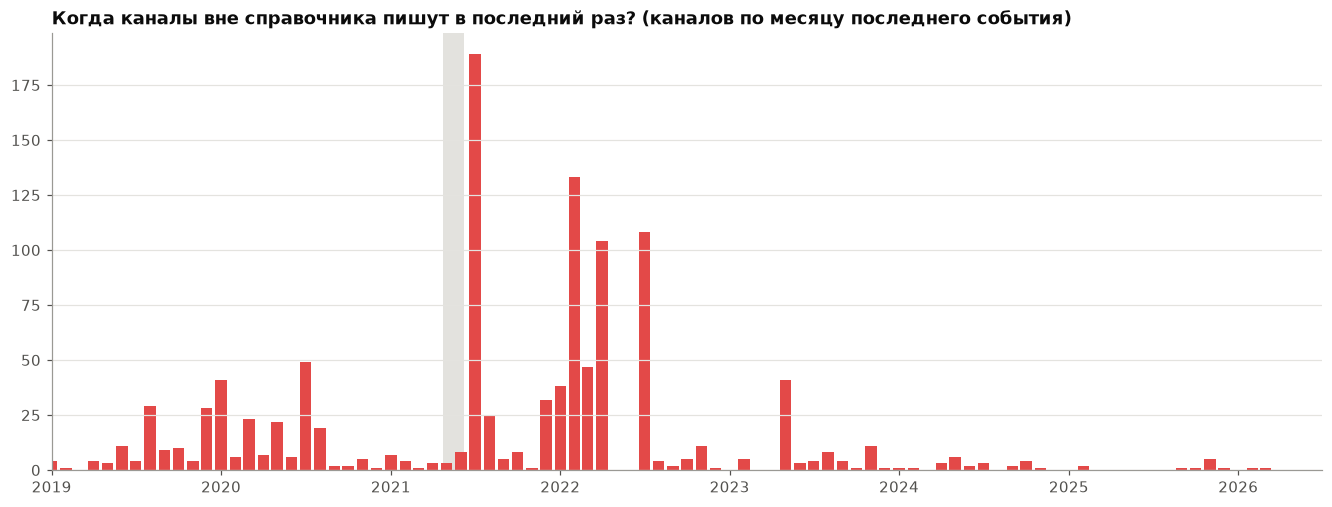

месяцы с наибольшим числом последних событий: {'2021-07': 189, '2022-02': 133, '2022-07': 108, '2022-04': 104, '2020-07': 49, '2022-03': 47}


In [49]:
# Когда каналы вне справочника пишут первый и последний раз
u_life = life[~life["в_справочнике"]]
display(u_life[["первый_день", "последний_день", "активных_дней", "количество_событий"]]
        .describe(percentiles=[.05, .25, .5, .75, .95]))
print("последнее событие по периодам:", u_life["последний_период"].value_counts(dropna=False).to_dict())
print("первое событие по периодам:", u_life["первый_период"].value_counts(dropna=False).to_dict())
fig, ax = plt.subplots()
lm = u_life.groupby(month_start(u_life["последний_день"])).size()
ax.bar(lm.index, lm.values, width=25, color=TYPE_COLOR[UNKNOWN])
ax.set_xlim(DATA_START, DATA_END)
shade_transition(ax)
ax.set_title("Когда каналы вне справочника пишут в последний раз? (каналов по месяцу последнего события)")
plt.show()
print("месяцы с наибольшим числом последних событий:", {f"{k:%Y-%m}": v for k, v in lm.nlargest(6).items()})

In [50]:
# Что пишут каналы вне справочника: класс записи и словарь состояний по периодам (витрина unknown_channels)
display(life[~life["не_писал"]]
        .groupby(["в_справочнике", "основной_класс"])
        .agg(каналов=("ид_канала_данных", "size"), строк=("количество_событий", "sum"),
             тревог=("количество_тревожных", "sum")))
unk["период_смву"] = smvu.period_of(unk["час"])
display(unk[unk["класс_записи"] == "состояние"]
        .pivot_table(index=["состояние", "тревожное"], columns="период_смву", values="количество_событий",
                     aggfunc="sum", fill_value=0)
        .reindex(columns=PER, fill_value=0).sort_values(smvu.ДО, ascending=False).head(20))
# Последний час с событием вне справочника по классу записи и периоду
unk.groupby(["класс_записи", "период_смву"]).agg(строк=("количество_событий", "sum"), первый_час=("час", "min"),
                                                 последний_час=("час", "max"))

каналов      строк   тревог
в_справочнике основной_класс                             
False         измерение           159     979551     1950
              состояние           983    8460104   149746
True          измерение           904  224027012    64186
              состояние         10581   79515409  2251096

,период_смву,до,переход,после
состояние,тревожное,,,
Движения нет,False,2131279,61832,535193
Обнаружено движение,False,2128011,61821,534031
Норма,False,516882,102770,702863
Неопределен,False,342315,96748,660926
Выключен,False,91128,6154,24919
Не замкнут,True,87976,2566,20386
Включен,False,87315,6022,22759
Не замкнут,False,71894,3231,18948
Обесточен,False,23782,2225,15768


строк          первый_час       последний_час
класс_записи период_смву                                                 
измерение    до            936228 2019-01-01 00:00:00 2021-04-22 06:00:00
             переход         6909 2021-04-22 07:00:00 2021-06-08 09:00:00
             после          16424 2021-06-08 10:00:00 2023-12-14 15:00:00
состояние    до           5554409 2019-01-01 01:00:00 2021-04-22 06:00:00
             переход       349948 2021-04-22 07:00:00 2021-06-08 09:00:00
             после        2575737 2021-06-08 10:00:00 2026-03-18 15:00:00

In [51]:
# Телеметрия вне справочника: на что похожи значения (газ – около 0…1, температура – десятки °C, раздел 4)
um = (daily_ch[~daily_ch["в_справочнике"] & (daily_ch["класс_записи"] == "измерение")]
      .groupby("ид_канала_данных").agg(медиана=("среднее_значение", "median"), максимум=("максимум_значения", "max"),
                                       последний_день=("день", "max")))
um["похоже_на"] = np.select([um["максимум"] <= 1, um["медиана"].between(5, 60)], ["газ", "температура"], "другое")
display(um.groupby("похоже_на").agg(каналов=("медиана", "size"), медиана=("медиана", "median"),
                                    последний_день=("последний_день", "max")))
# Диапазоны ID: вне справочника против каналов справочника
life["группа_id"] = np.select(
    [~life["в_справочнике"], life["не_писал"], life["последний_день"] < T1],
    [UNKNOWN, "справочник: не писал", "справочник: исчез до конца перехода"], "справочник: пишет после перехода")
life.groupby("группа_id")["ид_канала_данных"].describe(percentiles=[.05, .25, .5, .75, .95]).astype(int)

,каналов,медиана,последний_день
похоже_на,,,
газ,1,0.005000,2019-02-04
другое,26,0.013135,2023-12-14
температура,164,22.000000,2023-11-23


,count,mean,std,min,5%,25%,50%,75%,95%,max
группа_id,,,,,,,,,,
нет в справочнике,1142,142638,72619,2867,50665,51700,171425,197197,231843,330622
справочник: пишет после перехода,11485,219478,78460,2866,93584,162769,229484,278426,334013,337554


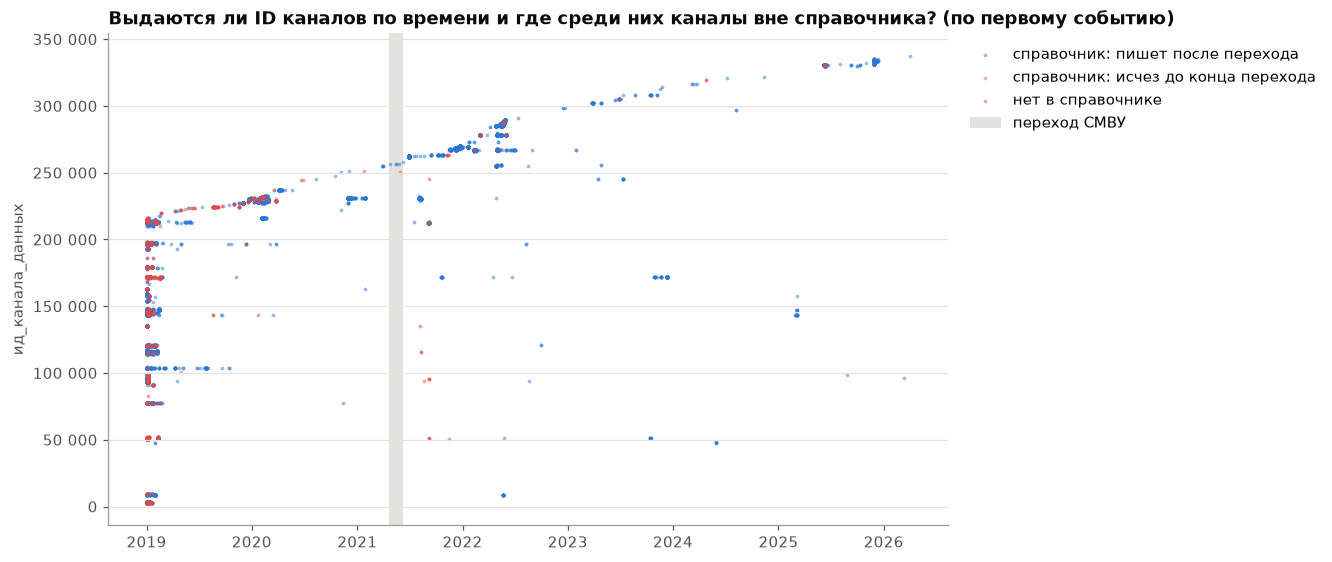

замолкли 2021-07-20: 181 каналов, ID 171379…171813, первое событие 2019-01-01…2019-02-21; строк по классу: {'измерение': 147096, 'состояние': 68625}
каналы вне справочника 28-29.06.2021: 470 каналов, 30,091 строк


In [52]:
fig, ax = plt.subplots(figsize=(12, 5))
for grp, color in [("справочник: пишет после перехода", PALETTE[0]),
                   ("справочник: исчез до конца перехода", PALETTE[1]), (UNKNOWN, TYPE_COLOR[UNKNOWN])]:
    d = life[life["группа_id"] == grp]
    ax.scatter(d["первый_день"], d["ид_канала_данных"], s=6, alpha=0.5, color=color, label=grp, lw=0)
shade_transition(ax)
thousands(ax)
ax.set_ylabel("ид_канала_данных")
ax.set_title("Выдаются ли ID каналов по времени и где среди них каналы вне справочника? (по первому событию)")
legend_right(ax)
plt.show()
# Крупнейшая волна исчезновения каналов вне справочника
top_day = u_life["последний_день"].value_counts().idxmax()
u_top = u_life[u_life["последний_день"] == top_day]
print(f"замолкли {top_day:%Y-%m-%d}: {len(u_top)} каналов, ID {u_top['ид_канала_данных'].min()}…{u_top['ид_канала_данных'].max()},",
      f"первое событие {u_top['первый_день'].min():%Y-%m-%d}…{u_top['первый_день'].max():%Y-%m-%d};",
      "строк по классу:", daily_ch[daily_ch["ид_канала_данных"].isin(u_top["ид_канала_данных"])]
      .groupby("класс_записи")["количество_событий"].sum().to_dict())
jun = daily_ch[daily_ch["день"].isin(pd.to_datetime(["2021-06-28", "2021-06-29"])) & ~daily_ch["в_справочнике"]]
print(f"каналы вне справочника 28-29.06.2021: {jun['ид_канала_данных'].nunique()} каналов, "
      f"{jun['количество_событий'].sum():,} строк")

**Гипотеза «каналы вне справочника – старая система» в сильной форме не подтверждается.**
- (а) До перехода они дают 10,35 % строк и **22,3 % тревог**, после – 1,07 % строк и 3,8 % тревог. Падение есть.
- (б) Но замолкают они не к концу перехода: из 1 142 каналов до T1 замолкают 312 (27,3 %), в переходе – 7.
  Остальные 830 пишут и после (медиана последнего события – 2021-12-29, 75-й перцентиль – 2022-04-28), а частота их
  тревог на живой канал через переход не меняется (3.6). Уходят они волнами после перехода: июль 2021 – 189 (из
  них 181 – 2021-07-20 одним блоком ID 171 379-171 813, все пишут с января-февраля 2019 года), февраль 2022 – 133,
  апрель – 104, июль – 108.
- (в) Пишут они то же, что и каналы справочника: состояния (983 канала, 8 460 104 строки – движение, «Норма»,
  «Неопределен», «Выключен/Включен», «Не замкнут», насосы АНС) и замеры (159 каналов, 979 551 строка; 164
  канала с замерами по значениям похожи на температуру, 1 – на газ, 26 не распознаны).
- (г) Своего диапазона ID нет: на графике точки обеих групп лежат в одних и тех же блоках 2019 года (медиана ID
  171 425 против 229 484 у справочника). Каналы справочника, появившиеся 28-29.06.2021, в те же дни пишут
  параллельно с 470 каналами вне справочника, так что это не замена «канал на канал».

Более правдоподобное объяснение: справочник – снимок текущей сети, а каналы вне справочника выведены из
эксплуатации в 2021-2023 годах. Подтвердить его может только заказчик (история справочника каналов).

### Итог раздела 3
Проверка рассказа заказчика о 2021 годе:
- **Параллельная работа систем – есть в данных, границы найдены.** Поток скачком растет 2021-04-22 в 07:38, полоса
  тревог дыма обрывается 2021-06-08 в 10:00. Найденные границы [2021-04-22 07:00, 2021-06-08 10:00) совпадают
  с константами `annanas.smvu`, проверка выше пройдена.
- **Аномально много тревог – да, но это одна пара «Датчик дыма / Неисправен»** на 77 каналах одного объекта
  (99,98 % тревог полосы). Без нее тревог в переходе даже меньше, чем до и после.
- **Неснятые тревоги – в журнале не видны.** Тревоги короткие (медиана эпизода 92 с), длиннее суток и открытых
  нет. Это частый дребезг, а не висящие тревоги. Реакцию операторов журнал не хранит.
- **Устройство данных после перехода не изменилось:** каналы, их ID и словарь состояний те же, дублей двух систем
  нет, частота тревог на канал сопоставима. Рост потока после перехода – сезонный газ одного объекта, а
  устойчивая ступень потока была раньше, в октябре 2020 года.
- **Каналы вне справочника – не старая система**, а, скорее всего, выведенные позже каналы; до перехода на них
  приходится 22,3 % тревог, у которых нет типа и объекта.
- Сразу после перехода, 2021-06-28 … 2021-07-03, есть короткое возмущение (тревоги вентиляторов и газа, провал
  потока вдвое).

Для модели: сам переход и возмущение после него – маска, данные до перехода пригодны с признаком эпохи, а флаг
`тревожное` дрейфует по годам независимо от перехода.

## 4. Телеметрия: газ, температура, ИБП
Замеры – 83 % потока, но тревог по ним мы пока не видели. Вопросы: какие значения принимает телеметрия, есть
ли в ней коды ошибок вместо физики, бывают ли тревожные замеры, как часто опрашиваются датчики и какое молчание
датчика нормально, а какое – уже событие.

In [53]:
# Замеры канало-дня: минимальное и максимальное значение. Значения, которые повторяются точно в тысячах канало-дней
# на краях распределения, – кандидаты в коды ошибок датчика
meas = daily_ch[daily_ch["класс_записи"] == "измерение"].copy()
for col, q in [("минимум_значения", 0.01), ("максимум_значения", 0.99)]:
    rows = []
    for tp in [GAS, "Датчик температуры"]:
        s = meas.loc[meas["тип_датчика"] == tp, col].astype("float64").round(2)
        tail = s[s <= s.quantile(q)] if q < 0.5 else s[s >= s.quantile(q)]
        rows.append(tail.value_counts().head(5).rename(tp))
    print(f"самые частые значения в хвосте «{col}» (канало-дней):")
    display(pd.concat(rows, axis=1).fillna(0).astype(int))

самые частые значения в хвосте «минимум_значения» (канало-дней):


,Газовый датчик,Датчик температуры
минимум_значения,,
0.00,301602,0
-0.01,650,0
-2.56,416,0
-0.02,328,0
-0.04,194,0
-127.00,0,5219
-3260.00,0,42
-3276.00,0,13
-3251.00,0,11


самые частые значения в хвосте «максимум_значения» (канало-дней):


,Газовый датчик,Датчик температуры
максимум_значения,,
1.50,788,0
1.46,448,0
2.55,411,0
1.51,337,0
1.49,328,0
33.00,0,1801
35.00,0,601
34.00,0,558
36.00,0,204


In [54]:
# Коды ошибок датчиков по событиям: сколько событий, каналов и дней
SENTINELS = [327.68, -10.23, 2.55, -2.56, -127.0, 128.0, -3276.0, 999.0, 666.0]
codes = (events.filter((F.col("класс_записи") == "измерение") & F.col("числовое_значение").isin(SENTINELS))
         .join(F.broadcast(channels.select("ид_канала_данных", "тип_датчика")), "ид_канала_данных", "left")
         .fillna({"тип_датчика": UNKNOWN})
         .groupBy("тип_датчика", "числовое_значение")
         .agg(F.count("*").alias("событий"), F.countDistinct("ид_канала_данных").alias("каналов"),
              F.countDistinct(F.to_date("дата_время")).alias("дней"))
         .orderBy("тип_датчика", F.desc("событий")).toPandas())
codes

,тип_датчика,числовое_значение,событий,каналов,дней
0,Газовый датчик,-2.56,666,29,194
1,Газовый датчик,2.55,631,30,191
2,Газовый датчик,327.68,5,5,4
3,Газовый датчик,-10.23,1,1,1
4,Датчик температуры,-127.00,8105,370,303
5,Датчик температуры,128.00,196,18,21
6,Датчик температуры,-3276.00,16,10,12
7,Датчик температуры,999.00,3,2,2
8,нет в справочнике,-127.00,1496,94,115
9,нет в справочнике,-3276.00,1,1,1


В хвостах распределений выделяются значения, которые повторяются точно: у газа 2,55 (максимум дня в 411 канало-днях)
и −2,56 (минимум в 416), у температуры −127 (минимум дня в 5 219 канало-днях) и значения около −3 250 … −3 276. Физикой они быть не могут (−127 °C
в коллекторе), а похожи на граничные значения 8- и 16-битных регистров: −127/128, 327,68 = 32 768 / 100, −3 276.
Верхний хвост температуры (33-37 °C) – обычные значения, код 128 редкий и в пятерку не попадает. Считаем их кодами ошибок датчика. Температура: −127 (8 105 событий, 370
каналов, еще 1 496 у каналов вне справочника), 128 (196), −3 276 (16), 999 (3). Газ: 2,55 и −2,56 (631 и 666
событий у 29-30 каналов), 327,68 (5), −10,23 (1). Это наша интерпретация; подтвердить ее могут организаторы.

In [55]:
# Робастная статистика значений: канало-дни с кодом ошибки (минимум или максимум дня – код) исключены
meas["день_с_кодом"] = (meas["минимум_значения"].astype("float64").round(2).isin(SENTINELS)
                        | meas["максимум_значения"].astype("float64").round(2).isin(SENTINELS))
meas_ok = meas[~meas["день_с_кодом"]]
print("канало-дней с кодом ошибки по типам:",
      meas.groupby("тип_датчика")["день_с_кодом"].sum().loc[lambda s: s > 0].to_dict())
(meas_ok.groupby("тип_датчика")[["минимум_значения", "среднее_значение", "максимум_значения"]]
 .quantile([.01, .05, .5, .95, .99]).unstack().T.round(3))

канало-дней с кодом ошибки по типам: {'Газовый датчик': 616, 'Датчик температуры': 5255, 'нет в справочнике': 1142}


тип_датчика             Газовый датчик  Датчик движения  Датчик температуры   ИБП  КД АВ  КД Дверь  Состояние охраны  Состояние фазы  нет в справочнике
минимум_значения  0.01           0.000            4.984                1.00   3.0    0.0     0.196               NaN           0.353              0.000
                  0.05           0.000            5.320                5.00   4.0    0.0     0.980               NaN           1.765              0.020
                  0.50           0.000            9.000               17.00   4.0    0.0     5.000               NaN          17.650             21.000
                  0.95           0.090            9.800               27.00   8.0    0.0   797.000               NaN          33.535             31.000
                  0.99           0.170            9.960               31.00  11.0    0.0   955.400               NaN          34.947             34.000
среднее_значение  0.01           0.005            4.984                3.00   3.0    0.0     0.196               NaN           0.683              0.005
                  0.05           0.005            5.320                6.25   4.0    0.0     0.980               NaN           2.082              0.042
                  0.50           0.006            9.000               18.00   5.0    0.0     5.000               NaN          17.817             22.000
                  0.95           0.115            9.800               28.00   8.5    0.0   797.000               NaN          33.552             32.000
                  0.99           0.305            9.960               32.00  18.0    0.0   955.400               NaN          34.950             35.200
максимум_значения 0.01           0.010            4.984                3.00   4.0    0.0     0.196               NaN           1.343              0.010
                  0.05           0.010            5.320                7.00   4.0    0.0     0.980               NaN           2.715              0.060
                  0.50           0.030            9.000               19.00   5.0    0.0     5.000               NaN          18.150             24.000
                  0.95           0.140            9.800               29.00   9.0    0.0   797.000               NaN          33.585             34.000
                  0.99           1.450            9.960               32.00  23.0    0.0   955.400               NaN          34.957             37.000

In [56]:
# Тревожные замеры: есть ли они и у каких типов
meas.groupby(["тип_датчика", "год"])["количество_тревожных"].sum().unstack(fill_value=0)

год,2019,2020,2021,2022,2023,2024,2025,2026
тип_датчика,,,,,,,,
Газовый датчик,0,0,0,0,0,0,0,0
Датчик движения,0,0,0,0,0,0,0,0
Датчик температуры,0,0,0,0,0,0,0,0
ИБП,0,0,0,0,0,0,0,0
КД АВ,0,0,0,0,0,0,0,0
КД Дверь,0,0,0,0,0,0,0,0
Состояние охраны,0,0,0,0,0,0,0,0
Состояние фазы,0,0,0,0,0,0,0,0
нет в справочнике,0,0,0,0,0,0,0,0


Без кодов ошибок газ почти всегда около нуля: среднее за день с медианой 0,006 и p99 0,305, максимум за день
с медианой 0,03 и p99 1,45. Температура: среднее за день с медианой 18 °C, p1-p99 от 3 до 32 °C. ИБП: медиана 5,
p1-p99 от 3 до 18. Замеры у движения, КД Дверь и КД АВ – единичные канало-дни, шум справочника.

**Тревожных замеров нет вообще: 0 по всем типам и годам.** Тревожность у газа и температуры живет только в
состояниях: «Обнаружен газ», «Температура ниже 3ºC / выше 40ºC» (раздел 5). Значит, признаки телеметрии придется
строить как отклонение от нормы канала – порогов в числах журнал не дает.

Следующий вопрос – как часто пишет телеметрия.

год,2019,2020,2021,2022,2023,2024,2025,2026
тип_датчика,,,,,,,,
Газовый датчик,62.0,62.0,31.0,20.0,17.0,12.0,10.0,10.0
Датчик движения,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Датчик температуры,24311.0,20772.0,28588.5,26144.0,26746.5,32272.0,25017.5,37568.0
ИБП,44479.5,37584.5,153716.0,71717.0,60538.0,111600.0,272987.0,189962.0
КД АВ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
КД Дверь,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Состояние охраны,28535.0,26957.0,29895.0,28648.5,27646.0,27813.0,28240.0,29617.0
Состояние фазы,NaN,NaN,46.0,NaN,NaN,NaN,NaN,NaN
нет в справочнике,8945.0,8416.0,14973.0,31870.0,6787.0,NaN,NaN,NaN


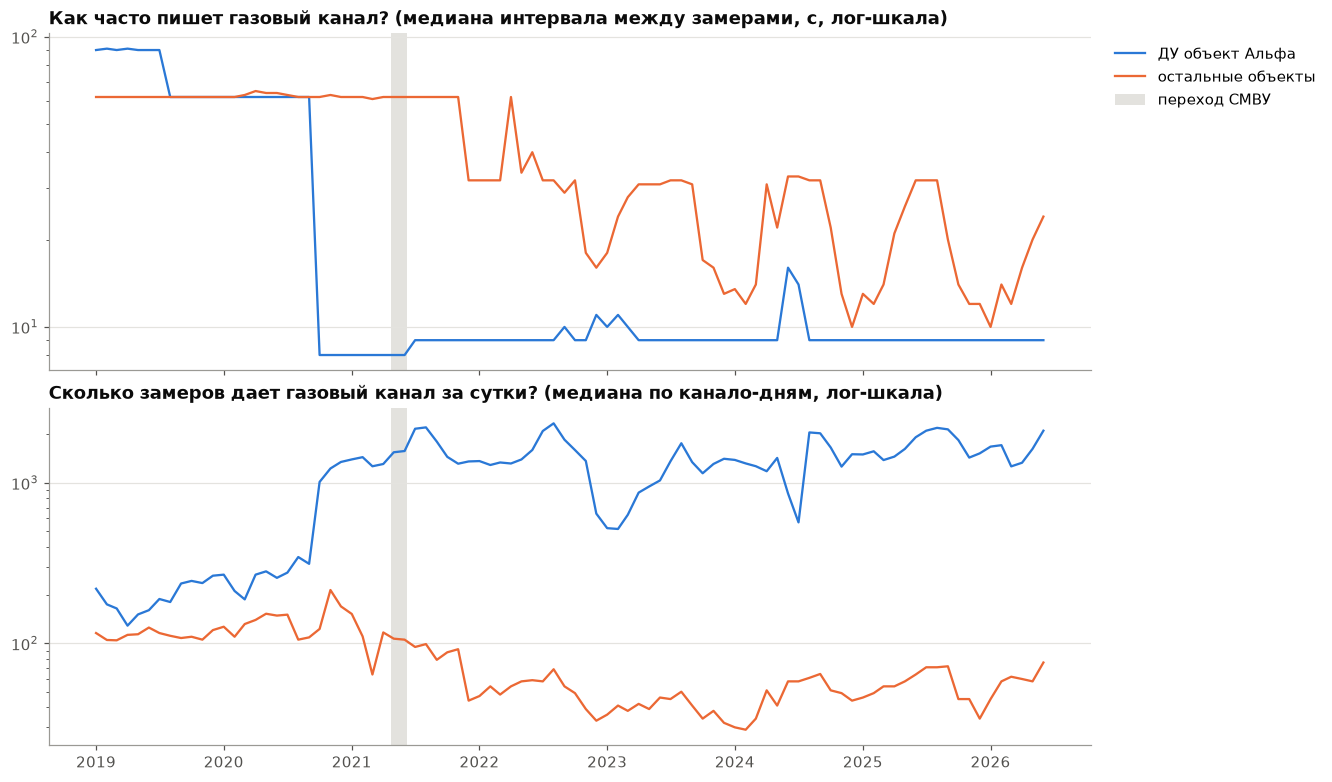

интервал       замеров         каналов      
альфа         False True    False   True    False True 
день                                                   
2020-08-01     62.0  62.0   106.0   345.0      60    49
2020-09-01     62.0  62.0   109.0   313.0      47    55
2020-10-01     62.0   8.0   123.0  1013.0      73    55
2020-11-01     63.0   8.0   215.0  1228.0      73    54
2020-12-01     62.0   8.0   170.0  1349.0     101    55
2021-01-01     62.0   8.0   152.0  1399.0      95    53
2021-04-01     62.0   8.0   117.0  1310.0     122    44
2021-07-01     62.0   9.0    95.0  2172.0     119    53
2022-01-01     32.0   9.0    47.0  1366.0     166    54
2022-07-01     32.0   9.0    58.0  2103.0     290    54
2023-01-01     18.0  10.0    36.0   522.0     235    26
2023-07-01     32.0   9.0    45.0  1362.0     300    26
2024-01-01     14.0   9.0    30.0  1389.0     203    55
2024-07-01     33.0  14.0    58.0   567.0     277    53
2025-01-01     13.0   9.0    46.0  1502.0     229    53
2025-07-01     32.0   9.0    71.0  2112.0     286    54
2026-01-01     10.0   9.0    45.0  1681.0     158    53

In [57]:
# Медиана интервала опроса, с (медиана по канало-дням), по типам и годам
display(gaps.groupby(["тип_датчика", "год"])["медианный_интервал_с"].median().unstack())

# Газ: Альфа против остальных объектов по месяцам – годовая медиана смешивает две разные группы
gg = gaps[gaps["тип_датчика"] == GAS].assign(альфа=lambda d: d["ид_объект"] == ALPHA)
gm = (gg.groupby([month_start(gg["день"]), "альфа"])
      .agg(интервал=("медианный_интервал_с", "median"), замеров=("количество_замеров", "median"),
           каналов=("ид_канала_данных", "nunique")).unstack("альфа"))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for is_alpha, color, lbl in [(True, PALETTE[0], "ДУ объект Альфа"), (False, PALETTE[1], "остальные объекты")]:
    axes[0].plot(gm.index, gm[("интервал", is_alpha)], color=color, label=lbl)
    axes[1].plot(gm.index, gm[("замеров", is_alpha)], color=color, label=lbl)
axes[0].set_title("Как часто пишет газовый канал? (медиана интервала между замерами, с, лог-шкала)")
axes[1].set_title("Сколько замеров дает газовый канал за сутки? (медиана по канало-дням, лог-шкала)")
for ax in axes:
    ax.set_yscale("log")
    shade_transition(ax)
legend_right(axes[0])
plt.show()
gm.loc[[m for m in gm.index if (m.year == 2020 and m.month >= 8) or (m.year == 2021 and m.month in (1, 4, 7))
        or (m.year >= 2022 and m.month in (1, 7))]].round(0)

Годовая медиана интервала газа 62 → 31 → 20 → 17 → 12 → 10 с (2019-2026) выглядит как плавное учащение опроса,
но это артефакт смеси двух групп. По месяцам видно:
- у Альфы интервал 62 с до сентября 2020 и 8-10 с с **октября 2020** (замеров на канало-день 313 → 1 013). Это и
  есть ступень потока осени 2020 года из раздела 1. Дальше частота меняется конфигурационно: 1 300-2 200 замеров на
  канало-день, но 522 в январе 2023 и 567 в июле 2024 (раздел 6);
- у остальных объектов 62 с до 2021 года, с 2022 года 10-33 с с сезонным ходом (зимой 10-18 с, летом 32-33 с), но
  всего 30-71 замер на канало-день. Они пишут пачками. Гипотеза: запись по изменению значения (с зоной
  нечувствительности), а не по таймеру; проверить ее можно только у организаторов.

Температура пишет раз в 6-10 ч (медиана интервала 20 772-37 568 с), «Состояние охраны» – примерно раз в 8 ч,
ИБП – раз в 10-76 ч (37 584-272 987 с). Какое молчание телеметрии считать событием? Проверим несколько порогов.

In [58]:
# Молчание телеметрии: доля канало-дней, в которых самый длинный интервал между замерами больше порога.
# Пороги абсолютные (10 мин … 24 ч) и относительный – 10 × медиана интервала этого канала за год
ch_med = gaps.groupby(["ид_канала_данных", "год"])["медианный_интервал_с"].transform("median")
mx = gaps["максимальный_интервал_с"]
sil_rules = {"> 10 мин": mx > 600, "> 1 ч": mx > 3600, "> 6 ч": mx > 6 * 3600, "> 24 ч": mx > 86400,
             "> 10 × медианы канала": mx > 10 * ch_med}
sil = pd.concat({k: v.groupby([gaps["группа"], gaps["год"]]).mean() for k, v in sil_rules.items()}, names=["порог"])
sil = sil.unstack("год").swaplevel().sort_index()
display(sil.loc[["газ: Альфа", "газ: остальные", "Датчик температуры"]].round(3))
print("медиана самого длинного интервала за канало-день, ч:")
(gaps.groupby(["группа", "год"])["максимальный_интервал_с"].median() / 3600).unstack().round(1)

год                                        2019   2020   2021   2022   2023   2024   2025   2026
группа             порог                                                                        
газ: Альфа         > 1 ч                  0.757  0.538  0.195  0.103  0.397  0.142  0.071  0.121
                   > 10 × медианы канала  0.998  0.982  1.000  1.000  1.000  1.000  1.000  1.000
                   > 10 мин               0.999  0.972  0.837  0.854  0.912  0.861  0.870  0.858
                   > 24 ч                 0.097  0.078  0.025  0.004  0.013  0.006  0.003  0.008
                   > 6 ч                  0.357  0.236  0.084  0.028  0.145  0.025  0.011  0.009
газ: остальные     > 1 ч                  0.887  0.825  0.833  0.905  0.928  0.930  0.918  0.882
                   > 10 × медианы канала  0.989  0.982  0.982  0.989  0.992  0.993  0.990  0.986
                   > 10 мин               0.990  0.985  0.985  0.990  0.993  0.994  0.992  0.978
                   > 24 ч                 0.133  0.131  0.144  0.131  0.151  0.143  0.133  0.111
                   > 6 ч                  0.652  0.512  0.564  0.604  0.636  0.611  0.578  0.512
Датчик температуры > 1 ч                  0.990  0.991  0.989  0.990  0.991  0.990  0.991  0.979
                   > 10 × медианы канала  0.284  0.327  0.347  0.278  0.281  0.231  0.300  0.229
                   > 10 мин               0.990  0.991  0.990  0.990  0.991  0.990  0.991  0.980
                   > 24 ч                 0.472  0.477  0.535  0.498  0.494  0.519  0.482  0.546
                   > 6 ч                  0.976  0.979  0.976  0.970  0.967  0.966  0.966  0.958

медиана самого длинного интервала за канало-день, ч:


год,2019,2020,2021,2022,2023,2024,2025,2026
группа,,,,,,,,
Датчик движения,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Датчик температуры,23.0,23.2,27.8,24.1,23.9,26.2,23.4,29.6
ИБП,77.6,64.2,315.5,101.4,71.8,289.8,277.2,134.9
КД АВ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
КД Дверь,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Состояние охраны,16.3,14.8,14.9,15.1,15.3,15.4,15.4,15.0
Состояние фазы,NaN,NaN,0.2,NaN,NaN,NaN,NaN,NaN
газ: Альфа,3.2,1.1,0.4,0.4,0.6,0.4,0.4,0.4
газ: остальные,9.3,6.3,7.5,8.1,8.7,8.1,7.6,6.2


Ни «молчание > 10 мин», ни относительный порог «10 × медиана интервала канала» ничего не различают: у газа они
срабатывают в 84-100 % канало-дней, у температуры порог 10 мин – в 98-99 %. Газовые каналы пишут пачками, а между
ними часами молчат. Различать можно только по группам:
- у Альфы интервал > 6 ч бывает в 0,9-2,8 % канало-дней с 2022 года (14,5 % в 2023-м, когда половина каналов
  молчала), > 24 ч – в 0,3-1,3 %. Для Альфы молчание от нескольких часов – уже событие;
- у остальных газовых объектов > 6 ч – 51-65 % канало-дней, > 24 ч – 11-15 %, медиана самого длинного интервала
  6-9 ч. Для них событием может быть только молчание от суток;
- температура: самый длинный интервал за канало-день в медиане 23-30 ч, > 24 ч – в 47-55 % канало-дней.

Поэтому покрытие телеметрией ниже меряем не интервалом, а долей «живых» канало-дней без единого замера.

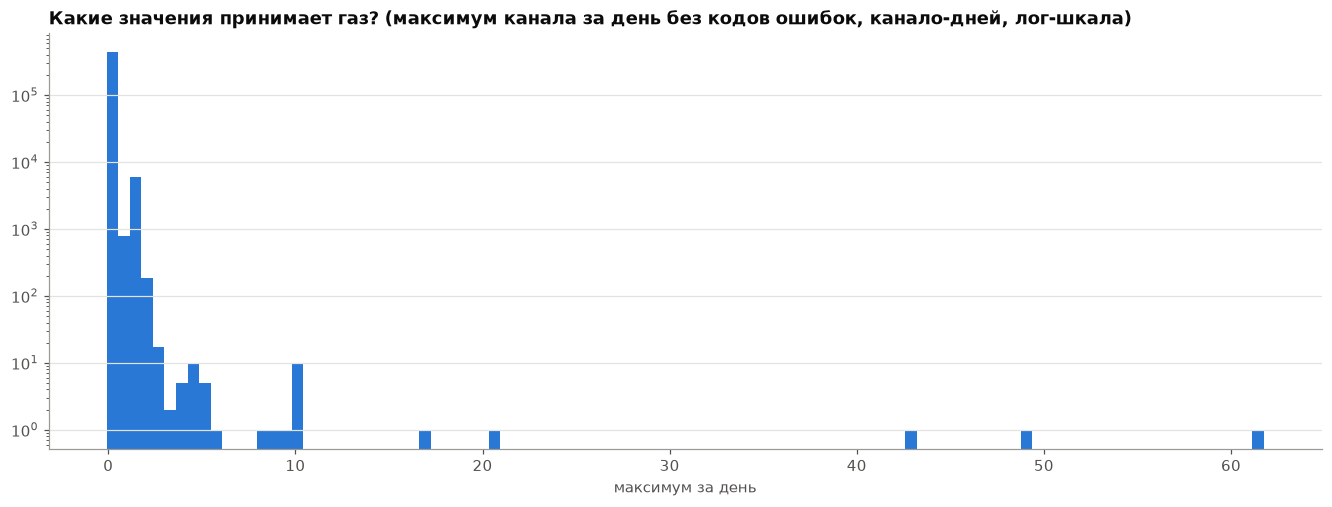

In [59]:
gas = meas_ok[meas_ok["тип_датчика"] == GAS]
fig, ax = plt.subplots()
ax.hist(gas["максимум_значения"].dropna(), bins=100, color=TYPE_COLOR.get(GAS, PALETTE[0]))
ax.set_yscale("log")
ax.set_title("Какие значения принимает газ? (максимум канала за день без кодов ошибок, канало-дней, лог-шкала)")
ax.set_xlabel("максимум за день")
plt.show()

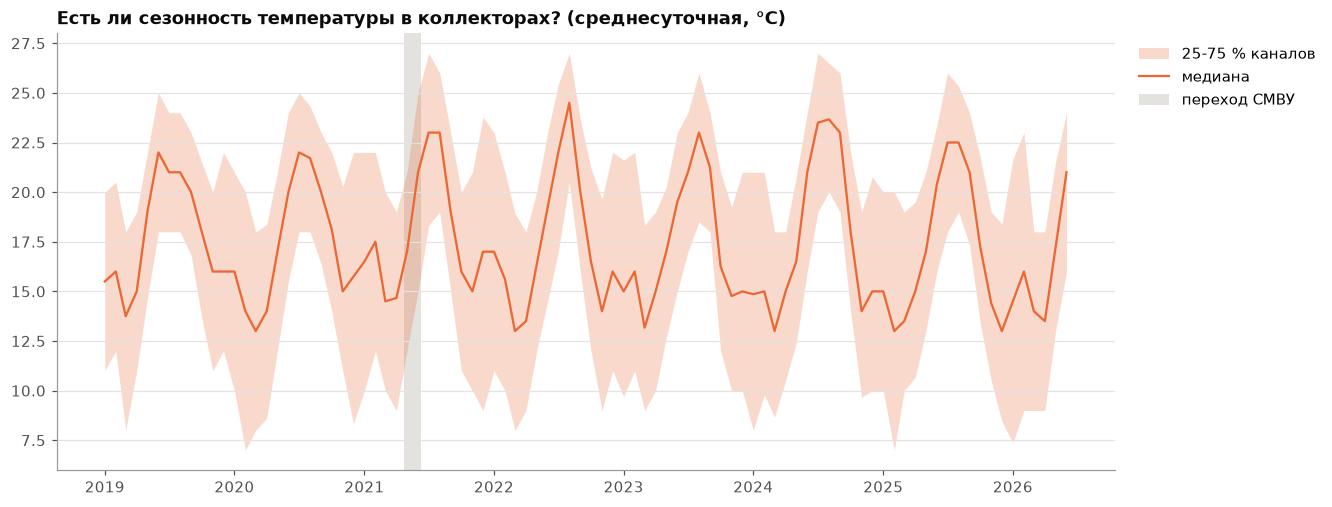

день,1,2,3,4,5,6,7,8,9,10,11,12
min,14.5,13.0,13.0,13.5,16.3,19.2,21.0,21.0,19.0,16.0,14.0,13.0
median,15.2,15.8,13.3,14.8,17.0,20.7,22.0,23.0,20.0,17.2,14.8,15.7
max,17.0,17.5,14.5,15.0,19.0,22.0,23.5,24.5,23.0,18.1,16.0,17.0


In [60]:
# Температура: месячная медиана по каналам (сезонность) и межквартильный разброс между каналами
temp = meas_ok[meas_ok["тип_датчика"] == "Датчик температуры"]
tm = temp.groupby(month_start(temp["день"]))["среднее_значение"].quantile([.25, .5, .75]).unstack()
fig, ax = plt.subplots()
c = TYPE_COLOR.get("Датчик температуры", PALETTE[1])
ax.fill_between(tm.index, tm[0.25], tm[0.75], color=c, alpha=0.25, lw=0, label="25-75 % каналов")
ax.plot(tm.index, tm[0.5], color=c, label="медиана")
shade_transition(ax)
ax.set_title("Есть ли сезонность температуры в коллекторах? (среднесуточная, °C)")
legend_right(ax)
plt.show()
tm.groupby(tm.index.month)[0.5].agg(["min", "median", "max"]).round(1).T

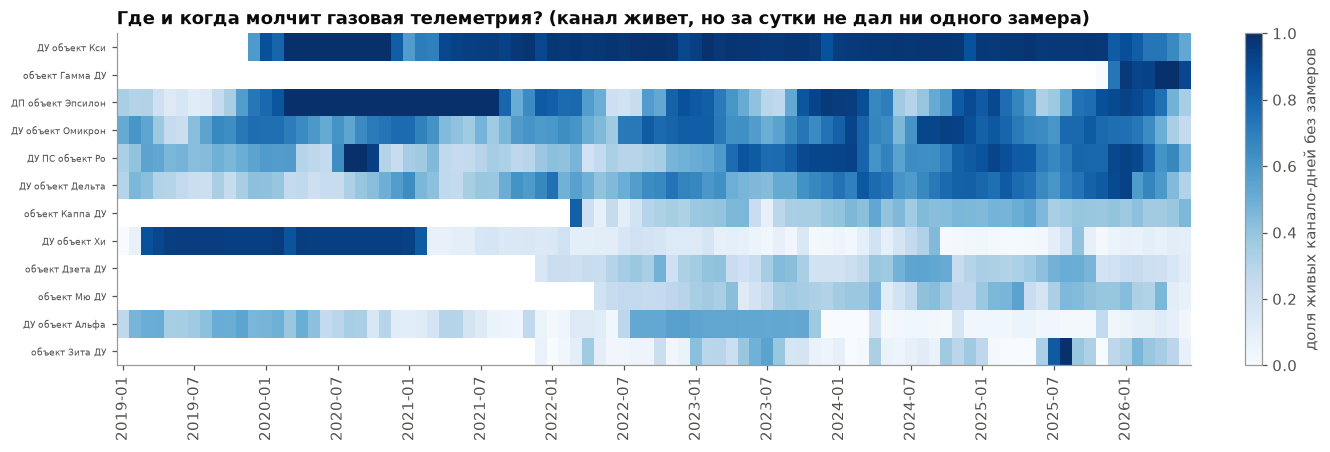

доля живых канало-дней газа без замеров по годам: {2019: 0.436, 2020: 0.697, 2021: 0.555, 2022: 0.492, 2023: 0.559, 2024: 0.559, 2025: 0.565, 2026: 0.433}


In [61]:
# Покрытие газовой телеметрией: доля «живых» канало-дней (между первым и последним замером канала) без единого
# замера, объект × месяц. Пусто (белое) – у объекта в этом месяце нет живых газовых каналов
gl = (meas[meas["тип_датчика"] == GAS].groupby("ид_канала_данных")["день"].agg(["min", "max"])
      .join(channels_pd.set_index("ид_канала_данных")["ид_объект"]))
alive = pd.concat([pd.DataFrame({"ид_канала_данных": c, "ид_объект": r["ид_объект"], "день": pd.date_range(r["min"], r["max"])})
                   for c, r in gl.iterrows()])
measured = meas.loc[meas["тип_датчика"] == GAS, ["ид_канала_данных", "день"]].assign(есть_замеры=1)
alive = alive.merge(measured, on=["ид_канала_данных", "день"], how="left").fillna({"есть_замеры": 0})
heat = 1 - alive.groupby(["ид_объект", month_start(alive["день"])])["есть_замеры"].mean().unstack()
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(12, max(4, 0.18 * len(heat))))
im = ax.imshow(heat.values, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
ticks = np.arange(0, heat.shape[1], 6)
ax.set_xticks(ticks, [f"{heat.columns[i]:%Y-%m}" for i in ticks], rotation=90)
ax.set_yticks(range(len(heat)), [obj_names.get(o, UNKNOWN) for o in heat.index], fontsize=6)
ax.grid(False)
fig.colorbar(im, ax=ax, label="доля живых канало-дней без замеров")
ax.set_title("Где и когда молчит газовая телеметрия? (канал живет, но за сутки не дал ни одного замера)")
plt.show()
print("доля живых канало-дней газа без замеров по годам:",
      (1 - alive.groupby(alive["день"].dt.year)["есть_замеры"].mean()).round(3).to_dict())

In [62]:
# Сопоставимы ли значения телеметрии до, во время и после перехода СМВУ (2020-2022, без кодов ошибок)
m20 = window(meas_ok, "2020-01-01", "2023-01-01")
m20.groupby([m20["тип_датчика"], smvu.period_of(m20["день"]).rename("период_смву")])["среднее_значение"].describe(
    percentiles=[.05, .5, .95]).round(3)

count     mean      std       min      5%     50%      95%      max
тип_датчика        период_смву                                                                        
Газовый датчик     до            43792.0    0.037    0.131    -0.194   0.005   0.013    0.135   21.300
                   переход        5807.0    0.028    0.038    -0.105   0.005   0.015    0.089    0.638
                   после        102340.0    0.028    0.070    -0.089   0.005   0.006    0.090    4.817
Датчик движения    после             4.0    8.750    1.258     7.000   7.300   9.000    9.850   10.000
Датчик температуры до            51992.0   17.143   14.208 -1622.000   5.000  18.000   27.726  197.000
                   переход        6147.0   16.879    5.788    -4.300   8.000  17.000   26.000   47.333
                   после         71438.0   17.984   24.466 -1623.500   7.000  18.500   29.000   66.000
ИБП                до              386.0    5.375    2.598     2.000   4.000   5.000    7.300   28.000
                   переход          23.0    5.800    1.986     3.000   4.000   5.000    9.950   10.000
                   после           544.0    5.694    4.073     2.500   4.000   4.667    9.455   48.000
КД Дверь           после             4.0  251.250  495.839     0.000   0.750   5.000  846.500  995.000
Состояние охраны   до                0.0      NaN      NaN       NaN     NaN     NaN      NaN      NaN
                   переход           0.0      NaN      NaN       NaN     NaN     NaN      NaN      NaN
                   после             0.0      NaN      NaN       NaN     NaN     NaN      NaN      NaN
Состояние фазы     после             1.0    0.333      NaN     0.333   0.333   0.333    0.333    0.333
нет в справочнике  до            31205.0   22.106    7.086    -8.000  10.000  22.667   33.000   78.978
                   переход        2330.0   21.600    5.211     4.000  12.000  22.000   29.000   35.000
                   после          6138.0   21.933    7.417    -1.000   8.000  23.000   32.000   39.000

**Итог раздела 4.**
- Числовых тревог нет; есть коды ошибок датчика (−127, 128, −3 276, 999 у температуры; 2,55, −2,56, 327,68 у
  газа), канало-дней с кодом 5 255 у температуры и 616 у газа.
- Опрос газа – две разные группы: Альфа пишет раз в 8-10 с с октября 2020 года (до этого раз в 62 с), остальные
  объекты пишут пачками по 30-70 замеров в сутки. Ступень потока осени 2020 года – это смена опроса Альфы.
- «Молчание > 10 мин» для телеметрии бессмысленно; событием молчание становится у Альфы от нескольких часов, у
  остальных газовых объектов – от суток.
- Даже у живого газового канала 43-70 % канало-дней в году проходят без замеров. На карте покрытия видно, где
  телеметрии нет месяцами: «ДУ объект Кси» почти без замеров с начала 2020 года, «ДП объект Эпсилон» – с весны
  2020 по лето 2021, «ДУ объект Хи» – с весны 2019 по лето 2021; у Альфы с июля 2022 по ноябрь 2023 молчит
  половина каналов; Каппа, Дзета, Мю, Зита подключены в 2022 году, Гамма – в конце 2025-го.
- Температура сильно сезонна: месячная медиана по каналам минимальна в марте (13,3 °C в медиане по годам)
  и максимальна в августе (23,0 °C), разброс между каналами около ±5 °C. Распределения до, во время и после
  перехода сопоставимы: медиана газа 0,013 / 0,015 / 0,006, температуры 18,0 / 17,0 / 18,5 °C.

## 5. Состояния и тревоги
Тревоги живут только в состояниях. Вопросы: какие пары (тип, состояние) бывают и какие из них тревожные;
постоянна ли тревожность состояния; сколько длятся тревоги и где кончается дребезг; что следует за тревогой;
как часто тревоги повторяются. Из ответов складываются кандидаты в классы инцидентов.

In [63]:
voc = vocab.groupby(["тип_датчика", "состояние", "тревожное"])["количество_событий"].sum().reset_index()
voc_t = voc.pivot_table(index=["тип_датчика", "состояние"], columns="тревожное", values="количество_событий",
                        fill_value=0)
voc_t = voc_t.rename(columns={False: "не_тревожных", True: "тревожных"})
voc_t["доля_тревожных"] = (voc_t.get("тревожных", 0) / voc_t.sum(axis=1)).round(3)
print(f"пар (тип, состояние): {len(voc_t)}; записей состояний {voc['количество_событий'].sum():,}, "
      f"тревожных {voc.loc[voc['тревожное'], 'количество_событий'].sum():,}")
with pd.option_context("display.max_rows", 400):
    display(voc_t)

пар (тип, состояние): 199; записей состояний 88,237,751, тревожных 2,466,978


тревожное                                             не_тревожных  тревожных  доля_тревожных
тип_датчика           состояние                                                              
9-секционный люк      Выключен                                 4.0        0.0           0.000
                      Не замкнут                               0.0       73.0           1.000
                      Неисправен                               0.0       14.0           1.000
                      Неопределен                            159.0        0.0           0.000
                      Норма                                  252.0        0.0           0.000
Газовый датчик        Выключен                              5731.0        0.0           0.000
                      Не замкнут                               0.0        1.0           1.000
                      Неисправен                            5385.0    43646.0           0.890
                      Неопределен                         403465.0        0.0           0.000
                      Норма                               469361.0        0.0           0.000
                      Обнаружен газ                         7731.0    10089.0           0.566
                      Отключено устройство                    14.0      113.0           0.890
                      Рычаг норма                              2.0        0.0           0.000
Датчик движения       В норме от +3 до +40                     4.0        0.0           0.000
                      Выключен                               699.0        0.0           0.000
                      Движения нет                      25468145.0        0.0           0.000
                      Не замкнут                           99192.0      197.0           0.002
                      Неисправен                             630.0     1185.0           0.653
                      Неопределен                         132176.0        0.0           0.000
                      Норма                               234697.0        0.0           0.000
                      Обесточен                                2.0        0.0           0.000
                      Обнаружено движение               25265180.0   202943.0           0.008
                      Отключено устройство                   804.0      354.0           0.306
                      Питание от сети                          1.0        0.0           0.000
Датчик дыма           Выключен                              3632.0        0.0           0.000
                      Движения нет                            14.0        0.0           0.000
                      Дыма нет                            165663.0        0.0           0.000
                      Есть питание                             1.0        0.0           0.000
                      Не замкнут                             211.0       37.0           0.149
                      Неисправен                           44424.0  1124754.0           0.962
                      Неопределен                         644782.0        0.0           0.000
                      Норма                              1807913.0        0.0           0.000
                      Обесточен                                2.0        0.0           0.000
                      Обнаружен дым                       121701.0    42427.0           0.258
                      Отключено устройство                   536.0     3429.0           0.865
Датчик затопления     Выключен                                 9.0        0.0           0.000
                      Движения нет                             2.0        0.0           0.000
                      Не замкнут                               6.0     3726.0           0.998
                      Неисправен                               0.0        8.0           1.000
                      Неопределен                           2457.0        0.0           0.000
                      Норма                         

In [64]:
# Состояния, у которых тревожность зависит от типа или от времени (одно название – оба значения флага)
mixed = voc.groupby("состояние")["тревожное"].nunique().loc[lambda s: s > 1].index
with pd.option_context("display.max_rows", 400):
    display(voc[voc["состояние"].isin(mixed)].sort_values(["состояние", "тип_датчика"]))

,тип_датчика,состояние,тревожное,количество_событий
71,ИБП,Батарея разряжена,False,22
72,ИБП,Батарея разряжена,True,202
213,нет в справочнике,Батарея разряжена,True,85
167,Состояние насоса,Затоплен,False,8606
168,Состояние насоса,Затоплен,True,53656
221,нет в справочнике,Затоплен,False,372
222,нет в справочнике,Затоплен,True,1780
180,Состояние охраны,Много неисправных устройств,False,34
181,Состояние охраны,Много неисправных устройств,True,8083
223,нет в справочнике,Много неисправных устройств,True,704


Записей состояний 88 237 751, из них тревожных 2 466 978; пар (тип, состояние) 199. Тревожность задается парой
(тип, состояние), и у многих состояний она смешанная: «Датчик дыма / Обнаружен дым» тревожен в 25,8 % случаев,
«Газовый датчик / Обнаружен газ» – в 56,6 %, «Датчик движения / Обнаружено движение» – в 0,8 %, «КД Дверь /
Не замкнут» – в 1,7 %, а «КД АВ / Не замкнут» – в 96,1 %. В разделе 3.5 мы видели, что доля тревожных у одной
пары плавает по годам и в 2026 году становится почти 1,00. Посмотрим, когда именно это произошло.

Сначала – на всплеск газовых тревог 2025 года из раздела 1: не один ли это день? Если да, его надо отделить,
чтобы не спутать одно событие со сменой разметки.

In [65]:
gas_alarm_day = (daily_ch[(daily_ch["тип_датчика"] == GAS) & (daily_ch["год"] == 2025)]
                 .groupby(["день", daily_ch["ид_объект"] == ALPHA])["количество_тревожных"].sum().unstack(fill_value=0)
                 .rename(columns={True: "Альфа", False: "остальные"}))
gas_alarm_day["всего"] = gas_alarm_day.sum(axis=1)
print(f"тревог газа за 2025: {gas_alarm_day['всего'].sum():,}")
STORM_DAY = gas_alarm_day["всего"].idxmax()
gas_alarm_day.nlargest(5, "всего")

тревог газа за 2025: 35,864


ид_объект,остальные,Альфа,всего
день,,,
2025-11-06,0,32012,32012
2025-12-04,1401,0,1401
2025-12-05,511,0,511
2025-11-16,0,257,257
2025-08-13,0,222,222


In [66]:
# Смена разметки флага: доля тревожных у смешанных состояний по месяцам 2024-01 … 2026-06, без дня всплеска газа
MIXED4 = ["Неисправен", "Затоплен", "Обнаружен дым", "Обнаружен газ"]
alpha_gas_ids = channels_pd.loc[(channels_pd["ид_объект"] == ALPHA) & ch_gas, "ид_канала_данных"].tolist()
flag = (events.filter((F.col("год") >= 2024) & (F.col("класс_записи") == "состояние") & F.col("состояние").isin(MIXED4))
        .withColumn("шторм", F.col("ид_канала_данных").isin(alpha_gas_ids)
                    & (F.to_date("дата_время") == F.lit(STORM_DAY.date())))
        .groupBy(F.to_date("дата_время").alias("день"), "состояние", "шторм", "тревожное").count().toPandas())
flag["день"] = pd.to_datetime(flag["день"])
print(f"всплеск {STORM_DAY:%Y-%m-%d} (газ Альфы):",
      flag[flag["шторм"]].groupby(["состояние", "тревожное"])["count"].sum().to_dict())


def flag_share(df, by):
    t = df.pivot_table(index=by, columns=["состояние", "тревожное"], values="count", aggfunc="sum", fill_value=0)
    states = [s for s in MIXED4 if s in t.columns.get_level_values(0)]
    return pd.concat({"доля тревожных": pd.DataFrame({s: t[s].get(True, 0) / t[s].sum(axis=1) for s in states}).round(3),
                      "записей": pd.DataFrame({s: t[s].sum(axis=1) for s in states})}, axis=1)


base = flag[~flag["шторм"]]
display(flag_share(base.assign(месяц=month_start(base["день"])), "месяц"))
# Дата смены по каждому состоянию: последний день (≥ 10 записей) с долей тревожных < 0,5 и доля после него
fd = flag_share(base, "день")
for st_ in MIXED4:
    sh_, cnt_ = fd[("доля тревожных", st_)], fd[("записей", st_)]
    low = sh_[(cnt_ >= 10) & (sh_ < 0.5)]
    after = (fd.loc[fd.index > low.index.max()]
             .pipe(lambda x: x[("доля тревожных", st_)].mul(x[("записей", st_)]).sum() / x[("записей", st_)].sum()))
    print(f"{st_}: последний день с долей < 0,5 – {low.index.max():%Y-%m-%d} ({low.iloc[-1]:.2f}, "
          f"{int(cnt_[low.index.max()])} записей); после него доля тревожных {after:.3f}")
print("по суткам вокруг смены, без всплеска:")
flag_share(window(base, "2025-10-20", "2025-11-08"), "день")

всплеск 2025-11-06 (газ Альфы): {('Неисправен', True): 32012}


доля тревожных                                         записей                                     
               Неисправен Затоплен Обнаружен дым Обнаружен газ Неисправен Затоплен Обнаружен дым Обнаружен газ
месяц                                                                                                         
2024-01-01          0.742    0.986         0.029         0.440       1978      207          4085            50
2024-02-01          0.817    0.902         0.191         0.119       1562      153           786           177
2024-03-01          0.652    0.582         0.022         0.020       3828     1552          5241           299
2024-04-01          0.850    0.884         0.777         0.608       3488      413          1065           324
2024-05-01          0.914    0.915         0.366         0.091       2144      364          1513           219
2024-06-01          0.805    1.000         0.063         0.051       2794      416          5156            79
2024-07-01          0.838    1.000         0.284         0.423       4221      106          1240           123
2024-08-01          0.777    0.611         0.213         0.446       3379     1789           691           307
2024-09-01          0.705    0.967         0.015         0.643       2479      215          3748            42
2024-10-01          0.885    0.638         0.050         0.501       2937      329           958           341
2024-11-01          0.866    0.596         0.312         0.472       2476      631           953           127
2024-12-01          0.509    0.966         0.008         0.300       3682      176          4938           210
2025-01-01          0.931    0.888         0.098         0.373       2893      456           963            51
2025-02-01          0.876    1.000         0.441         0.469       3834       93          1264           145
2025-03-01          0.731    0.969         0.084         0.437       4342     1391          5245           263
2025-04-01          0.939    0.992         0.285         0.432       3292      257          1336           347
2025-05-01          0.952    0.874         0.272         0.433       2853      206           922           245
2025-06-01          0.659    1.000         0.177         0.520       4754      225          4078           100
2025-07-01          0.812    1.000         0.184         0.304       5157      254           820           158
2025-08-01          0.677    0.938         0.348         0.487       5177     1510           621           279
2025-09-01          0.666    0.941         0.030         0.571       2696      238          6058            14
2025-10-01          0.873    0.734         0.094         0.330       2860      530          1058           376
2025-11-01          0.997    1.000         1.000         1.000       1995      573           794           542
2025-12-01          0.999    1.000         0.914         1.000      31393      370          5149           192
2026-01-01          0.999    1.000         1.000         0.965      22577      610          1240            57
2026-02-01          0.998    1.000         1.000         0.994       8115      397           936           178
2026-03-01          0.999    1.000         1.000         0.966       4219     1595          6255           264
2026-04-01          0.999    1.000         1.000         1.000      35363      352          2777           338
2026-05-01          1.000    1.000         1.000         1.000       5953      431          1263           297
2026-06-01          1.000    1.000         1.000         1.000      37186      842          3463           208

Неисправен: последний день с долей < 0,5 – 2025-10-14 (0.18, 181 записей); после него доля тревожных 0.999
Затоплен: последний день с долей < 0,5 – 2025-10-14 (0.03, 145 записей); после него доля тревожных 1.000
Обнаружен дым: последний день с долей < 0,5 – 2025-12-05 (0.12, 506 записей); после него доля тревожных 1.000
Обнаружен газ: последний день с долей < 0,5 – 2025-10-30 (0.00, 62 записей); после него доля тревожных 0.994
по суткам вокруг смены, без всплеска:


доля тревожных                                         записей                                     
               Неисправен Затоплен Обнаружен дым Обнаружен газ Неисправен Затоплен Обнаружен дым Обнаружен газ
день                                                                                                          
2025-10-20          0.962      NaN           0.0           0.0         26        0           348             9
2025-10-21          0.796      NaN           0.0           NaN         54        0            12             0
2025-10-22          1.000      1.0           NaN           0.0         81       34             0             1
2025-10-23          1.000      1.0           NaN           0.0        119      119             0            25
2025-10-24          1.000      NaN           1.0           0.0         50        0            37            41
2025-10-25          1.000      1.0           NaN           NaN          3        2             0             0
2025-10-26          1.000      1.0           1.0           NaN        126        2             8             0
2025-10-27          1.000      NaN           NaN           NaN          1        0             0             0
2025-10-28          0.632      1.0           NaN           NaN         19        2             0             0
2025-10-29          1.000      1.0           1.0           NaN         24       12             1             0
2025-10-30          1.000      1.0           1.0           0.0        229      115             1            62
2025-10-31          1.000      1.0           1.0           NaN         67        2             7             0
2025-11-01          1.000      1.0           1.0           NaN        108        6             5             0
2025-11-02          1.000      1.0           NaN           NaN         60        1             0             0
2025-11-03          1.000      NaN           NaN           NaN         26        0             0             0
2025-11-04          1.000      NaN           NaN           NaN          6        0             0             0
2025-11-05          1.000      NaN           1.0           NaN         68        0             1             0
2025-11-06          1.000      1.0           1.0           NaN         45        2             3             0
2025-11-07          1.000      1.0           1.0           NaN        242       15           236             0

Всплеск газовых тревог 2025 года – один день, 2025-11-06: 32 012 тревожных «Неисправен» на газовых каналах Альфы
(разберем его в разделе 6). Без него картина разметки четкая. С ноября 2025 года смешанные состояния становятся
тревожными почти всегда: месячная доля тревожных «Неисправен» 0,997-1,000, «Затоплен» 1,000, «Обнаружен дым»
0,914-1,000, «Обнаружен газ» 0,965-1,000 (ноябрь 2025 – июнь 2026). В январе 2024 – октябре 2025 те же доли
плавали: «Неисправен» 0,51-0,95, «Затоплен» 0,58-1,00, «Обнаружен дым» 0,01-0,78, «Обнаружен газ» 0,02-0,64.
Смена не одномоментная: последний день с суточной долей ниже 0,5 (при ≥ 10 записях) – 2025-10-14 для
«Неисправен» и «Затоплен», 2025-10-30 для «Обнаружен газ» и 2025-12-05 для «Обнаружен дым»; после этих дат доля
0,994-1,000. Границу эпохи разметки удобно брать 2025-11-01 с переходной полосой 2025-10-15 … 2025-12-05.

Что изменилось в системе, мы не знаем – это вопрос к организаторам. Но вывод для модели ясен: флаг сравним
только внутри одной эпохи разметки, а рост тревог дыма, газа и «КД АВ» в 2025-2026 годах (раздел 1) частично
создан разметкой. Число записей «Неисправен» после смены растет скачками (31 393 в декабре 2025, 35 363 в апреле
и 37 186 в июне 2026 против 1,6-5,2 тыс. в месяц раньше) – это отдельный вопрос: новые всплески или новая логика
генерации состояний.

Теперь длительность тревог.

In [67]:
# Время до следующей записи канала после тревожной записи (это не длительность тревоги!)
dur = (runs.filter(F.col("тревожное")).groupBy("тип_датчика", "состояние")
       .agg(F.count("*").alias("записей"),
            F.percentile_approx("секунд_до_следующего", [0.25, 0.5, 0.75, 0.95]).alias("q"),
            F.avg((F.col("секунд_до_следующего") == 0).cast("int")).alias("доля_0с"),
            F.avg((F.col("секунд_до_следующего") < 60).cast("int")).alias("доля_короче_60с"),
            F.avg((F.col("секунд_до_следующего") > 86400).cast("int")).alias("доля_дольше_24ч"),
            F.avg(F.col("время_следующего").isNull().cast("int")).alias("доля_открытых"))
       .orderBy(F.desc("записей")).toPandas())
dur[["p25_с", "p50_с", "p75_с", "p95_с"]] = pd.DataFrame(dur.pop("q").tolist(), index=dur.index)
print(f"тревожных записей со следующей записью в ту же секунду: "
      f"{(dur['доля_0с'] * dur['записей']).sum() / dur['записей'].sum():.1%}")
dur.round(3).head(20)

тревожных записей со следующей записью в ту же секунду: 12.2%


,тип_датчика,состояние,записей,доля_0с,доля_короче_60с,доля_дольше_24ч,доля_открытых,p25_с,p50_с,p75_с,p95_с
0,Датчик дыма,Неисправен,1124754,0.001,0.379,0.000,0.0,38,84,184,768
1,КД АВ,Не замкнут,229513,0.050,0.673,0.000,0.0,6,22,104,1520
2,Датчик движения,Обнаружено движение,202943,0.035,0.996,0.000,0.0,2,3,6,14
3,нет в справочнике,Не замкнут,110928,0.011,0.750,0.000,0.0,4,20,60,1083
4,Состояние насоса,Неисправен,97525,0.994,0.994,0.000,0.0,0,0,0,0
5,Состояние насоса,Обесточен,85577,0.129,0.804,0.000,0.0,4,20,42,932
6,Состояние насоса,Работают все насосы в АНС,80349,0.122,0.844,0.002,0.0,5,35,42,2496
7,Состояние вентилятора,Обесточен,74725,0.191,0.747,0.001,0.0,1,5,62,1742
8,Состояние вентилятора,Неисправен,70680,0.986,0.987,0.000,0.0,0,0,0,0
9,Состояние насоса,Затоплен,53656,0.706,0.952,0.000,0.0,0,0,1,58


Время до следующей записи канала – не длительность тревоги: у 12,2 % тревожных записей следующая запись приходит в
ту же секунду. Это цепочки вроде «Неисправен → Затоплен → Обесточен» у насосов и вентиляторов: у «Состояние насоса
/ Неисправен» таких записей 99,4 %, у «Состояние вентилятора / Неисправен» – 98,6 %, у «Состояние насоса /
Затоплен» – 70,6 %. Поэтому длительность считаем по эпизодам (витрина `alarm_episodes`): эпизод – подряд идущие
тревожные записи канала до первой нетревожной, его длительность – от первой тревожной до первой нетревожной
записи. Переход СМВУ исключаем, он искажает статистику дыма (раздел 3).

In [68]:
ep_nt = ep[ep["период_смву"] != smvu.ПЕРЕХОД]
print(f"эпизодов: {len(ep):,}, из них в переходе {(ep['период_смву'] == smvu.ПЕРЕХОД).sum():,}; "
      f"открытых вне перехода: {ep_nt['открыт'].sum():,} ({ep_nt['открыт'].mean():.3%})")


def ep_stats(g):
    return pd.Series({"эпизодов": len(g), "доля_0с": (g["длительность_с"] == 0).mean(),
                      "доля_короче_60с": (g["длительность_с"] < 60).mean(),
                      "доля_дольше_24ч": (g["длительность_с"] > 86400).mean(), "медиана_с": g["длительность_с"].median(),
                      "p90_с": g["длительность_с"].quantile(0.9), "повтор_за_1ч": (g["с_предыдущего_с"] < 3600).mean(),
                      "повтор_за_24ч": (g["с_предыдущего_с"] < 86400).mean()})


ep_tab = (ep_nt.groupby("тип_датчика")[["длительность_с", "с_предыдущего_с"]].apply(ep_stats)
          .sort_values("эпизодов", ascending=False))
ep_tab.loc["ВСЕГО"] = ep_stats(ep_nt)
ep_tab.round(3)

эпизодов: 2,233,393, из них в переходе 1,050,000; открытых вне перехода: 213 (0.018%)


,эпизодов,доля_0с,доля_короче_60с,доля_дольше_24ч,медиана_с,p90_с,повтор_за_1ч,повтор_за_24ч
тип_датчика,,,,,,,,
КД АВ,227652.0,0.052,0.674,0.000,22.0,565.0,0.615,0.780
Датчик движения,203242.0,0.036,0.994,0.000,4.0,10.0,0.923,0.956
Состояние насоса,165481.0,0.056,0.808,0.002,28.0,282.0,0.618,0.862
нет в справочнике,140152.0,0.009,0.757,0.002,18.0,393.0,0.793,0.912
Датчик дыма,132899.0,0.007,0.638,0.006,24.0,1098.0,0.734,0.788
Состояние вентилятора,75264.0,0.188,0.736,0.001,5.0,565.0,0.595,0.688
Датчик температуры,56032.0,0.148,0.901,0.035,2.0,55.0,0.812,0.847
Газовый датчик,53686.0,0.280,0.923,0.004,1.0,42.0,0.886,0.898
КД Дверь,36879.0,0.027,0.781,0.009,8.0,702.0,0.639,0.774


КД АВ: мода – интервал «10-19» (15% эпизодов)
Датчик движения: мода – интервал «2» (29% эпизодов)
Состояние насоса: мода – интервал «30-59 с» (29% эпизодов)
нет в справочнике: мода – интервал «3-4» (18% эпизодов)
Датчик дыма: мода – интервал «10-19» (21% эпизодов)
Состояние вентилятора: мода – интервал «0» (19% эпизодов)


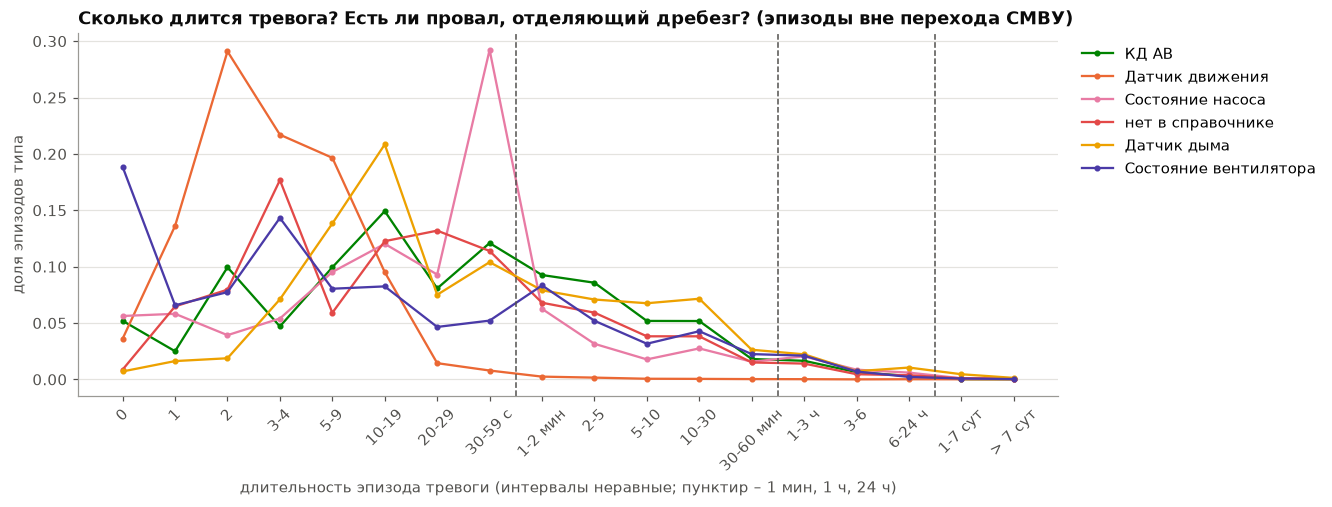

In [69]:
# Гистограмма длительности эпизода с целочисленными бинами: 0 с – отдельный бин, дальше интервалы с шагом ~×2-3
EDGES = [0, 1, 2, 3, 5, 10, 20, 30, 60, 120, 300, 600, 1800, 3600, 3 * 3600, 6 * 3600, 86400, 7 * 86400, np.inf]
LABELS = ["0", "1", "2", "3-4", "5-9", "10-19", "20-29", "30-59 с", "1-2 мин", "2-5", "5-10", "10-30", "30-60 мин",
          "1-3 ч", "3-6", "6-24 ч", "1-7 сут", "> 7 сут"]
ep_nt = ep_nt.assign(интервал_длительности=pd.cut(ep_nt["длительность_с"], EDGES, labels=LABELS, right=False))
top_alarm_types = [t for t in ep_tab.index if t in TYPE_COLOR][:6]
fig, ax = plt.subplots()
for t in top_alarm_types:
    sh = (ep_nt.loc[ep_nt["тип_датчика"] == t, "интервал_длительности"].value_counts(normalize=True)
          .reindex(LABELS))
    ax.plot(range(len(LABELS)), sh.values, color=TYPE_COLOR[t], marker="o", ms=3, label=t)
    print(f"{t}: мода – интервал «{sh.idxmax()}» ({sh.max():.0%} эпизодов)")
for lbl in ["1-2 мин", "1-3 ч", "1-7 сут"]:
    ax.axvline(LABELS.index(lbl) - 0.5, color=INK2, ls="--", lw=1)
ax.set_xticks(range(len(LABELS)), LABELS, rotation=45)
ax.set_xlabel("длительность эпизода тревоги (интервалы неравные; пунктир – 1 мин, 1 ч, 24 ч)")
ax.set_ylabel("доля эпизодов типа")
ax.set_title("Сколько длится тревога? Есть ли провал, отделяющий дребезг? (эпизоды вне перехода СМВУ)")
legend_right(ax)
plt.show()

Мы надеялись увидеть на гистограмме провал между короткими «дребезговыми» эпизодами и настоящими тревогами –
он дал бы естественный порог. **Провала нет:** распределение убывает после моды, а мода зависит от типа (напечатана
над графиком): у движения 2 с (29 % эпизодов), у насоса 30-59 с (29 %, цикл откачки), у дыма и «КД АВ» 10-19 с
(21 и 15 %), у вентилятора 0 с (19 %). Эпизодов короче 60 с 79,5 % в целом: 99,4 % у движения, 92,3 % у газа, 80,8 % у насоса,
67,4 % у «КД АВ», 63,8 % у дыма. Порог дребезга 60 с поэтому прагматичный, а не естественный; в этапе 2 стоит
проверить чувствительность к 30 и 120 с.

Длинные и открытые эпизоды редки: открытых вне перехода 213 (0,018 %), длиннее 24 ч – 0,4 %. Исключения видны
в таблице по парам ниже. Что следует за тревогой и какие состояния начинают эпизоды?

In [70]:
# Что следует за тревожной записью (следующая запись канала)
(runs.filter(F.col("тревожное")).groupBy("состояние", "следующее_состояние").count()
     .orderBy(F.desc("count")).limit(20).toPandas())

,состояние,следующее_состояние,count
0,Неисправен,Норма,1244795
1,Не замкнут,Норма,394626
2,Обнаружено движение,Движения нет,207062
3,Обесточен,Норма,147084
4,Неисправен,Обесточен,122900
5,Работают все насосы в АНС,Выключен,62298
6,Неисправен,Затоплен,46808
7,Обнаружен дым,Дыма нет,40130
8,Затоплен,Обесточен,34663
9,Питание от батарей,Питание от сети,21920


In [71]:
# Состояние → эпизоды (вне перехода): в скольких эпизодах встречается, в скольких первое, сколько ≥ 60 с и > 24 ч.
# «тревожных_записей» – за весь период по словарю (с переходом)
ex = ep_nt[["состояния", "первое_состояние", "длительность_с", "открыт", "тип_датчика"]].explode("состояния")
st_ep = ex.groupby("состояния").agg(эпизодов=("длительность_с", "size"),
                                    от_60с=("длительность_с", lambda s: int((s >= 60).sum())),
                                    дольше_24ч=("длительность_с", lambda s: int((s > 86400).sum())),
                                    открытых=("открыт", "sum"))
first = ep_nt.groupby("первое_состояние")["длительность_с"].agg(первое="size", первое_от_60с=lambda s: int((s >= 60).sum()))
st_ep = st_ep.join(first, how="left").fillna(0).astype(int)
st_ep["эпизодов_в_переходе"] = ep.loc[ep["период_смву"] == smvu.ПЕРЕХОД, "состояния"].explode().value_counts()
st_ep["тревожных_записей"] = vocab[vocab["тревожное"]].groupby("состояние")["количество_событий"].sum()
st_ep["типы"] = ex.groupby("состояния")["тип_датчика"].agg(lambda s: ", ".join(s.value_counts().index[:4]))
with pd.option_context("display.max_colwidth", 80):
    display(st_ep.fillna(0).sort_values("эпизодов", ascending=False))
# То же по парам (тип, первое состояние эпизода), ≥ 50 эпизодов вне перехода
st_tp = (ep_nt.groupby(["тип_датчика", "первое_состояние"])["длительность_с"]
         .agg(эпизодов="size", от_60с=lambda s: int((s >= 60).sum()), доля_дольше_24ч=lambda s: (s > 86400).mean())
         .join(ep_nt.groupby(["тип_датчика", "первое_состояние"])["открыт"].mean().rename("доля_открытых")))
with pd.option_context("display.max_rows", 200):
    display(st_tp[st_tp["эпизодов"] >= 50].sort_values("эпизодов", ascending=False).round(3))

,эпизодов,от_60с,дольше_24ч,открытых,первое,первое_от_60с,эпизодов_в_переходе,тревожных_записей,типы
состояния,,,,,,,,,
Не замкнут,391549,110092,451,19,391544,110090,6004,398181,"КД АВ, нет в справочнике, КД Дверь, Стекло"
Неисправен,388693,70277,968,58,386490,68509,1037123,1426850,"Состояние насоса, Датчик дыма, Состояние вентилятора, Газовый датчик"
Обнаружено движение,206152,901,20,0,206150,899,1125,207568,"Датчик движения, нет в справочнике, КД Дверь, Ручной извещатель"
Обесточен,161447,38102,225,1,5937,178,1211,163482,"Состояние насоса, Состояние вентилятора, нет в справочнике"
Работают все насосы в АНС,75869,13892,216,0,75474,13652,4219,91767,"Состояние насоса, нет в справочнике"
Затоплен,54205,9082,77,0,478,91,593,55436,"Состояние насоса, нет в справочнике"
Обнаружен дым,43445,27093,243,3,43420,27076,259,43826,"Датчик дыма, нет в справочнике"
Питание от батарей,21738,1506,35,1,21727,1502,693,22605,"ИБП, нет в справочнике"
Обнаружен газ,13417,2108,34,2,13416,2107,103,13521,"Газовый датчик, нет в справочнике"


,,эпизодов,от_60с,доля_дольше_24ч,доля_открытых
тип_датчика,первое_состояние,,,,
КД АВ,Не замкнут,226434,74039,0.000,0.000
Датчик движения,Обнаружено движение,201551,872,0.000,0.000
нет в справочнике,Не замкнут,108247,26874,0.000,0.000
Состояние насоса,Неисправен,96200,18950,0.000,0.000
Датчик дыма,Неисправен,87639,18565,0.003,0.001
Состояние вентилятора,Неисправен,69940,19649,0.001,0.000
Состояние насоса,Работают все насосы в АНС,67273,11882,0.003,0.000
Газовый датчик,Неисправен,43594,2130,0.004,0.000
Датчик дыма,Обнаружен дым,42203,26604,0.005,0.000


Из этих таблиц видны три важные вещи.
- **Тревоги идут цепочками.** После «Неисправен» следующей записью в 46 808 случаях идет «Затоплен»; эпизодов
  с «Затоплен» 54 205, а начинает эпизод он только в 478. Если классифицировать эпизод по первому состоянию,
  подтопление почти исчезает.
- **«Работают все насосы в АНС» – режим откачки, а не отказ**: за ним следует «Выключен» или «Включен»,
  и эпизод короткий. Логичнее считать его предвестником подтопления.
- **«Отключено устройство» и температурные состояния дают почти все длинные и «неснятые» тревоги**:
  «Состояние УИР-Р / Отключено устройство» – 24,8 % эпизодов дольше 24 ч и 14,8 % открытых, «Ручной извещатель /
  Отключено устройство» – 45,7 % дольше 24 ч, температура «Не определено» и «ниже 3ºC» – 12,8 и 13,0 %.
  «Датчик дыма / Отключено устройство» – 8,2 %. Похоже на вывод оборудования из работы, а не на отказ.

«Батарея неисправна» ни разу не была тревожной (2 691 запись у ИБП), «Неопределен» тоже не тревожен по флагу,
его разберем как потерю связи в разделе 7.

Сведем состояния в кандидаты классов инцидентов и посчитаем, сколько недребезговых эпизодов (≥ 60 с) дает каждый
класс. Класс эпизода определяем двумя способами: по первому состоянию и по приоритету состояний в цепочке
(подтопление > пожар > отказ > проникновение), чтобы подтопление не терялось внутри цепочек. Считаем только
каналы справочника: для остальных нет объекта, и метку для них не построить.

In [72]:
A_STATES = {"Неисправен", "Обесточен", "Питание от батарей", "Батарея разряжена", "Много неисправных устройств"}
E_TYPES = {"КД АВ", "КД Дверь", "КД Люк", "Стекло", "9-секционный люк"}
PRIORITY = {"C. подтопление": 0, "D. пожар": 1, "A. отказ": 2, "E. проникновение": 3, "газ": 4,
            "температурный режим": 5, "откачка (АНС)": 6, "вывод из работы": 7, "прочее": 8}


def state_class(state: pd.Series, tp: pd.Series) -> pd.Series:
    """Кандидат в класс инцидента по паре (состояние, тип датчика)."""
    nz = state.eq("Не замкнут")
    conds = [
        state.eq("Затоплен") | (nz & tp.eq("Датчик затопления")),
        state.isin(["Обнаружен дым", "Рычаг сдернут"]) | (nz & tp.isin(["Тепловой датчик", "Ручной извещатель"])),
        state.isin(A_STATES) | (state.eq("Не определено") & tp.eq("Датчик температуры")),
        state.eq("Обнаружено движение") | (nz & tp.isin(E_TYPES)),
        state.eq("Обнаружен газ"),
        state.str.startswith("Температура", na=False),
        state.eq("Работают все насосы в АНС"),
        state.eq("Отключено устройство"),
    ]
    return pd.Series(np.select(conds, list(PRIORITY)[:-1], "прочее"), index=state.index)


epk = ep_nt[ep_nt["ид_канала_данных"].isin(KNOWN_IDS)].copy()
epk["класс_по_первому"] = state_class(epk["первое_состояние"], epk["тип_датчика"])
exk = epk[["состояния", "тип_датчика"]].explode("состояния")
exk["ранг"] = state_class(exk["состояния"], exk["тип_датчика"]).map(PRIORITY)
epk["класс_по_цепочке"] = exk.groupby(level=0)["ранг"].min().map({v: k for k, v in PRIORITY.items()})
epk["от_60с"] = epk["длительность_с"] >= 60
cls_tab = pd.DataFrame({
    "эпизодов (по первому)": epk.groupby("класс_по_первому").size(),
    "от 60 с (по первому)": epk[epk["от_60с"]].groupby("класс_по_первому").size(),
    "эпизодов (по цепочке)": epk.groupby("класс_по_цепочке").size(),
    "от 60 с (по цепочке)": epk[epk["от_60с"]].groupby("класс_по_цепочке").size(),
}).reindex(list(PRIORITY)).fillna(0).astype(int)
print(f"эпизодов каналов справочника вне перехода: {len(epk):,}, из них от 60 с: {epk['от_60с'].sum():,}")
cls_tab

эпизодов каналов справочника вне перехода: 1,043,241, из них от 60 с: 208,585


,эпизодов (по первому),от 60 с (по первому),эпизодов (по цепочке),от 60 с (по цепочке)
C. подтопление,4194,158,56191,8232
D. пожар,50695,27920,50724,27938
A. отказ,417792,74630,366820,67060
E. проникновение,477884,83470,477785,83415
газ,9991,1973,9977,1961
температурный режим,8212,3331,7815,3230
откачка (АНС),67273,11882,66815,11601
вывод из работы,6817,5199,6731,5126
прочее,383,22,383,22


Что показывает таблица. Из 1 043 241 эпизода каналов справочника вне перехода 208 585 длятся 60 с и дольше. Если
брать класс по первому состоянию, подтопления почти нет: 158 недребезговых эпизодов. По приоритету в цепочке их
8 232 – в 50 раз больше, почти все за счет «Затоплен» внутри цепочек отказа; отказ при этом теряет те же эпизоды
(74 630 → 67 060). Остальные классы от способа почти не зависят: пожар ~27,9 тыс., проникновение ~83,4 тыс.,
газ ~2,0 тыс., температурный режим ~3,2-3,3 тыс., откачка ~11,6-11,9 тыс., вывод из работы ~5,1-5,2 тыс.
недребезговых эпизодов.

Повторяемость: по эпизодам вне перехода 71,4 % тревог повторяют предыдущую на том же канале в пределах 1 ч и 82,6 %
в пределах 24 ч (таблица `ep_tab`). По типам: движение 92 / 96 %, газ 89 / 90 %, дым 73 / 79 %, насос 62 / 86 %,
«КД АВ» 62 / 78 %. Повтор в течение часа – обычное поведение, поэтому ценен не сам повтор, а его отклонение от
нормы канала.

**Итог раздела 5.**
- Тревожность задается парой (тип, состояние) и меняется во времени; с ноября 2025 года смешанные состояния
  тревожны почти всегда (эпоха разметки 2025-11-01, переходная полоса 2025-10-15 … 2025-12-05).
- Длительность тревоги нужно считать по эпизодам: у 12,2 % тревожных записей следующая запись в ту же секунду.
- Естественного порога дребезга нет; 79,5 % эпизодов короче 60 с, моды зависят от типа.
- Классы инцидентов строятся из пар (тип, состояние) с приоритетом внутри цепочки; иначе подтопление теряется
  (8 232 недребезговых эпизода по цепочке против 158 по первому состоянию).
- «Отключено устройство» и температурный режим – источник почти всех длинных тревог; это вывод из работы и
  режим, а не отказ.

## 6. Ступени и провалы суммарного потока
На графиках раздела 1 у суммарного потока видны ступени и провалы, а в разделе 2 – неполные ноябрьские дни и обрыв
апреля 2024 года. Раздел 1 показал, что поток на 38-63 % состоит из газа Альфы. Гипотеза: почти все ступени –
это изменения газовой телеметрии Альфы (частота опроса, число каналов, молчание), а не события в коллекторах.
Проверяем: раскладываем поток на «газ Альфы» и «все остальное» и разбираем каждую ступень.

доля газа Альфы во всем потоке по годам: {2019: 0.106, 2020: 0.296, 2021: 0.542, 2022: 0.543, 2023: 0.378, 2024: 0.607, 2025: 0.632, 2026: 0.516}


,с,по,дней,остальное_в_сутки
0,2019-11-28,2019-12-01,4,44571
1,2020-02-15,2020-02-17,3,44488
2,2020-11-25,2020-11-30,6,47436
3,2021-07-01,2021-07-01,1,71955
4,2021-11-24,2021-12-01,8,62072
5,2022-11-22,2022-11-22,1,46729
6,2023-11-09,2023-11-15,7,47872
7,2024-04-09,2024-04-10,2,14407
8,2024-11-09,2024-11-12,4,44096
9,2025-11-07,2025-11-09,3,51584


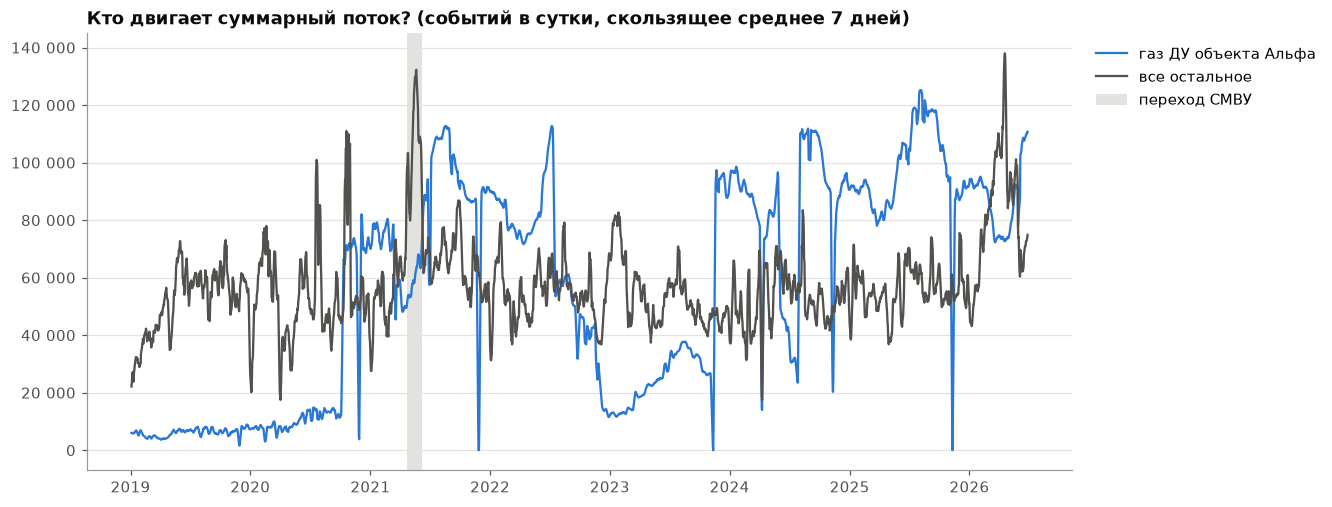

In [73]:
alpha_day = pd.DataFrame({
    "газ_Альфы": daily_ch[is_alpha_gas].groupby("день")["количество_событий"].sum(),
    "каналов_газа_Альфы": daily_ch[is_alpha_gas].groupby("день")["ид_канала_данных"].nunique(),
    "остальное": daily_ch[~is_alpha_gas].groupby("день")["количество_событий"].sum(),
}).reindex(pd.date_range(DATA_START, DATA_END), fill_value=0).fillna(0)
alpha_day["на_канал"] = (alpha_day["газ_Альфы"] / alpha_day["каналов_газа_Альфы"].replace(0, np.nan)).round(0)
print("доля газа Альфы во всем потоке по годам:",
      (alpha_day["газ_Альфы"].groupby(alpha_day.index.year).sum()
       / alpha_day[["газ_Альфы", "остальное"]].sum(axis=1).groupby(alpha_day.index.year).sum()).round(3).to_dict())

# Серии дней, когда газ Альфы молчит полностью, а остальная система пишет
silent = alpha_day["газ_Альфы"].eq(0) & alpha_day["остальное"].gt(0)
grp = (silent != silent.shift()).cumsum()
display(alpha_day[silent].groupby(grp[silent]).apply(
    lambda g: pd.Series({"с": g.index.min().date(), "по": g.index.max().date(), "дней": len(g),
                         "остальное_в_сутки": int(g["остальное"].mean())})).reset_index(drop=True))

fig, ax = plt.subplots()
wk = alpha_day[["газ_Альфы", "остальное"]].rolling(7, center=True).mean()
ax.plot(wk.index, wk["газ_Альфы"], color=PALETTE[0], label="газ ДУ объекта Альфа")
ax.plot(wk.index, wk["остальное"], color=INK2, label="все остальное")
shade_transition(ax)
thousands(ax)
ax.set_title("Кто двигает суммарный поток? (событий в сутки, скользящее среднее 7 дней)")
legend_right(ax)
plt.show()

Газ Альфы дает 10,6 % всех событий 2019 года, 29,6 % – 2020-го, 54,2 % – 2021-го, 54,3 % – 2022-го, 37,8 % – 2023-го, 60,7 % – 2024-го, 63,2 % –
2025-го. На графике «все остальное» идет ровно, с недельным ритмом, а ступени и провалы – у газа Альфы. Газ Альфы
полностью замолкает на несколько суток почти каждый ноябрь, пока остальная система пишет (таблица серий выше:
2019-11-28 … 12-01, 2020-11-25 … 11-30, 2021-11-24 … 12-01, 2022-11-22, 2023-11-09 … 11-15, 2024-11-09 … 11-12,
2025-11-07 … 11-13 с одним днем записи 10.11). Кроме ноября есть 2020-02-15 … 02-17 (3 дня, причину мы не нашли),
2021-07-01 (послепереходное возмущение, раздел 3.4) и 2024-04-09/10 (общий обрыв).

Чтобы не выбирать ступени на глаз, найдем их автоматически: для каждого дня сравним медиану числа газовых каналов
Альфы и событий на канал за 14 суток до и 14 суток после (дни полного молчания исключены). Ступенью считаем
изменение числа каналов на 10 и больше или изменение темпа на канал вдвое и больше.

In [74]:
a = alpha_day[alpha_day["газ_Альфы"] > 0]
k = 14
before = a[["каналов_газа_Альфы", "на_канал"]].rolling(k, min_periods=7).median().shift(1)
after = a[["каналов_газа_Альфы", "на_канал"]][::-1].rolling(k, min_periods=7).median()[::-1]
cp = pd.DataFrame({"каналов_до": before["каналов_газа_Альфы"], "каналов_после": after["каналов_газа_Альфы"],
                   "на_канал_до": before["на_канал"], "на_канал_после": after["на_канал"]}).dropna()
cp["изменение_каналов"] = cp["каналов_после"] - cp["каналов_до"]
cp["отношение_на_канал"] = cp["на_канал_после"] / cp["на_канал_до"]
cp["сила"] = np.maximum(cp["изменение_каналов"].abs() / 10, np.abs(np.log2(cp["отношение_на_канал"])))
hits = cp[cp["сила"] >= 1]
# Соседние дни (ближе 14 суток) – одна ступень; в ней берем день с наибольшей силой
hit_grp = (hits.index.to_series().diff() > pd.Timedelta(days=14)).cumsum()
change_points = hits.groupby(hit_grp.values).apply(lambda g: g.loc[g["сила"].idxmax()])
change_points.index = hits.groupby(hit_grp.values)["сила"].idxmax().values
change_points.round(2)

,каналов_до,каналов_после,на_канал_до,на_канал_после,изменение_каналов,отношение_на_канал,сила
2019-05-02,24.0,36.5,184.5,182.5,12.5,0.99,1.25
2019-10-23,34.0,23.0,221.5,244.5,-11.0,1.10,1.10
2020-05-29,32.0,42.5,290.0,289.0,10.5,1.00,1.05
2020-10-04,40.5,50.0,292.0,1198.0,9.5,4.10,2.04
2022-07-10,54.0,26.0,2005.0,2055.5,-28.0,1.03,2.80
2022-11-30,25.0,24.0,1521.5,608.5,-1.0,0.40,1.32
2023-11-03,26.0,55.0,1018.5,1285.5,29.0,1.26,2.90
2024-07-31,53.0,53.0,478.0,2085.5,0.0,4.36,2.13


Автоматический поиск нашел 8 ступеней. Пять совпадают с тем, что видно на графике: 2020-10 (темп на канал ×4,10),
2022-07 (−28 каналов), 2022-11-30 (темп ×0,40), 2023-11 (+29 каналов) и 2024-07-31 (темп ×4,36 – возврат после
медленного опроса лета 2024 года; само замедление шло постепенно и порог не прошло). Даты сдвинуты на несколько
дней, потому что медианы берутся по 14 суткам, а дни молчания выброшены. Еще три ступени в 2019-2020 годах – это
колебания числа пишущих каналов на 10-12 (в те годы число газовых каналов Альфы за сутки прыгало от 24 до 55,
см. таблицы зон ниже), на поток они почти не влияют.

По дневному ряду газа Альфы и найденным ступеням выделяем зоны для разбора. Для каждой сравниваем с окном той же
длины сразу перед зоной (для возврата каналов в 2023 году – перед ноябрьским молчанием).

In [75]:
ZONES = {  # (начало, конец включительно[, конец окна сравнения])
    "2020-10-08: опрос газа Альфы учащается": ("2020-10-08", "2020-10-21"),
    "2020-11: газ Альфы молчит": ("2020-11-25", "2020-11-30"),
    "2021-11: газ Альфы молчит": ("2021-11-24", "2021-12-01"),
    "2022-07-15: у Альфы уходят газовые каналы": ("2022-07-15", "2022-07-28"),
    "2023-11: газ Альфы молчит": ("2023-11-09", "2023-11-15"),
    "2023-11-16: газовые каналы Альфы вернулись": ("2023-11-16", "2023-11-29", "2023-11-09"),
    "2024-04: общий обрыв данных": ("2024-04-06", "2024-04-09"),
    "2024-06…07: опрос газа Альфы реже": ("2024-06-01", "2024-07-15"),
    "2024-11: газ Альфы молчит": ("2024-11-09", "2024-11-12"),
    "2025-11: газ Альфы молчит": ("2025-11-07", "2025-11-13"),
}


def zone_windows(zone):
    s, e = pd.Timestamp(zone[0]), pd.Timestamp(zone[1]) + pd.Timedelta(days=1)
    ref_end = pd.Timestamp(zone[2]) if len(zone) > 2 else s
    return s, e, ref_end - (e - s), ref_end


for name, z in ZONES.items():
    s, e, rs, re_ = zone_windows(z)
    print(f"{name}: окно сравнения {rs:%Y-%m-%d}…{re_ - pd.Timedelta(days=1):%Y-%m-%d}")
    display(alpha_day.loc[rs:e + pd.Timedelta(days=2)].T)
print("конец зоны 2024-06…07 (возврат частоты опроса):")
display(alpha_day.loc["2024-07-25":"2024-08-04"].T)
print("газ Альфы на канал в сутки, медиана по месяцам 2022-07 … 2023-03 (после ухода каналов):")
alpha_day["на_канал"].resample("MS").median().loc["2022-06-01":"2023-03-01"]

2020-10-08: опрос газа Альфы учащается: окно сравнения 2020-09-24…2020-10-07


,2020-09-24,2020-09-25,2020-09-26,2020-09-27,2020-09-28,2020-09-29,2020-09-30,2020-10-01,2020-10-02,2020-10-03,2020-10-04,2020-10-05,2020-10-06,2020-10-07,2020-10-08,2020-10-09,2020-10-10,2020-10-11,2020-10-12,2020-10-13,2020-10-14,2020-10-15,2020-10-16,2020-10-17,2020-10-18,2020-10-19,2020-10-20,2020-10-21,2020-10-22,2020-10-23,2020-10-24
газ_Альфы,13674.0,13213.0,12611.0,12416.0,11370.0,10402.0,10109.0,10448.0,11656.0,13069.0,13268.0,13006.0,12976.0,12752.0,45011.0,71392.0,73551.0,67441.0,64730.0,62733.0,60512.0,65098.0,63076.0,67615.0,72463.0,70980.0,73761.0,76232.0,67352.0,70890.0,63806.0
каналов_газа_Альфы,55.0,43.0,35.0,34.0,41.0,32.0,24.0,41.0,55.0,33.0,34.0,34.0,47.0,39.0,49.0,51.0,48.0,50.0,52.0,52.0,53.0,53.0,53.0,50.0,48.0,55.0,49.0,50.0,50.0,54.0,51.0
остальное,60132.0,57244.0,20432.0,15909.0,59089.0,55418.0,60531.0,58198.0,50878.0,18408.0,22469.0,50632.0,54862.0,53755.0,58897.0,52652.0,25677.0,26371.0,55523.0,65383.0,57801.0,89229.0,90548.0,167866.0,108482.0,78755.0,65342.0,133747.0,89653.0,133063.0,54248.0
на_канал,249.0,307.0,360.0,365.0,277.0,325.0,421.0,255.0,212.0,396.0,390.0,383.0,276.0,327.0,919.0,1400.0,1532.0,1349.0,1245.0,1206.0,1142.0,1228.0,1190.0,1352.0,1510.0,1291.0,1505.0,1525.0,1347.0,1313.0,1251.0


2020-11: газ Альфы молчит: окно сравнения 2020-11-19…2020-11-24


,2020-11-19,2020-11-20,2020-11-21,2020-11-22,2020-11-23,2020-11-24,2020-11-25,2020-11-26,2020-11-27,2020-11-28,2020-11-29,2020-11-30,2020-12-01,2020-12-02,2020-12-03
газ_Альфы,68398.0,74641.0,68572.0,66703.0,65352.0,32875.0,0.0,0.0,0.0,0.0,0.0,0.0,26717.0,71011.0,87977.0
каналов_газа_Альфы,49.0,48.0,46.0,45.0,44.0,55.0,0.0,0.0,0.0,0.0,0.0,0.0,27.0,51.0,51.0
остальное,67650.0,58560.0,33555.0,26849.0,57425.0,65721.0,62963.0,61240.0,50921.0,28174.0,26053.0,55268.0,56558.0,65851.0,70098.0
на_канал,1396.0,1555.0,1491.0,1482.0,1485.0,598.0,NaN,NaN,NaN,NaN,NaN,NaN,990.0,1392.0,1725.0


2021-11: газ Альфы молчит: окно сравнения 2021-11-16…2021-11-23


,2021-11-16,2021-11-17,2021-11-18,2021-11-19,2021-11-20,2021-11-21,2021-11-22,2021-11-23,2021-11-24,2021-11-25,2021-11-26,2021-11-27,2021-11-28,2021-11-29,2021-11-30,2021-12-01,2021-12-02,2021-12-03,2021-12-04
газ_Альфы,87360.0,88516.0,88404.0,88608.0,87045.0,84148.0,86202.0,42985.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,56483.0,89049.0,87708.0
каналов_газа_Альфы,53.0,53.0,54.0,52.0,52.0,53.0,53.0,55.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,55.0,53.0,53.0
остальное,71197.0,69754.0,66449.0,74093.0,42444.0,47444.0,85654.0,82755.0,72729.0,70121.0,71663.0,41065.0,37590.0,66886.0,70194.0,66328.0,77450.0,56913.0,32554.0
на_канал,1648.0,1670.0,1637.0,1704.0,1674.0,1588.0,1626.0,782.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1027.0,1680.0,1655.0


... (14 outputs left out)

конец зоны 2024-06…07 (возврат частоты опроса):


,2024-07-25,2024-07-26,2024-07-27,2024-07-28,2024-07-29,2024-07-30,2024-07-31,2024-08-01,2024-08-02,2024-08-03,2024-08-04
газ_Альфы,23121.0,23940.0,23090.0,21705.0,22065.0,24958.0,112587.0,111508.0,110442.0,110435.0,111373.0
каналов_газа_Альфы,53.0,53.0,53.0,53.0,53.0,53.0,53.0,53.0,53.0,53.0,53.0
остальное,60562.0,57547.0,49000.0,40332.0,65643.0,60302.0,70844.0,62250.0,58942.0,33695.0,32274.0
на_канал,436.0,452.0,436.0,410.0,416.0,471.0,2124.0,2104.0,2084.0,2084.0,2101.0


газ Альфы на канал в сутки, медиана по месяцам 2022-07 … 2023-03 (после ухода каналов):


2022-06-01    1790.0
2022-07-01    2083.0
2022-08-01    2319.0
2022-09-01    1923.0
2022-10-01    1747.0
2022-11-01    1616.0
2022-12-01     576.0
2023-01-01     496.0
2023-02-01     516.0
2023-03-01     647.0
Freq: MS, Name: на_канал, dtype: float64

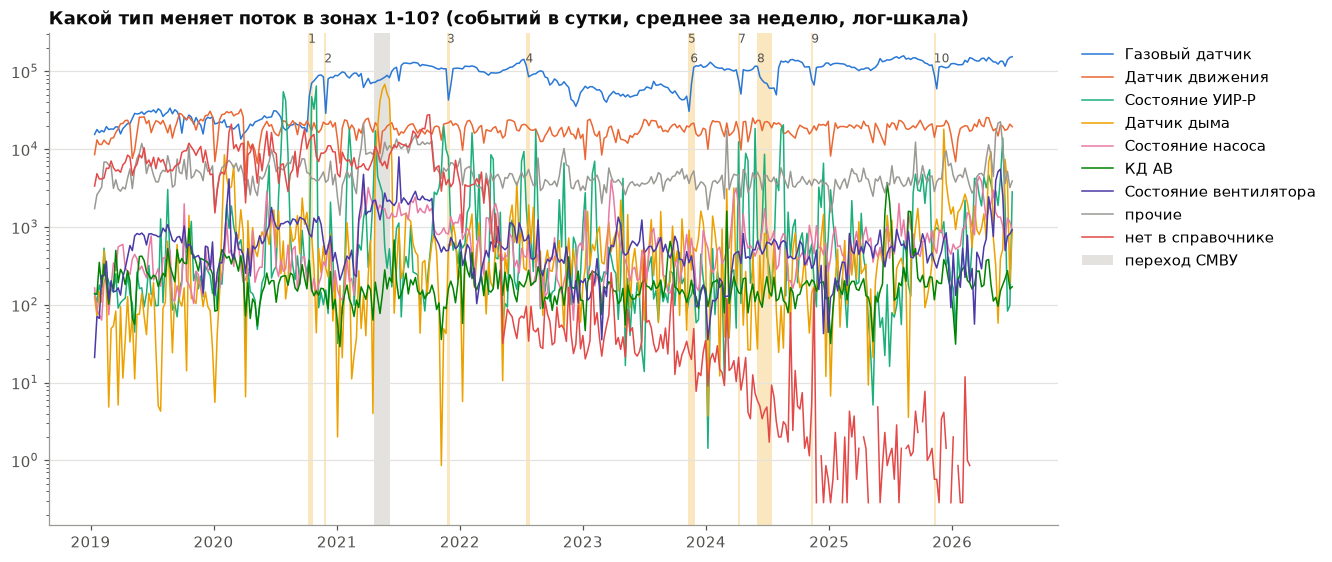

{1: '2020-10-08: опрос газа Альфы учащается', 2: '2020-11: газ Альфы молчит', 3: '2021-11: газ Альфы молчит', 4: '2022-07-15: у Альфы уходят газовые каналы', 5: '2023-11: газ Альфы молчит', 6: '2023-11-16: газовые каналы Альфы вернулись', 7: '2024-04: общий обрыв данных', 8: '2024-06…07: опрос газа Альфы реже', 9: '2024-11: газ Альфы молчит', 10: '2025-11: газ Альфы молчит'}


In [76]:
# Недельные суммы / 7: дневные ряды дискретных типов слишком шумные
daily_type = fold_types(daily_ch.groupby(["день", "тип_датчика"])["количество_событий"].sum().unstack(fill_value=0))
weekly_type = daily_type.resample("W").sum().iloc[1:-1] / 7
fig, ax = plt.subplots(figsize=(12, 5))
plot_lines(ax, weekly_type.replace(0, np.nan), lw=1)
ax.set_yscale("log")
for i, z in enumerate(ZONES.values()):
    s, e, _, _ = zone_windows(z)
    ax.axvspan(s, e, color=PALETTE[3], alpha=0.25, lw=0)
    ax.annotate(str(i + 1), (mdates.date2num(s), 1 - 0.04 * (i % 2)), xycoords=("data", "axes fraction"),
                fontsize=8, color=INK2, va="top")
shade_transition(ax)
ax.set_title("Какой тип меняет поток в зонах 1-10? (событий в сутки, среднее за неделю, лог-шкала)")
legend_right(ax)
plt.show()
print({i + 1: name for i, name in enumerate(ZONES)})

In [77]:
# Флаппинг УИР-Р: события УИР-Р в сутки по объектам осенью 2020 и перед обрывом апреля 2024
uir = daily_ch[daily_ch["тип_датчика"] == "Состояние УИР-Р"]
for lo_, hi_ in [("2020-09-01", "2020-12-01"), ("2024-03-25", "2024-04-06")]:
    u = window(uir, lo_, hi_)
    top = u.groupby("ид_объект")["количество_событий"].sum().nlargest(3)
    print(f"{lo_}…{hi_}: событий УИР-Р {u['количество_событий'].sum():,}; топ объектов:",
          {obj_names.get(o): int(v) for o, v in top.items()})
    tau = u[u["ид_объект"] == top.index[0]].groupby("день")["количество_событий"].sum()
    tau = tau[tau > 1000]
    print(f"  у лидера дни > 1 000 событий: {tau.index.min():%Y-%m-%d}…{tau.index.max():%Y-%m-%d}, "
          f"{tau.sum():,} событий, пик {tau.max():,} ({tau.idxmax():%Y-%m-%d})")
print("«Неопределен» у УИР-Р по годам:",
      vocab[(vocab["тип_датчика"] == "Состояние УИР-Р") & (vocab["состояние"] == "Неопределен")]
      .groupby("год")["количество_событий"].sum().to_dict())

2020-09-01…2020-12-01: событий УИР-Р 1,034,702; топ объектов: {'ПС объект Тау': 1016598, 'объект Дельта': 4081, 'объект Кси ПК0-ПК202': 2909}
  у лидера дни > 1 000 событий: 2020-09-19…2020-10-30, 1,009,543 событий, пик 237,508 (2020-10-29)
2024-03-25…2024-04-06: событий УИР-Р 87,406; топ объектов: {'ПС объект Тау': 86033, 'объект Дельта': 691, 'объект Кси ПК0-ПК202': 222}
  у лидера дни > 1 000 событий: 2024-04-01…2024-04-04, 85,931 событий, пик 50,856 (2024-04-03)
«Неопределен» у УИР-Р по годам: {2019: 39653, 2020: 980109, 2021: 415595, 2022: 324643, 2023: 73661, 2024: 448403, 2025: 143901, 2026: 217027}


In [78]:
# Активный канал за сутки – писал что-то, кроме «Неопределен» (иначе пачка «Неопределен» завышает число активных)
daily_ch["активен"] = daily_ch["количество_событий"] > daily_ch["количество_неопределен"]


def zone_breakdown(zone):
    """Окно сравнения той же длины против зоны: активных каналов в сутки (среднее) и событий в сутки по типам."""
    s, e, rs, re_ = zone_windows(zone)
    days = (e - s).days

    def f(x):
        return pd.DataFrame({"каналов": x[x["активен"]].groupby(["тип_датчика", "день"])["ид_канала_данных"].nunique()
                                         .groupby(level=0).sum() / days,
                             "событий_в_сутки": x.groupby("тип_датчика")["количество_событий"].sum() / days})

    out = f(window(daily_ch, rs, re_)).join(f(window(daily_ch, s, e)), how="outer",
                                            lsuffix="_до", rsuffix="_в_зоне").fillna(0)
    out["отношение_событий"] = out["событий_в_сутки_в_зоне"] / out["событий_в_сутки_до"].replace(0, np.nan)
    return out.sort_values("событий_в_сутки_до", ascending=False).round(2)


for name, z in ZONES.items():
    print(name)
    display(zone_breakdown(z))

2020-10-08: опрос газа Альфы учащается


,каналов_до,событий_в_сутки_до,каналов_в_зоне,событий_в_сутки_в_зоне,отношение_событий
тип_датчика,,,,,
Датчик движения,150.93,21961.57,137.57,18570.50,0.85
Газовый датчик,69.29,17748.79,92.50,71999.50,4.06
нет в справочнике,277.43,9526.57,269.07,16603.86,1.74
КД Дверь,147.71,2472.79,146.36,1915.29,0.77
Переключатель,305.36,1572.50,289.71,956.71,0.61
Состояние фазы,202.07,1070.93,172.50,621.43,0.58
Датчик дыма,329.36,1063.07,290.36,899.14,0.85
Состояние вентилятора,214.93,1028.93,207.07,827.64,0.80
Датчик температуры,135.71,493.57,160.43,602.86,1.22


2020-11: газ Альфы молчит


,каналов_до,событий_в_сутки_до,каналов_в_зоне,событий_в_сутки_в_зоне,отношение_событий
тип_датчика,,,,,
Газовый датчик,102.00,79001.83,51.00,14217.83,0.18
Датчик движения,126.83,20284.33,95.17,20140.67,0.99
нет в справочнике,261.17,9465.17,232.00,8286.17,0.88
КД Дверь,132.17,2099.17,103.17,1782.33,0.85
Переключатель,248.33,956.50,196.33,728.50,0.76
Состояние фазы,197.17,577.33,165.67,471.67,0.82
Состояние вентилятора,155.50,569.83,118.17,450.17,0.79
Датчик температуры,128.00,460.67,83.00,283.00,0.61
Состояние насоса,23.83,303.83,29.33,417.83,1.38


2021-11: газ Альфы молчит


,каналов_до,событий_в_сутки_до,каналов_в_зоне,событий_в_сутки_в_зоне,отношение_событий
тип_датчика,,,,,
Газовый датчик,144.75,103784.38,107.38,23494.12,0.23
Датчик движения,133.00,24094.00,132.62,21210.50,0.88
Состояние УИР-Р,98.75,9859.12,103.38,5355.62,0.54
нет в справочнике,126.88,3740.12,121.25,4150.50,1.11
КД Дверь,143.62,2168.25,141.88,2229.38,1.03
Состояние фазы,170.38,1817.75,160.25,1951.00,1.07
Переключатель,139.62,1171.25,132.75,1226.00,1.05
Состояние насоса,28.62,831.38,33.00,1029.50,1.24
Датчик дыма,126.62,537.88,109.25,314.88,0.59


... (10 outputs left out)

2024-11: газ Альфы молчит


,каналов_до,событий_в_сутки_до,каналов_в_зоне,событий_в_сутки_в_зоне,отношение_событий
тип_датчика,,,,,
Газовый датчик,196.25,96630.25,138.50,23707.00,0.25
Датчик движения,175.50,26234.00,119.00,15815.00,0.60
КД Дверь,218.25,2576.50,136.00,1672.75,0.65
Состояние фазы,272.25,876.25,156.50,552.00,0.63
Состояние насоса,44.00,832.50,32.50,504.75,0.61
Состояние УИР-Р,32.50,697.50,20.75,211.75,0.30
Датчик температуры,163.25,680.75,131.00,483.25,0.71
Переключатель,219.75,511.50,157.00,333.75,0.65
Состояние вентилятора,113.50,433.50,96.75,261.00,0.60


2025-11: газ Альфы молчит


,каналов_до,событий_в_сутки_до,каналов_в_зоне,событий_в_сутки_в_зоне,отношение_событий
тип_датчика,,,,,
Газовый датчик,188.86,124781.00,146.29,31210.71,0.25
Датчик движения,122.71,16630.86,153.71,20280.86,1.22
КД Дверь,140.57,1558.29,181.14,1950.00,1.25
Состояние УИР-Р,63.00,839.00,101.86,1047.57,1.25
Состояние насоса,42.00,719.00,27.43,459.71,0.64
Датчик дыма,273.57,607.00,598.14,1583.57,2.61
Датчик температуры,157.14,607.00,152.86,573.29,0.94
Состояние фазы,163.43,575.14,184.86,582.29,1.01
Переключатель,207.86,476.57,200.00,479.71,1.01


In [79]:
def objects_lost(zone, drop=0.5, min_channels=5, burst_days=2):
    """(объект, тип), у которых среднее число активных каналов в сутки в зоне упало больше чем на `drop` против окна
    сравнения той же длины. Для каждого – пачки «Неопределен» в ±burst_days от начала и конца зоны."""
    s, e, rs, re_ = zone_windows(zone)
    days = (e - s).days

    def active_per_day(df):
        df = df[(df["ид_объект"] >= 0) & df["активен"]]
        return df.groupby(["ид_объект", "тип_датчика", "день"])["ид_канала_данных"].nunique() \
            .groupby(level=["ид_объект", "тип_датчика"]).sum() / days

    res = pd.DataFrame({"активных_до": active_per_day(window(daily_ch, rs, re_)),
                        "активных_в_зоне": active_per_day(window(daily_ch, s, e))}).fillna(0)
    res = res[res["активных_до"] >= min_channels]
    res["падение"] = 1 - res["активных_в_зоне"] / res["активных_до"]
    lost = res[res["падение"] > drop].reset_index()

    pad = pd.Timedelta(days=burst_days)
    near = bursts[bursts["минута"].between(s - pad, s + pad) | bursts["минута"].between(e - pad, e + pad)]
    b = near.groupby("ид_объект").agg(пачек_у_границ=("каналов_в_неопределен", "size"),
                                      макс_каналов_в_неопределен=("каналов_в_неопределен", "max"))
    lost = lost.join(b, on="ид_объект").fillna({"пачек_у_границ": 0, "макс_каналов_в_неопределен": 0})
    lost.insert(1, "объект", lost["ид_объект"].map(obj_names))
    return lost.sort_values("падение", ascending=False).round(2)


for name, z in ZONES.items():
    print(name)
    display(objects_lost(z))

2020-10-08: опрос газа Альфы учащается


,ид_объект,объект,тип_датчика,активных_до,активных_в_зоне,падение,пачек_у_границ,макс_каналов_в_неопределен
1,3902,ДП объект Эпсилон,Состояние УИР-Р,12.29,0.00,1.00,2.0,33.0
2,3902,ДП объект Эпсилон,Состояние насоса,6.07,0.93,0.85,2.0,33.0
4,5129,объект Фита,Датчик движения,11.43,3.57,0.69,7.0,10.0
5,5129,объект Фита,КД Дверь,5.43,1.86,0.66,7.0,10.0
0,20,объект Фита,Датчик движения,6.07,2.86,0.53,1.0,9.0
6,5132,ДП объект Зита,Состояние фазы,6.29,3.07,0.51,0.0,0.0
3,5113,объект Дельта,Датчик движения,26.00,12.71,0.51,3.0,249.0


2020-11: газ Альфы молчит


,ид_объект,объект,тип_датчика,активных_до,активных_в_зоне,падение,пачек_у_границ,макс_каналов_в_неопределен
21,5132,ДП объект Зита,Состояние фазы,5.00,0.00,1.00,0.0,0.0
18,5122,ДУ объект Альфа,Газовый датчик,47.83,0.00,1.00,4.0,4.0
7,3356,ПС объект Тау,Тепловой датчик,56.17,0.17,1.00,9.0,89.0
6,3356,ПС объект Тау,КД Дверь,28.33,0.17,0.99,9.0,89.0
3,3356,ПС объект Тау,Датчик дыма,16.00,0.17,0.99,9.0,89.0
19,5129,объект Фита,Датчик движения,5.67,0.17,0.97,8.0,3.0
1,20,объект Фита,Состояние УИР-Р,5.50,0.17,0.97,7.0,9.0
2,3356,ПС объект Тау,Датчик движения,21.33,1.00,0.95,9.0,89.0
20,5132,ДП объект Зита,Переключатель,5.50,0.33,0.94,0.0,0.0
5,3356,ПС объект Тау,КД АВ,10.17,1.33,0.87,9.0,89.0


2021-11: газ Альфы молчит


,ид_объект,объект,тип_датчика,активных_до,активных_в_зоне,падение,пачек_у_границ,макс_каналов_в_неопределен
7,5122,ДУ объект Альфа,Газовый датчик,53.12,0.00,1.00,0.0,0.0
4,4370,объект Ро,Датчик дыма,7.00,0.12,0.98,79.0,10.0
3,3215,объект Йота,Датчик движения,8.38,0.62,0.93,0.0,0.0
1,28,объект Вита,КД АВ,6.25,0.75,0.88,36.0,1.0
2,28,объект Вита,КД Дверь,10.62,2.38,0.78,36.0,1.0
0,28,объект Вита,Датчик движения,17.00,4.00,0.76,36.0,1.0
5,4370,объект Ро,Состояние УИР-Р,6.00,1.50,0.75,79.0,10.0
6,5003,ДУ ПС объект Омега,Переключатель,9.50,4.50,0.53,94.0,13.0
8,5332,объект Кси ПК0-ПК202,Датчик температуры,6.62,3.25,0.51,43.0,431.0


... (10 outputs left out)

2024-11: газ Альфы молчит


,ид_объект,объект,тип_датчика,активных_до,активных_в_зоне,падение,пачек_у_границ,макс_каналов_в_неопределен
14,4391,объект Омикрон,КД АВ,6.75,0.00,1.00,21.0,9.0
9,3360,ДУ объект Омикрон,Переключатель,5.00,0.00,1.00,0.0,0.0
27,5581,объект Дзета ПС,Датчик дыма,60.00,0.00,1.00,4.0,238.0
20,5129,объект Фита,Датчик движения,5.50,0.00,1.00,3.0,71.0
19,5122,ДУ объект Альфа,Газовый датчик,54.25,0.00,1.00,0.0,0.0
15,4391,объект Омикрон,КД Дверь,11.00,0.00,1.00,21.0,9.0
12,4391,объект Омикрон,Датчик движения,19.75,0.00,1.00,21.0,9.0
10,3360,ДУ объект Омикрон,Состояние фазы,12.50,0.00,1.00,0.0,0.0
28,5581,объект Дзета ПС,Состояние УИР-Р,9.75,0.00,1.00,4.0,238.0
4,28,объект Вита,Состояние УИР-Р,5.25,0.00,1.00,43.0,9.0


2025-11: газ Альфы молчит


,ид_объект,объект,тип_датчика,активных_до,активных_в_зоне,падение,пачек_у_границ,макс_каналов_в_неопределен
3,3356,ПС объект Тау,Тепловой датчик,18.00,0.00,1.00,2548.0,9.0
5,4648,ПС объект Омега,Датчик дыма,5.71,0.00,1.00,4.0,124.0
6,4648,ПС объект Омега,Тепловой датчик,6.57,0.00,1.00,4.0,124.0
11,5122,ДУ объект Альфа,Газовый датчик,54.29,0.14,1.00,2.0,55.0
8,5003,ДУ ПС объект Омега,Состояние вентилятора,9.86,1.00,0.90,99.0,220.0
9,5003,ДУ ПС объект Омега,Состояние насоса,8.29,1.43,0.83,99.0,220.0
7,5003,ДУ ПС объект Омега,Переключатель,26.29,6.86,0.74,99.0,220.0
4,4370,объект Ро,КД Дверь,7.14,2.29,0.68,0.0,0.0
1,3356,ПС объект Тау,Датчик движения,7.57,2.86,0.62,2548.0,9.0
13,5578,объект Дзета ДУ,Состояние вентилятора,6.29,2.43,0.61,0.0,0.0


Разбор по зонам (сравнение с окном той же длины перед зоной):

| Зона | Что произошло | Интерпретация |
|---|---|---|
| 2020-10-08 | газ Альфы 12 752 (07.10) → 45 011 (08.10) → 71 392 (09.10) событий в сутки при тех же ~50 каналах, на канал ~210-420 → ~1 140-1 530 в сутки; газ по всем объектам ×4,06. Одновременно флаппинг УИР-Р на «ПС объект Тау»: 1 009 543 события за 2020-09-19 … 10-30, пик 237 508 за 2020-10-29 | учащение опроса газа Альфы в ~4,5 раза (та же ступень, что в разделе 4); тревоги не растут |
| 2020-11, 2021-11, 2023-11, 2024-11, 2025-11 | газ Альфы 0 от 4 до 8 суток подряд, остальные каналы пишут как обычно (газ по всем объектам ×0,18 и ×0,23 в ноябрьских окнах 2020 и 2021 годов) | «ноябрьское окно» молчания газа Альфы |
| 2022-07-15 | у Альфы перестали писать 28 из 54 газовых каналов, газ Альфы ~110 тыс. → ~53 тыс. в сутки при том же темпе на канал (~2 050); с декабря 2022 по февраль 2023 опрос оставшихся реже: 1 616-2 319 → 496-576 событий на канал в сутки | ушла половина газовых каналов Альфы на 16 месяцев; каналы молчат ровно, без пачек «Неопределен» |
| 2023-11-16 | после 7 суток молчания каналов 26 → 55, газ ~26-27 тыс. → ~93-100 тыс. в сутки | возврат 29 газовых каналов Альфы |
| 2024-04-06 … 04-10 | 75 часов подряд без единого события по всей системе; события всех типов в зоне ×0,00-0,04 к окну до. За 2-5 дней до обрыва – флаппинг УИР-Р «ПС объект Тау»: 85 931 событие за 04-01 … 04-04, пик 50 856 за 04-03 | общий обрыв сбора данных, а не работы на объекте |
| 2024-06-01 … 07-30 | опрос газа Альфы реже (на канал ~1 370-1 570 в сутки в апреле-мае → ~820-850 в конце июня → ~410-470 в конце июля) при тех же 53-54 каналах, 2024-07-31 – возврат к 2 124 на канал (112 587 событий) | смена частоты опроса |

В таблице `objects_lost` в ноябрьских окнах есть «ДУ объект Альфа / Газовый датчик» с падением 1,00; уход 28
каналов 2022-07-15 порог 0,5 не проходит (в среднем ~28 активных газовых каналов против 54), его видно только по
дневному ряду. В ноябре 2020 года почти полностью замолкает «ПС объект Тау» (тепловые 56 → 0,2, КД Дверь 28 → 0,2,
движение 21 → 1 активных каналов в сутки) – сразу после двух месяцев флаппинга УИР-Р на этом объекте. В апреле
2024 года выпадают все объекты сразу.

**Ноябрьское окно.** Газ Альфы замолкает на 4-8 суток каждый ноябрь (2019, 2020, 2021, 2023, 2024, 2025; в 2022
году – на сутки), а остальные каналы пишут в обычном режиме. Годовая регулярность и то, что затронут только газ
одного объекта, похожи на плановую поверку или ТО газоанализаторов. Это гипотеза: подтвердить ее может график
ТО. Неполные ноябрьские дни из раздела 2.1 (2020-11-28/29, 2021-11-28, 2024-11-09/10) – такие окна, совпавшие
с выходными, когда остальной поток и так вдвое ниже.

Остался еще один вопрос к потоку: доля тревожных событий в отдельные часы доходит почти до половины. Это рост
тревог или падение знаменателя?

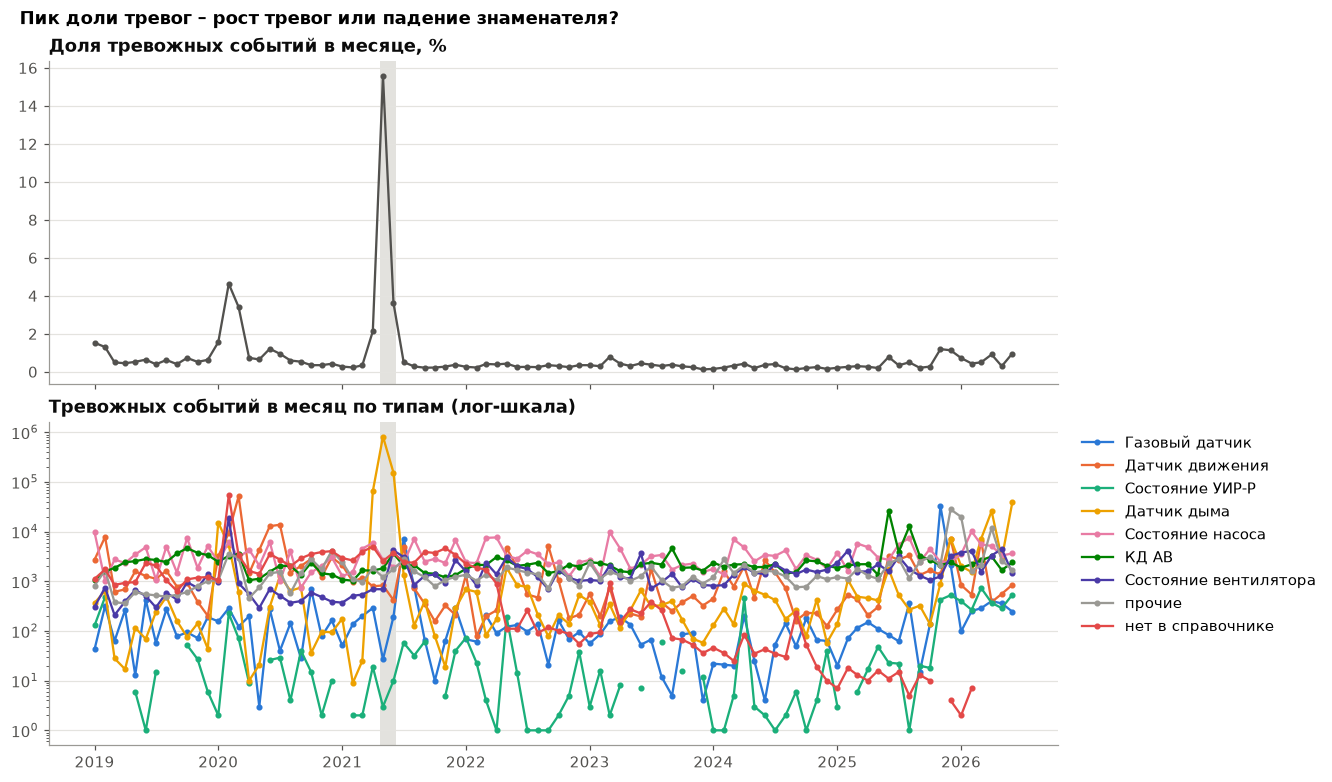

максимум месячной доли тревог: 2021-05, 15.6%


,количество_событий,количество_тревожных,доля_тревог,Газовый датчик,Датчик движения,Состояние УИР-Р,Датчик дыма,Состояние насоса,КД АВ,Состояние вентилятора,прочие,нет в справочнике
час,,,,,,,,,,,,
2024-01-01,4506731,6788,0.0015,22,449,1,130,1767,2360,813,1200,46
2024-02-01,4002633,8858,0.0022,21,1596,1,282,1378,1964,835,2745,36
2024-03-01,3988028,12940,0.0032,20,784,5,136,6981,2172,1358,1459,25
2024-04-01,3457044,14694,0.0043,201,2011,452,894,4802,2210,1928,2112,84
2024-05-01,4438132,8605,0.0019,25,464,3,651,2516,1924,1487,1500,35
2024-06-01,3178183,11604,0.0037,4,2642,2,535,3397,1945,1388,1648,43
2024-07-01,2760953,11215,0.0041,53,1508,1,420,3237,2203,2204,1554,35


In [80]:
# Доля тревог по месяцам рядом с абсолютными тревогами по типам (две панели, одна шкала на панель)
m_tot = hourly.groupby(month_start(hourly["час"]))[["количество_событий", "количество_тревожных"]].sum()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(m_tot.index, m_tot["количество_тревожных"] / m_tot["количество_событий"] * 100, color=INK2, marker="o", ms=3)
axes[0].set_title("Доля тревожных событий в месяце, %")
plot_lines(axes[1], alarms_m.replace(0, np.nan), marker="o", ms=3)
axes[1].set_yscale("log")
axes[1].set_title("Тревожных событий в месяц по типам (лог-шкала)")
legend_right(axes[1])
for ax in axes:
    shade_transition(ax)
fig.suptitle("Пик доли тревог – рост тревог или падение знаменателя?", x=0.01, ha="left", fontweight="bold")
plt.show()
m_share = m_tot["количество_тревожных"] / m_tot["количество_событий"]
print(f"максимум месячной доли тревог: {m_share.idxmax():%Y-%m}, {m_share.max():.1%}")
m24 = m_tot.loc["2024-01-01":"2024-07-01"].assign(доля_тревог=lambda d: (d["количество_тревожных"] / d["количество_событий"]).round(4))
m24.join(alarms_m.loc["2024-01-01":"2024-07-01"])

In [81]:
# Почасовая и суточная доля тревог вокруг обрыва апреля 2024; часы с долей ≥ 40 % за все годы
h_tot["доля"] = (h_tot["количество_тревожных"] / h_tot["количество_событий"].replace(0, np.nan)).round(3)
d_tot = (h_tot[["количество_событий", "количество_тревожных"]].resample("D").sum()
         .assign(доля=lambda d: (d["количество_тревожных"] / d["количество_событий"].replace(0, np.nan)).round(4)))
display(d_tot.loc["2024-03-28":"2024-04-12"].T)
display(h_tot.loc["2024-04-09":"2024-04-09 23:00"].loc[lambda x: x["количество_событий"] > 0].T)
print("часы с долей тревог ≥ 40 % и потоком ≥ 100 событий за все годы:")
h_tot[(h_tot["доля"] >= 0.4) & (h_tot["количество_событий"] >= 100)]

,2024-03-28,2024-03-29,2024-03-30,2024-03-31,2024-04-01,2024-04-02,2024-04-03,2024-04-04,2024-04-05,2024-04-06,2024-04-07,2024-04-08,2024-04-09,2024-04-10,2024-04-11,2024-04-12
количество_событий,166540.0000,134890.0000,120271.0000,115994.0000,156023.0000,146433.0000,196781.000,156015.0000,138738.0000,4412.0000,0.0,0.0,799.0000,28015.0000,61773.0000,125545.0000
количество_тревожных,562.0000,613.0000,433.0000,565.0000,693.0000,642.0000,597.000,518.0000,1202.0000,3.0000,0.0,0.0,105.0000,584.0000,510.0000,183.0000
доля,0.0034,0.0045,0.0036,0.0049,0.0044,0.0044,0.003,0.0033,0.0087,0.0007,NaN,NaN,0.1314,0.0208,0.0083,0.0015


,2024-04-09 05:00:00,2024-04-09 07:00:00,2024-04-09 08:00:00,2024-04-09 10:00:00,2024-04-09 11:00:00,2024-04-09 12:00:00,2024-04-09 13:00:00,2024-04-09 14:00:00,2024-04-09 15:00:00,2024-04-09 16:00:00,2024-04-09 17:00:00,2024-04-09 18:00:00,2024-04-09 19:00:00,2024-04-09 20:00:00,2024-04-09 21:00:00,2024-04-09 22:00:00,2024-04-09 23:00:00
количество_событий,1.0,13.0,62.0,35.0,130.000,56.000,28.0,82.000,21.0,44.0,5.0,1.0,7.0,102.0,31.000,3.000,178.000
количество_тревожных,0.0,0.0,0.0,0.0,5.000,9.000,0.0,4.000,0.0,0.0,0.0,0.0,0.0,51.0,15.000,1.000,20.000
доля,0.0,0.0,0.0,0.0,0.038,0.161,0.0,0.049,0.0,0.0,0.0,0.0,0.0,0.5,0.484,0.333,0.112


часы с долей тревог ≥ 40 % и потоком ≥ 100 событий за все годы:


,количество_событий,количество_тревожных,доля
2019-01-04 03:00:00,4389,1817,0.414
2019-01-05 06:00:00,10123,4584,0.453
2024-04-09 20:00:00,102,51,0.500
2025-11-06 11:00:00,42571,19135,0.449


**Почти половина – только в отдельные часы и от падения знаменателя.** 2024-04-09 20:00 – 51 тревога из 102 событий:
система только начинает писать после обрыва. За сутки 2024-04-09 – 105 из 799 (13,1 %), за апрель – 14 694 из
3 457 044 (0,43 %; в январе-марте 0,15-0,32 %). Абсолютное число тревог 2024-04-09 (105) ниже обычного дня (433-1 202
за 03-28 … 04-05). На уровне месяца картина смешанная: событий на 13,3 % меньше, чем в марте, а тревог на 13,6 %
больше – рост дали движение (2 011 против 784 в марте), дым (894 против 136), вентиляторы (1 928 против 1 358),
УИР-Р (452 против 5, флаппинг Тау) и газ (201 против 20). Часов с долей тревог ≥ 40 % при потоке ≥ 100 событий
за все годы всего 4: 2019-01-04 03:00, 2019-01-05 06:00, 2024-04-09 20:00 и 2025-11-06 11:00. Последний – не
знаменатель, а всплеск газовых тревог Альфы. На месячном графике главный пик доли – май 2021 (15,6 %, переход СМВУ).

In [82]:
# Всплеск газовых тревог Альфы (раздел 5): по часам и состояниям, доля в годовых тревогах газа
st_day = (events.filter((F.to_date("дата_время") == F.lit(STORM_DAY.date())) & F.col("ид_канала_данных").isin(alpha_gas_ids))
          .groupBy(F.hour("дата_время").alias("час_суток"), "состояние", "тревожное").count().toPandas())
display(st_day.pivot_table(index="час_суток", columns=["состояние", "тревожное"], values="count", aggfunc="sum",
                           fill_value=0).loc[lambda x: x.sum(axis=1) > 100])
gas_alarm_y = daily_ch[daily_ch["тип_датчика"] == GAS].groupby("год")["количество_тревожных"].sum()
alpha_alarm_y = daily_ch[is_alpha_gas].groupby("год")["количество_тревожных"].sum()
storm = st_day.loc[st_day["тревожное"], "count"].sum()
print(f"тревог газа Альфы {STORM_DAY:%Y-%m-%d}: {storm:,}; тревог газа за 2025: {gas_alarm_y[2025]:,} "
      f"({storm / gas_alarm_y[2025]:.1%}); тревог газа Альфы за 2025: {alpha_alarm_y[2025]:,} "
      f"({storm / alpha_alarm_y[2025]:.1%})")
pd.DataFrame({"тревог газа": gas_alarm_y, "из них газ Альфы": alpha_alarm_y}).T

состояние,Неисправен,Неопределен,Норма
тревожное,True,False,False
час_суток,,,
9,1218,0,1204
10,11678,0,11646
11,19116,56,19108


тревог газа Альфы 2025-11-06: 32,012; тревог газа за 2025: 35,864 (89.3%); тревог газа Альфы за 2025: 32,787 (97.6%)


год,2019,2020,2021,2022,2023,2024,2025,2026
тревог газа,1892,2180,9224,1264,940,845,35864,1640
из них газ Альфы,159,834,8188,104,57,133,32787,103


2025-11-06 с 09:00 до 11:59 на газовых каналах Альфы – 32 012 тревог за 3 часа (1 218, 11 678 и 19 116 по
часам), и все они – флаппинг «Неисправен ↔ Норма», а не «Обнаружен газ». На следующий день началось ноябрьское
окно молчания. Это 89,3 % всех тревог газа 2025 года (35 864) и 97,6 % тревог газа Альфы за год (32 787).
Всплеск «газовых тревог 2025 года» из раздела 1 – одно сервисное событие, а не рост загазованности. В обычные
годы у Альфы 57-834 тревоги газа в год. Исключение – 2021 год с 8 188; вероятно, это в основном всплеск 2021-07-02
(7 007 тревог газа за сутки, раздел 3.4), но по объектам мы его здесь не раскладывали.

**Итог раздела 6.** Гипотеза подтверждается: ступени суммарного потока – почти все изменения газовой телеметрии
одного объекта (частота опроса 2020-10-08, декабрь 2022 – февраль 2023, июнь-июль 2024; число каналов 2022-07-15
−28 и 2023-11-16 +29; ежегодное ноябрьское молчание). Инцидентов на суммарном графике не видно. Исключения –
общий обрыв данных 2024-04-06 … 04-10, флаппинг УИР-Р на «ПС объект Тау» (осень 2020, перед обрывом 2024 года)
и всплеск 2025-11-06. Без газа Альфы поток ровный, с недельным ритмом (в выходные примерно вдвое меньше событий).
Долю тревог без минимального знаменателя использовать нельзя.

## 7. Потеря связи: пачки «Неопределен»
Состояние «Неопределен» не тревожно по флагу, но это главный кандидат в признак потери связи: когда отваливается
контроллер, все его каналы одновременно становятся «Неопределен». Вопросы: сколько каналов объекта одновременно
уходят в «Неопределен» и есть ли естественный порог; как долго длится такая пачка; у каких объектов; связаны ли
пачки со ступенями раздела 6. Рабочая гипотеза, с которой начинаем: пачка – это 10 и больше каналов объекта в одну
минуту.

минут всего: 668,645; объект −1 (вне справочника): 17.5%; в переходе СМВУ: 2.9%


count    535156.000000
mean          8.824147
std          26.996524
min           1.000000
50%           1.000000
90%          22.000000
95%          43.000000
99%          92.000000
99.9%       378.000000
max         993.000000
Name: каналов_в_неопределен, dtype: float64

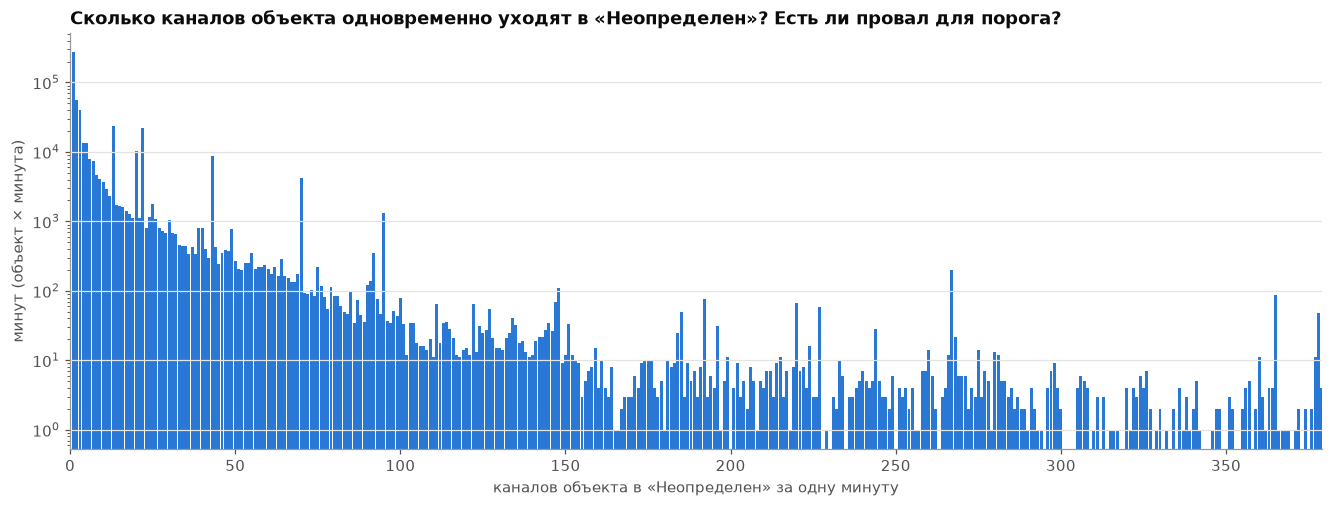

In [83]:
# Минуты «объект × минута» с хотя бы одним каналом в «Неопределен». Каналы вне справочника (объект −1) и переход
# СМВУ показываем долей и исключаем из статистики: у первых нет объекта, второй – аномальный период
n_ch = channels_pd.groupby("ид_объект")["ид_канала_данных"].nunique()
bursts["каналов_у_объекта"] = bursts["ид_объект"].map(n_ch)
bursts["доля_каналов"] = bursts["каналов_в_неопределен"] / bursts["каналов_у_объекта"]
bursts["период_смву"] = smvu.period_of(bursts["минута"]).values
print(f"минут всего: {len(bursts):,}; объект −1 (вне справочника): {(bursts['ид_объект'] < 0).mean():.1%}; "
      f"в переходе СМВУ: {(bursts['период_смву'] == smvu.ПЕРЕХОД).mean():.1%}")
bk = bursts[(bursts["ид_объект"] >= 0) & (bursts["период_смву"] != smvu.ПЕРЕХОД)]
display(bk["каналов_в_неопределен"].describe(percentiles=[.5, .9, .95, .99, .999]))
vc = bk["каналов_в_неопределен"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(vc.index, vc.values, width=0.9, color=PALETTE[0])
ax.set_yscale("log")
ax.set_xlim(0, bk["каналов_в_неопределен"].quantile(0.999) + 1)
ax.set_xlabel("каналов объекта в «Неопределен» за одну минуту")
ax.set_ylabel("минут (объект × минута)")
ax.set_title("Сколько каналов объекта одновременно уходят в «Неопределен»? Есть ли провал для порога?")
plt.show()

In [84]:
# Пики гистограммы (≥ 10 каналов, больше соседей): чей это модуль – объект с наибольшим числом таких минут
vc_all = (bk["каналов_в_неопределен"].value_counts().sort_index()
          .reindex(range(1, bk["каналов_в_неопределен"].max() + 1), fill_value=0))
peaks = vc_all[(vc_all > vc_all.shift(1)) & (vc_all > vc_all.shift(-1)) & (vc_all.index >= 10)].nlargest(8)
rows = []
for n, cnt in peaks.items():
    top = bk.loc[bk["каналов_в_неопределен"] == n, "ид_объект"].value_counts()
    rows.append({"каналов": n, "минут": cnt, "объект": obj_names.get(top.index[0]), "минут_объекта": top.iloc[0],
                 "доля_объекта": round(top.iloc[0] / cnt, 3), "каналов_у_объекта": n_ch.get(top.index[0])})
display(pd.DataFrame(rows))
display(bk["доля_каналов"].describe(percentiles=[.5, .9, .95, .99]).round(3))
print("объектов:", len(n_ch), "| каналов на объект, медиана:", n_ch.median(), "| < 10 каналов:", (n_ch < 10).sum(),
      "| < 20 каналов:", (n_ch < 20).sum())

,каналов,минут,объект,минут_объекта,доля_объекта,каналов_у_объекта
0,13,23887,ДУ ПС объект Омега,21984,0.920,233
1,22,22391,ДП объект Сигма,21534,0.962,41
2,20,10174,ДП объект Бета,8043,0.791,106
3,43,8866,ДП объект Зита,8568,0.966,53
4,70,4170,ДП объект Бета,4001,0.959,106
5,25,1753,ПС объект Тау,699,0.399,919
6,95,1304,ДУ объект Альфа,1245,0.955,164
7,30,1063,ПС объект Тау,572,0.538,919


count    535156.000
mean          0.077
std           0.181
min           0.001
50%           0.004
90%           0.236
95%           0.537
99%           0.811
max           1.000
Name: доля_каналов, dtype: float64

объектов: 78 | каналов на объект, медиана: 66.0 | < 10 каналов: 12 | < 20 каналов: 25


Всего 668 645 минут «объект × минута» с хотя бы одним каналом в «Неопределен»; 17,5 % из них – каналы вне
справочника без объекта, 2,9 % – переход СМВУ, их исключаем. На оставшихся 535 156 минутах медиана – 1 канал,
p90 – 22, p95 – 43, p99 – 92, максимум – 993.

**Естественного порога нет.** Число минут монотонно падает от 1 до ~12 каналов, выше – не провал, а отдельные пики.
Каждый пик – одна и та же группа каналов одного объекта, уходящая целиком: 13 каналов у «ДУ ПС объект Омега» (92 %
таких минут), 22 – у «ДП объект Сигма» (96 %), 20 и 70 – у «ДП объект Бета», 43 – у «ДП объект Зита», 95 – у Альфы.
Похоже, пики – это размеры контроллеров или шлейфов: «Неопределен» пачкой = отвалился модуль целиком.

**Абсолютный порог 10 несправедлив к малым объектам:** медианный объект – 66 каналов, но у 12 объектов из 78 меньше
10 каналов, у 25 – меньше 20. С порогом 10 они никогда не дадут положительного примера.

Теперь длительность. Склеиваем минуты одного объекта с разрывом ≤ 5 мин в эпизоды; длительность эпизода – от первой
до последней минуты плюс медианная длительность «Неопределен» в самой долгой минуте.

In [85]:
K = 10
und_min = (V["state_runs"].filter(F.col("состояние") == "Неопределен")
           .join(F.broadcast(channels.select("ид_канала_данных", "ид_объект")), "ид_канала_данных")
           .groupBy("ид_объект", F.date_trunc("minute", "дата_время").alias("минута"))
           .agg(F.countDistinct("ид_канала_данных").alias("каналов"),
                F.percentile_approx("секунд_до_следующего", 0.5).alias("медиана_длительности_с"))
           .toPandas())
und_min["минута"] = pd.to_datetime(und_min["минута"])
und_min = und_min[(smvu.period_of(und_min["минута"]) != smvu.ПЕРЕХОД).values]


def to_episodes(df, gap_min=5):
    df = df.sort_values(["ид_объект", "минута"])
    new = (df["ид_объект"] != df["ид_объект"].shift()) | (df["минута"].diff() > pd.Timedelta(minutes=gap_min))
    ep_b = df.assign(эпизод=new.cumsum()).groupby("эпизод").agg(
        ид_объект=("ид_объект", "first"), начало=("минута", "min"), конец=("минута", "max"),
        пик=("каналов", "max"), медиана_длительности_с=("медиана_длительности_с", "max"))
    ep_b["длительность_мин"] = ((ep_b["конец"] - ep_b["начало"]).dt.total_seconds() / 60
                                + ep_b["медиана_длительности_с"] / 60)
    return ep_b


ep_k = to_episodes(und_min[und_min["каналов"] >= K])
print(f"эпизодов при ≥ {K} каналах: {len(ep_k):,}; длительность, мин:")
display(ep_k["длительность_мин"].describe(percentiles=[.5, .75, .9, .99]).round(1))
by_obj = ep_k.groupby([ep_k["начало"].dt.year, "ид_объект"]).size().unstack(0, fill_value=0)
by_obj.index = by_obj.index.map(lambda o: obj_names.get(o, UNKNOWN))
print(f"эпизодов пачек (≥ {K} каналов) по объектам и годам:")
by_obj.loc[by_obj.sum(axis=1).sort_values(ascending=False).index].head(20)

эпизодов при ≥ 10 каналах: 77,232; длительность, мин:


count     77232.0
mean         33.8
std        1452.6
min           0.0
50%           0.1
75%           0.4
90%           5.1
99%         114.1
max      287847.4
Name: длительность_мин, dtype: float64

эпизодов пачек (≥ 10 каналов) по объектам и годам:


начало,2019,2020,2021,2022,2023,2024,2025,2026
ид_объект,,,,,,,,
ДУ ПС объект Омега,160,113,2843,3968,3979,4127,4048,2223
ДП объект Сигма,220,444,15369,1971,259,21,29,8
ДП объект Бета,279,303,7999,26,11,18,47,4257
ДП объект Зита,270,298,7990,7,8,3,34,14
ПС объект Тау,171,854,2404,1322,64,442,237,514
ДУ объект Альфа,145,418,914,130,75,50,51,20
объект Кси ПК0-ПК202,0,295,68,39,73,38,97,22
объект Хи,255,328,12,6,3,0,3,10
ДП объект Эпсилон,56,53,64,44,241,31,59,34


In [86]:
# Что следует за «Неопределен» и через сколько секунд (следующая запись канала)
und = runs.filter(F.col("состояние") == "Неопределен")
display(und.agg(F.count("*").alias("записей"),
                F.percentile_approx("секунд_до_следующего", [0.25, 0.5, 0.75, 0.95]).alias("квартили_с"),
                F.avg(F.col("время_следующего").isNull().cast("int")).alias("доля_открытых")).toPandas())
und.groupBy("следующее_состояние").count().orderBy(F.desc("count")).limit(10).toPandas()

,записей,квартили_с,доля_открытых
0,7497595,"[3, 9, 25, 668]",0.00003


,следующее_состояние,count
0,Норма,6948426
1,Неопределен,505256
2,Много неисправных устройств,8796
3,Неисправен,8549
4,Выключен,8449
5,Не замкнут,5022
6,Обнаружено движение,2579
7,Включен,1942
8,Обнаружен дым,1834
9,Отключено устройство,1765


**Большинство пачек – секундные «моргания».** «Неопределен» длится 3 / 9 / 25 с (квартили времени до следующей
записи), p95 – 668 с. В 92,7 % случаев следующая запись – «Норма» (6 948 426 из 7 497 595), в 6,7 % – снова
«Неопределен» (505 256; повторы не схлопнуты, так что длительность потери связи тут занижена). Эпизодов при ≥ 10
каналах – 77 232, длительность: медиана 0,1 мин, p75 0,4, p90 5,1, p99 114,1 мин. Частота по объектам сильно
перекошена: «ДУ ПС объект Омега» (~4 000 эпизодов в год в 2022-2025), «ДП объект Сигма» (15 369 в 2021), «ДП объект
Бета» (7 999 в 2021, 4 257 в первом полугодии 2026), «ПС объект Тау» (854 в 2020, 2 404 в 2021). Это хронические
объекты.

Отсюда два исправления правила пачки: порог по каналам сделать зависящим от размера объекта и отсечь секундные
моргания фильтром длительности. Сравниваем варианты.

In [87]:
# Правило пачки: абсолютный порог 10 против адаптивного min(10, ⌈0,5 · каналов объекта⌉) и фильтр длительности
K_obj = np.minimum(K, np.ceil(0.5 * und_min["ид_объект"].map(n_ch)))
rules = {"≥ 10 каналов": und_min["каналов"] >= K, "≥ min(10, ⌈0,5·N⌉)": und_min["каналов"] >= K_obj}
rows = []
for rule, m in rules.items():
    ep_r = to_episodes(und_min[m])
    for min_dur in (0, 10, 60):
        e = ep_r[ep_r["длительность_мин"] >= min_dur]
        od = e.assign(d=e["начало"].dt.floor("D")).drop_duplicates(["ид_объект", "d"])
        top3 = od["ид_объект"].value_counts().head(3).sum() / max(len(od), 1)
        rows.append({"правило": rule, "мин. длительность, мин": min_dur, "эпизодов": len(e),
                     "объектов": e["ид_объект"].nunique(), "объекто-суток": len(od), "доля топ-3": round(top3, 3),
                     **od["d"].dt.year.value_counts().sort_index().rename(lambda y: f"о-с {y}").to_dict()})
b_rules = pd.DataFrame(rows).fillna(0)
b_rules

,правило,"мин. длительность, мин",эпизодов,объектов,объекто-суток,доля топ-3,о-с 2019,о-с 2020,о-с 2021,о-с 2022,о-с 2023,о-с 2024,о-с 2025,о-с 2026
0,≥ 10 каналов,0,77232,65,9123,0.359,1334,1914,1517,958,880,751,1043,726
1,≥ 10 каналов,10,4271,64,2129,0.275,356,491,311,203,176,161,256,175
2,≥ 10 каналов,60,1280,63,925,0.298,144,262,94,83,66,72,114,90
3,"≥ min(10, ⌈0,5·N⌉)",0,79356,78,10349,0.317,1511,2107,1614,1117,1068,869,1240,823
4,"≥ min(10, ⌈0,5·N⌉)",10,4708,77,2483,0.236,402,555,325,240,244,199,313,205
5,"≥ min(10, ⌈0,5·N⌉)",60,1426,76,1063,0.260,161,292,100,88,90,92,128,112


Адаптивный порог с фильтром 10 минут дает 4 708 эпизодов на 77 объектах и 2 483 объекто-суток вне перехода:
2019 – 402, 2020 – 555, 2021 – 325, 2022 – 240, 2023 – 244, 2024 – 199, 2025 – 313, 2026 (полугодие) – 205. Доля
трех главных объектов падает с 35,9 % до 23,6 %. На сетке «объект × сутки» (78 × 365 = 28 470 объекто-суток в год)
это ~0,7-1,1 % положительных в 2022-2025 годах. При фильтре 60 мин остается 1 063 объекто-суток, 88-292 в год.

Последний вопрос – связаны ли пачки со ступенями потока из раздела 6.

In [88]:
# Эпизоды пачек (≥ 10 каналов) внутри зон раздела 6 против среднего по году (эпизодов в сутки)
ep_day = ep_k.groupby(ep_k["начало"].dt.floor("D")).size()
zone_rows = []
for name, z in ZONES.items():
    s, e, _, _ = zone_windows(z)
    in_zone = ep_day[(ep_day.index >= s) & (ep_day.index < e)].sum() / (e - s).days
    year_rate = ep_day[ep_day.index.year == s.year].sum() / (366 if s.year % 4 == 0 else 365)
    zone_rows.append({"зона": name, "эпизодов_в_сутки_в_зоне": in_zone, "эпизодов_в_сутки_за_год": year_rate})
pd.DataFrame(zone_rows).round(2)

,зона,эпизодов_в_сутки_в_зоне,эпизодов_в_сутки_за_год
0,2020-10-08: опрос газа Альфы учащается,23.93,12.37
1,2020-11: газ Альфы молчит,4.67,12.37
2,2021-11: газ Альфы молчит,104.88,105.18
3,2022-07-15: у Альфы уходят газовые каналы,16.71,22.29
4,2023-11: газ Альфы молчит,14.29,14.56
5,2023-11-16: газовые каналы Альфы вернулись,13.00,14.56
6,2024-04: общий обрыв данных,0.00,14.01
7,2024-06…07: опрос газа Альфы реже,13.29,14.01
8,2024-11: газ Альфы молчит,14.25,14.01
9,2025-11: газ Альфы молчит,14.00,14.67


Связь слабая. Пачек заметно больше среднего только в зоне 2020-10-08 (23,93 эпизода в сутки против 12,37 за год,
×1,9) – это время флаппинга УИР-Р на «ПС объект Тау» (980 109 записей «Неопределен» у УИР-Р в 2020 году). В апреле
2024 года такой же флаппинг Тау шел за 2-5 дней до общего обрыва: возможный предвестник, но случай один. В
остальных зонах пачек столько же, сколько в среднем за год, или меньше. Важное наблюдение: **молчание газа Альфы
(ноябрьские окна, 2022-07-15) не сопровождается «Неопределен»** – каналы телеметрии просто перестают писать. Значит,
у потери связи два механизма: пачки «Неопределен» и молчание телеметрии (раздел 4).

**Итог раздела 7.**
- Пачки «Неопределен» – это модули контроллеров конкретных объектов (13, 20, 22, 43, 70, 95 каналов);
  естественного порога по числу каналов нет.
- Рабочее правило потери связи: в минуту ≥ min(10, ⌈0,5 · каналов объекта⌉) каналов в «Неопределен», минуты с
  разрывом ≤ 5 мин склеены, эпизод ≥ 10 мин. Это 2 483 объекто-суток вне перехода.
- Короткие пачки – не инцидент, а признак; у нескольких объектов они хронические.
- Вторая ветка потери связи – молчание телеметрии относительно ритма канала, без «Неопределен».

## 8. Сезонность и время суток
Вопросы: сезонны ли тревоги насосов и подтопления (весна, ливни); приходятся ли тревоги движения и дверей на рабочие
часы (визиты бригад); отличается ли 2021 год. Профиль типа – доля его тревог, пришедшаяся на месяц / час / день
недели. Сумма тревог за все годы легко перекашивается одиночными всплесками (раздел 1), поэтому основной профиль –
**медиана годовых профилей** 2019-2025 без 2021 года: каждый год весит одинаково, 2021-й (переход) сравнивается
отдельно, 2026-й неполный.

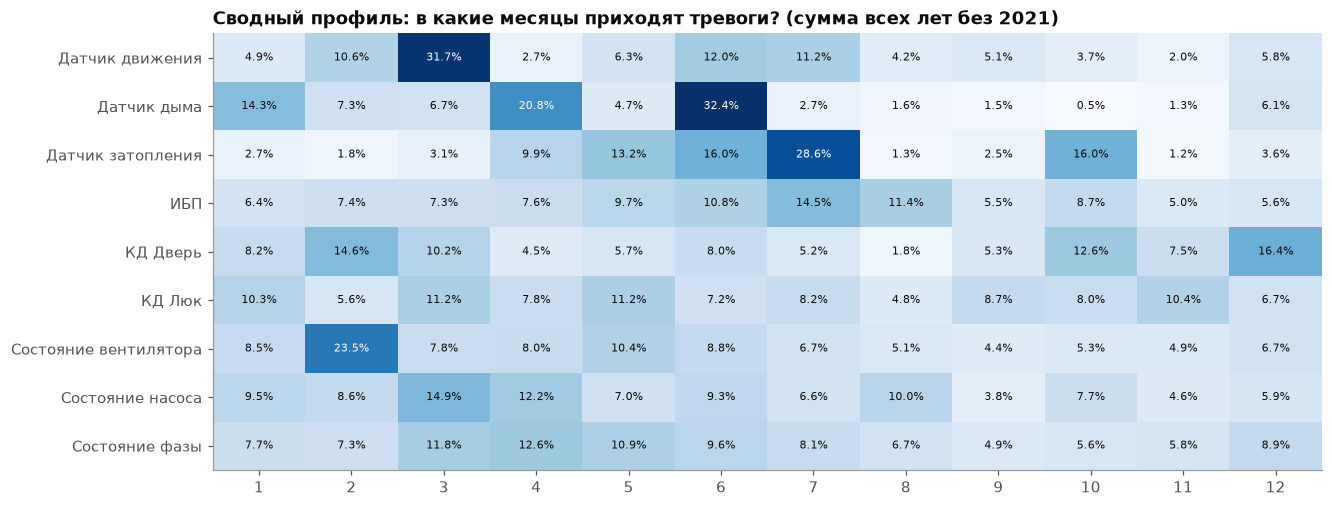

сводный профиль (сумма всех лет без 2021), % тревог типа:


месяц,1,2,3,4,5,6,7,8,9,10,11,12
тип_датчика,,,,,,,,,,,,
Датчик движения,4.9,10.6,31.7,2.7,6.3,12.0,11.2,4.2,5.1,3.7,2.0,5.8
Датчик дыма,14.3,7.3,6.7,20.8,4.7,32.4,2.7,1.6,1.5,0.5,1.3,6.1
Датчик затопления,2.7,1.8,3.1,9.9,13.2,16.0,28.6,1.3,2.5,16.0,1.2,3.6
ИБП,6.4,7.4,7.3,7.6,9.7,10.8,14.5,11.4,5.5,8.7,5.0,5.6
КД Дверь,8.2,14.6,10.2,4.5,5.7,8.0,5.2,1.8,5.3,12.6,7.5,16.4
КД Люк,10.3,5.6,11.2,7.8,11.2,7.2,8.2,4.8,8.7,8.0,10.4,6.7
Состояние вентилятора,8.5,23.5,7.8,8.0,10.4,8.8,6.7,5.1,4.4,5.3,4.9,6.7
Состояние насоса,9.5,8.6,14.9,12.2,7.0,9.3,6.6,10.0,3.8,7.7,4.6,5.9
Состояние фазы,7.7,7.3,11.8,12.6,10.9,9.6,8.1,6.7,4.9,5.6,5.8,8.9


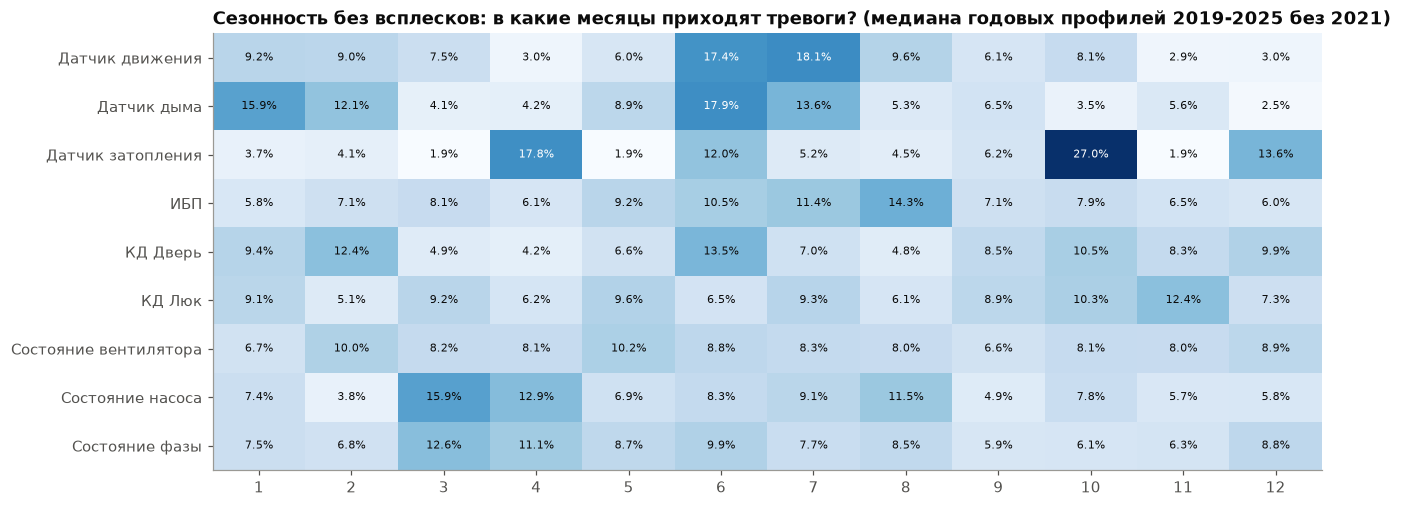

Состояние насоса


месяц,1,2,3,4,5,6,7,8,9,10,11,12
год,,,,,,,,,,,,
2019,9619,1018,2747,2332,3463,4842,1085,4988,1495,7400,1854,5065
2020,2463,6197,2985,4349,2069,6202,1011,4001,746,1513,2022,3030
2021,1275,1540,4552,5895,2721,1935,2318,7109,2492,2830,2329,6685
2022,2408,2318,7474,7635,3257,2839,4122,3482,2208,2393,1259,2407
2023,2672,1258,9724,4548,1797,2164,3177,3385,1724,2133,2261,1539
2024,1767,1378,6981,4802,2516,3397,3237,4169,1761,3352,2712,1801
2025,3729,1628,5742,4856,3000,2709,5491,7480,2445,4473,2460,2438
2026,3494,10061,5516,5153,3309,3635,0,0,0,0,0,0


Датчик движения


месяц,1,2,3,4,5,6,7,8,9,10,11,12
год,,,,,,,,,,,,
2019,2727,7804,616,686,1588,1274,1125,1624,782,932,387,202
2020,3181,9510,51443,1449,4280,12865,13744,1499,2035,2806,1228,3027
2021,2099,986,1173,792,826,419,4844,725,353,157,326,210
2022,1364,79,198,260,4600,1918,544,471,5154,1040,179,213
2023,553,200,747,144,224,195,1781,373,253,378,505,325
2024,449,1596,784,2011,464,2642,1508,727,162,232,227,126
2025,271,532,433,207,304,3233,2730,3312,1337,1651,1370,7162
2026,838,541,6617,383,558,850,0,0,0,0,0,0


Датчик дыма


месяц,1,2,3,4,5,6,7,8,9,10,11,12
год,,,,,,,,,,,,
2019,368,639,28,17,116,69,240,489,159,76,142,44
2020,15154,5302,619,10,21,306,1285,644,750,36,97,94
2021,177,9,25,64759,817932,153655,1351,128,393,79,19,287
2022,688,610,82,171,1871,832,771,211,78,209,139,527
2023,388,131,343,116,262,656,315,329,399,168,70,58
2024,130,282,136,894,651,535,420,173,261,79,429,58
2025,138,1063,489,459,412,1758,527,269,323,138,902,7253
2026,2026,1532,7160,25756,2871,38580,0,0,0,0,0,0


Состояние вентилятора


месяц,1,2,3,4,5,6,7,8,9,10,11,12
год,,,,,,,,,,,,
2019,308,748,209,392,669,506,298,588,429,958,738,1375
2020,965,18496,914,551,292,697,514,369,400,594,482,388
2021,372,511,540,692,693,4198,3074,840,1288,1372,910,2683
2022,1578,830,2373,1379,3074,1992,1769,1208,690,1671,1178,1018
2023,1062,1021,2078,1203,1130,3630,716,960,1411,751,1132,844
2024,813,835,1358,1928,1487,1388,2204,1648,1400,1720,1528,1719
2025,2372,4156,1571,1581,2208,1590,3156,1746,1298,1058,1250,3230
2026,3788,4080,1553,3292,4505,1441,0,0,0,0,0,0


In [89]:
KEY_TYPES = ["Состояние насоса", "Датчик затопления", "Датчик движения", "КД Люк", "КД Дверь",
             "Состояние фазы", "Состояние вентилятора", "ИБП", "Датчик дыма"]
h = hourly[hourly["тип_датчика"].isin(KEY_TYPES)].copy()
h["месяц"], h["час_суток"], h["день_недели"] = h["час"].dt.month, h["час"].dt.hour, h["час"].dt.dayofweek


def profile(df, by):
    t = df.groupby(["тип_датчика", by])["количество_тревожных"].sum().unstack(fill_value=0)
    return t.div(t.sum(axis=1), axis=0)


def heatmap(ax, df, title, fmt="{:.1%}"):
    im = ax.imshow(df.values, aspect="auto", cmap="Blues", interpolation="nearest")
    ax.set_xticks(range(df.shape[1]), df.columns)
    ax.set_yticks(range(df.shape[0]), df.index)
    ax.grid(False)
    vmin, vmax = np.nanmin(df.values), np.nanmax(df.values)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            v = df.values[i, j]
            dark = (v - vmin) / max(vmax - vmin, 1e-12) > 0.6
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7, color="white" if dark else INK)
    ax.set_title(title)
    return im


def profile_med(df, by):
    """Медиана годовых профилей: профиль каждого года, медиана по годам, нормировка на 1."""
    t = df.groupby(["тип_датчика", "год", by])["количество_тревожных"].sum().unstack(fill_value=0)
    t = t.div(t.sum(axis=1).replace(0, np.nan), axis=0).groupby(level="тип_датчика").median()
    return t.div(t.sum(axis=1), axis=0)


h_ex = h[h["год"] != 2021]
h_med = h[h["год"].between(2019, 2025) & (h["год"] != 2021)]
fig, ax = plt.subplots(figsize=(12, 4.5))
heatmap(ax, profile(h_ex, "месяц"), "Сводный профиль: в какие месяцы приходят тревоги? (сумма всех лет без 2021)")
plt.show()
print("сводный профиль (сумма всех лет без 2021), % тревог типа:")
display((profile(h_ex, "месяц") * 100).round(1))
fig, ax = plt.subplots(figsize=(12, 4.5))
heatmap(ax, profile_med(h_med, "месяц"),
        "Сезонность без всплесков: в какие месяцы приходят тревоги? (медиана годовых профилей 2019-2025 без 2021)")
plt.show()
# Тревоги по месяцам и годам: пики сводного профиля – один год или каждый год?
for t in ["Состояние насоса", "Датчик движения", "Датчик дыма", "Состояние вентилятора"]:
    print(t)
    display(h[h["тип_датчика"] == t].pivot_table(index="год", columns="месяц", values="количество_тревожных",
                                                 aggfunc="sum", fill_value=0))

In [90]:
# «Затоплен» по годам и месяцам (записи состояния из словаря)
display(vocab[vocab["состояние"] == "Затоплен"].groupby(["год", "тип_датчика", "тревожное"])["количество_событий"].sum()
        .unstack(fill_value=0))
(vocab[vocab["состояние"] == "Затоплен"].pivot_table(index="год", columns="месяц", values="количество_событий",
                                                     aggfunc="sum", fill_value=0))

тревожное               False  True 
год  тип_датчика                    
2019 Состояние насоса      21  12741
     нет в справочнике     14    241
2020 Состояние насоса    1845   7446
     нет в справочнике    193    293
2021 Состояние насоса    2867   7781
     нет в справочнике    154    972
2022 Состояние насоса     618   6430
     нет в справочнике      0    153
2023 Состояние насоса    1057   4775
     нет в справочнике     11    121
2024 Состояние насоса    1828   4523
2025 Состояние насоса     370   5733
2026 Состояние насоса       0   4227

месяц,1,2,3,4,5,6,7,8,9,10,11,12
год,,,,,,,,,,,,
2019,4683,111,222,235,63,1199,109,1071,380,3060,385,1499
2020,456,1126,545,1137,162,1790,142,1698,516,359,716,1130
2021,314,342,1638,1428,370,634,854,3092,629,645,535,1293
2022,378,270,1842,1002,335,472,494,1397,137,181,319,374
2023,242,115,1806,304,190,231,233,1454,190,391,713,95
2024,207,153,1552,413,364,416,106,1789,215,329,631,176
2025,456,93,1391,257,206,225,254,1510,238,530,573,370
2026,610,397,1595,352,431,842,0,0,0,0,0,0


**Насосы и подтопление сезонны.** В 2022-2024 годах пик года у насосов – март-апрель: 7 474 + 7 635 (2022),
9 724 + 4 548 (2023), 6 981 + 4 802 (2024) тревог против 1 300-4 200 в остальные месяцы. В 2025 году март второй
(5 742), первый – август (7 480). Медиана годовых профилей: март 15,9 %, апрель 12,9 %, август 11,5 %. «Затоплен»
дает два устойчивых пика с 2021 года: март – 1 391-1 842 записи в год, август – 1 397-3 092, в остальные месяцы
обычно 100-900 (выше – апрель 2021-2022, 1 002-1 428, и декабрь 2021, 1 293). Наша интерпретация: март – таяние снега, август – ливни; проверить ее можно по данным об осадках.
В 2019-2020 годах пики другие (январь 2019 – 4 683, октябрь 2019 – 3 060).

**У движения, дыма и вентиляторов сезонности нет, есть эпизоды.** Пики сводного профиля – одиночные месяцы: движение
в марте 31,7 % = март 2020 (51 443 тревоги); дым в июне 32,4 % и апреле 20,8 % = 2026 год (38 580 и 25 756),
январь 14,3 % = январь 2020 (15 154); вентилятор в феврале 23,5 % = февраль 2020 (18 496). По медиане годовых
профилей вентилятор ровный (6,6-10,2 % в месяц), у движения лето выше (июнь-июль 17,4 и 18,1 %) – возможно,
сезон работ; у ИБП тоже лето (июнь-август 10,5-14,3 %).

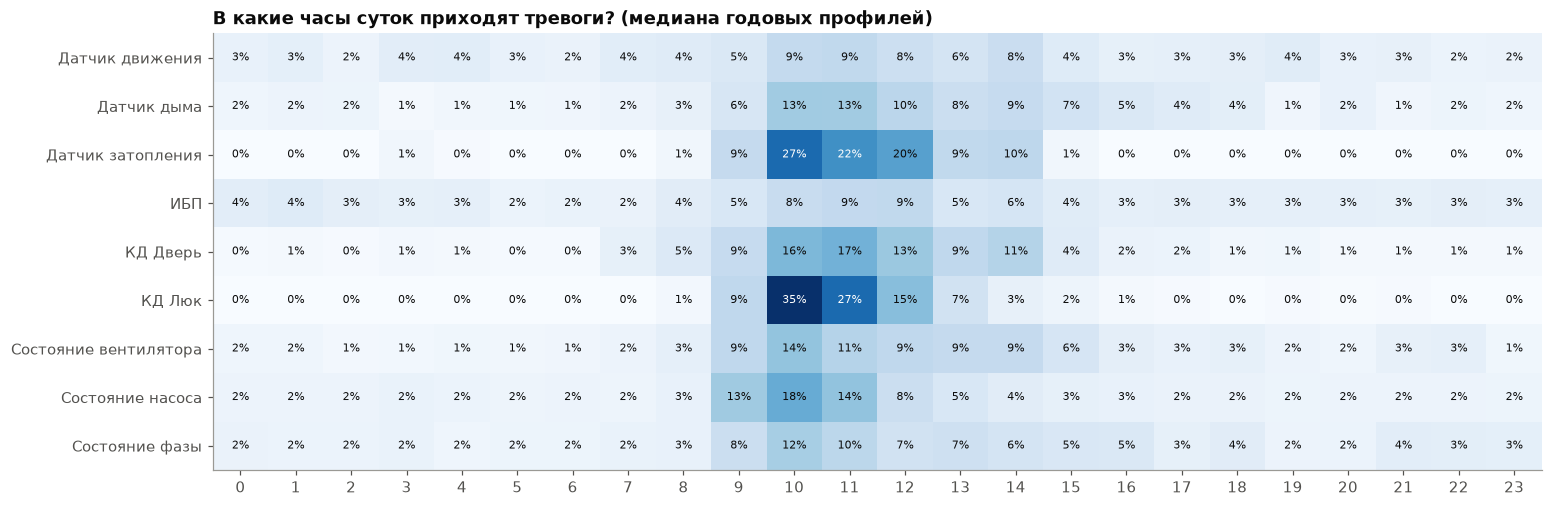

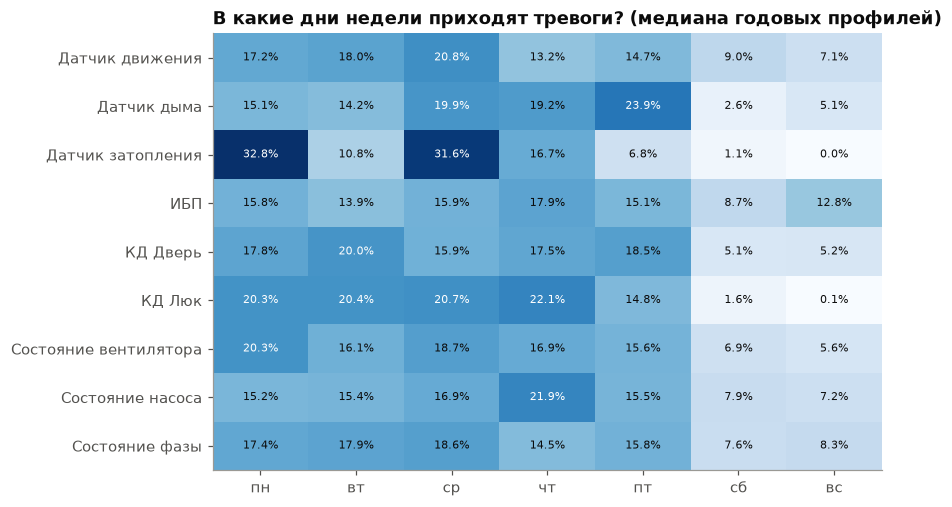

In [91]:
fig, ax = plt.subplots(figsize=(14, 4.5))
heatmap(ax, profile_med(h_med, "час_суток"), "В какие часы суток приходят тревоги? (медиана годовых профилей)",
        fmt="{:.0%}")
plt.show()
fig, ax = plt.subplots(figsize=(8, 4.5))
dow = profile_med(h_med, "день_недели").rename(columns=dict(enumerate(["пн", "вт", "ср", "чт", "пт", "сб", "вс"])))
heatmap(ax, dow, "В какие дни недели приходят тревоги? (медиана годовых профилей)")
plt.show()

In [92]:
# Доля тревог в рабочие часы 8:00-17:59 (при равномерном распределении по часам – 10/24 = 41,7 %) и пиковые часы
print("медиана годовых профилей, % тревог типа – месяц / день недели:")
display((profile_med(h_med, "месяц") * 100).round(1))
display((dow * 100).round(1))
hod_med = profile_med(h_med, "час_суток")
print("доля тревог в 8:00-17:59 и два самых «тяжелых» часа (медиана годовых профилей):")
display(pd.DataFrame({"8-17 ч": hod_med.loc[:, 8:17].sum(axis=1).round(3),
                      "пиковые часы": hod_med.apply(lambda r: ", ".join(f"{hh} ч {v:.0%}" for hh, v in r.nlargest(2).items()),
                                                    axis=1)}))
wh = h.assign(рабочие=h["час_суток"].between(8, 17)).groupby(["тип_датчика", "год"]).apply(
    lambda g: g.loc[g["рабочие"], "количество_тревожных"].sum() / max(g["количество_тревожных"].sum(), 1),
    include_groups=False)
wh.unstack().round(3)

медиана годовых профилей, % тревог типа – месяц / день недели:


месяц,1,2,3,4,5,6,7,8,9,10,11,12
тип_датчика,,,,,,,,,,,,
Датчик движения,9.2,9.0,7.5,3.0,6.0,17.4,18.1,9.6,6.1,8.1,2.9,3.0
Датчик дыма,15.9,12.1,4.1,4.2,8.9,17.9,13.6,5.3,6.5,3.5,5.6,2.5
Датчик затопления,3.7,4.1,1.9,17.8,1.9,12.0,5.2,4.5,6.2,27.0,1.9,13.6
ИБП,5.8,7.1,8.1,6.1,9.2,10.5,11.4,14.3,7.1,7.9,6.5,6.0
КД Дверь,9.4,12.4,4.9,4.2,6.6,13.5,7.0,4.8,8.5,10.5,8.3,9.9
КД Люк,9.1,5.1,9.2,6.2,9.6,6.5,9.3,6.1,8.9,10.3,12.4,7.3
Состояние вентилятора,6.7,10.0,8.2,8.1,10.2,8.8,8.3,8.0,6.6,8.1,8.0,8.9
Состояние насоса,7.4,3.8,15.9,12.9,6.9,8.3,9.1,11.5,4.9,7.8,5.7,5.8
Состояние фазы,7.5,6.8,12.6,11.1,8.7,9.9,7.7,8.5,5.9,6.1,6.3,8.8


день_недели,пн,вт,ср,чт,пт,сб,вс
тип_датчика,,,,,,,
Датчик движения,17.2,18.0,20.8,13.2,14.7,9.0,7.1
Датчик дыма,15.1,14.2,19.9,19.2,23.9,2.6,5.1
Датчик затопления,32.8,10.8,31.6,16.7,6.8,1.1,0.0
ИБП,15.8,13.9,15.9,17.9,15.1,8.7,12.8
КД Дверь,17.8,20.0,15.9,17.5,18.5,5.1,5.2
КД Люк,20.3,20.4,20.7,22.1,14.8,1.6,0.1
Состояние вентилятора,20.3,16.1,18.7,16.9,15.6,6.9,5.6
Состояние насоса,15.2,15.4,16.9,21.9,15.5,7.9,7.2
Состояние фазы,17.4,17.9,18.6,14.5,15.8,7.6,8.3


доля тревог в 8:00-17:59 и два самых «тяжелых» часа (медиана годовых профилей):


,8-17 ч,пиковые часы
тип_датчика,,
Датчик движения,0.592,"11 ч 9%, 10 ч 9%"
Датчик дыма,0.759,"10 ч 13%, 11 ч 13%"
Датчик затопления,0.986,"10 ч 27%, 11 ч 22%"
ИБП,0.575,"12 ч 9%, 11 ч 9%"
КД Дверь,0.881,"11 ч 17%, 10 ч 16%"
КД Люк,0.991,"10 ч 35%, 11 ч 27%"
Состояние вентилятора,0.757,"10 ч 14%, 11 ч 11%"
Состояние насоса,0.724,"10 ч 18%, 11 ч 14%"
Состояние фазы,0.652,"10 ч 12%, 11 ч 10%"


год,2019,2020,2021,2022,2023,2024,2025,2026
тип_датчика,,,,,,,,
Датчик движения,0.714,0.677,0.865,0.461,0.398,0.437,0.600,0.312
Датчик дыма,0.631,0.698,0.418,0.812,0.544,0.785,0.702,0.575
Датчик затопления,0.966,1.000,0.957,0.963,0.999,0.132,0.273,0.979
ИБП,0.573,0.630,0.473,0.600,0.593,0.600,0.374,0.609
КД Дверь,0.872,0.941,0.903,0.908,0.643,0.775,0.930,0.916
КД Люк,0.939,0.992,0.966,1.000,0.994,0.950,0.979,0.984
Состояние вентилятора,0.797,0.770,0.876,0.823,0.683,0.703,0.746,0.623
Состояние насоса,0.577,0.706,0.685,0.744,0.722,0.682,0.733,0.701
Состояние фазы,0.656,0.637,0.731,0.773,0.600,0.626,0.634,0.730


**У тревог охраны сильный «рабочий» ритм.** КД Люк: 94-100 % тревог в 8:00-17:59 во все годы, пик 10-11 ч (35 % + 27 %),
в выходные 1,6 % и 0,1 %. КД Дверь: 64-94 % в рабочие часы, суббота и воскресенье по 5 %. При равномерном
распределении на эти часы приходилось бы 41,7 %. Тревога люка почти всегда означает плановый визит бригады, а люк
или дверь ночью или в выходные – редкое и потому подозрительное событие.

**Технологические тревоги тоже «дневные».** Насос – 58-74 % в рабочие часы (пик 10 ч, 18 %), фаза – 60-77 %,
вентилятор – 62-88 %. У всех типов, кроме ИБП, на субботу и воскресенье приходится 0-9 % тревог
в день против 13-24 % в будни; исключение – ИБП (8,7 % в субботу, 12,8 % в воскресенье). Гипотеза: заметную часть «отказов» создают работы на объектах (включения,
переключения, проверки). Проверить ее напрямую можно по графику работ бригад; косвенно – по тому, была ли рядом
по времени тревога люка или двери на том же объекте.

**Датчик затопления** дает мало тревог (88-1 267 в год), и в 2019-2023 и 2026 годах 96-100 % из них – в 8:00-17:59:
похоже на проверки, а не на воду. В 2024 и 2025 годах эта доля 0,132 и 0,273 – причину мы не знаем.

**2021 год отличается:** у движения 0,865 тревог в рабочие часы (в 2022-2026 годах 0,31-0,60), у дыма 0,418 –
поток тревог перехода шел круглосуточно. Исключение 2021 года из профилей оправдано.

**Итог раздела 8.** Подтопление сезонно (март-апрель и август); тревоги люков и дверей почти целиком приходятся на
рабочие часы будней; технологические тревоги тоже дневные, то есть часть их связана с работами. Для сезонных
профилей нужна медиана годовых профилей: один всплеск смещает сводный профиль на десятки процентных пунктов.

## 9. Объекты, иерархия, пикеты
Прогноз нужно давать с местом, поэтому важно, как тревоги распределены по объектам. Вопросы: к каким уровням
иерархии привязаны каналы; сколько объектов дают основную массу тревог; устойчивы ли «проблемные» объекты из года
в год (если да, история объекта – сильный признак и сильный baseline); связаны ли тревоги соседних объектов одного
родителя; есть ли у каналов пикет как локация.

In [93]:
channels_pd.groupby("иерархия_уровень").agg(каналов=("ид_канала_данных", "size"), объектов=("ид_объект", "nunique"))

,каналов,объектов
иерархия_уровень,,
3,11485,78


80 % тревог 2022-2025 дают 22 объектов из 78
топ-5 объектов по доле тревог 2022-2025, %: {'ДУ объект Альфа': 13.7, 'объект Гамма ОС': 9.0, 'ДУ объект Кси': 5.6, 'ДУ ПС объект Омега': 4.8, 'объект Йота': 4.6}
родителей у объектов: 16; объектов у родителя: min 3, медиана 4, max 12


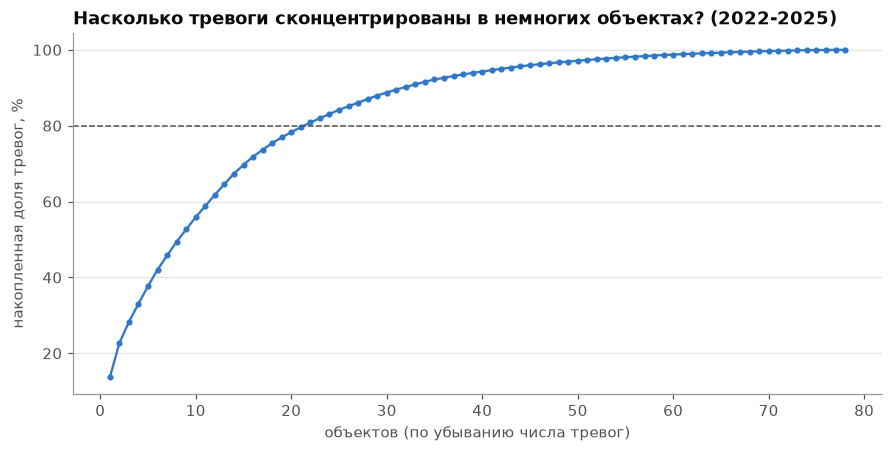

In [94]:
st_ch = daily_ch[(daily_ch["класс_записи"] == "состояние") & (daily_ch["ид_объект"] >= 0)]
obj_year = st_ch.groupby(["ид_объект", "год"])["количество_тревожных"].sum().unstack(fill_value=0)
tot = obj_year.loc[:, 2022:2025].sum(axis=1).sort_values(ascending=False)
cum = (tot.cumsum() / tot.sum()).reset_index(drop=True)
print(f"80 % тревог 2022-2025 дают {cum.searchsorted(0.8) + 1} объектов из {len(tot)}")
print("топ-5 объектов по доле тревог 2022-2025, %:",
      {obj_names.get(o): round(float(v / tot.sum() * 100), 1) for o, v in tot.head(5).items()})
kids = channels_pd.drop_duplicates("ид_объект").groupby("родитель")["ид_объект"].nunique()
print(f"родителей у объектов: {len(kids)}; объектов у родителя: min {kids.min()}, медиана {kids.median():.0f}, max {kids.max()}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(cum) + 1), cum.values * 100, color=PALETTE[0], marker="o", ms=3)
ax.axhline(80, color=INK2, ls="--", lw=1)
ax.set_xlabel("объектов (по убыванию числа тревог)")
ax.set_ylabel("накопленная доля тревог, %")
ax.set_title("Насколько тревоги сконцентрированы в немногих объектах? (2022-2025)")
plt.show()

In [95]:
# Устойчивость «проблемных» объектов: ранговая корреляция (Спирмен) числа тревог объектов между соседними годами
pd.Series({f"{y}→{y + 1}": obj_year[y].rank().corr(obj_year[y + 1].rank())
           for y in obj_year.columns if y + 1 in obj_year.columns}).round(2)

2019→2020    0.77
2020→2021    0.82
2021→2022    0.50
2022→2023    0.91
2023→2024    0.93
2024→2025    0.72
2025→2026    0.86
dtype: float64

In [96]:
# Синхронность соседей: корреляция суточных тревог объекта с суммой тревог его «братьев» (тот же родитель)
# в тот же день и днем раньше (опережающая связь)
od = (st_ch[st_ch["год"] >= 2022].groupby(["день", "ид_объект"])["количество_тревожных"].sum().unstack(fill_value=0)
      .asfreq("D", fill_value=0))
parent = channels_pd.drop_duplicates("ид_объект").set_index("ид_объект")["родитель"]
res = {}
for obj in od.columns:
    sib = [o for o in od.columns if o != obj and parent.get(o) == parent.get(obj)]
    if sib:
        s = od[sib].sum(axis=1)
        res[obj] = {"тот_же_день": od[obj].corr(s), "лаг_1_день": od[obj].corr(s.shift(1)), "братьев": len(sib)}
pd.DataFrame(res).T.describe().round(3)

,тот_же_день,лаг_1_день,братьев
count,78.000,78.000,78.000
mean,0.128,0.046,5.077
std,0.120,0.073,3.254
min,-0.008,-0.015,2.000
25%,0.040,-0.002,3.000
50%,0.093,0.017,3.000
75%,0.189,0.067,9.000
max,0.577,0.359,11.000


In [97]:
# Пикет: доля каналов с пикетом по объектам и число разных пикетов у объекта
pk_share = channels_pd.groupby("ид_объект")["пикет"].apply(lambda s: s.notna().mean())
display(pk_share.describe().round(3))
low_pk = pk_share[pk_share < 0.5].index
print(f"каналов с пикетом: {channels_pd['пикет'].notna().mean():.1%}; объектов без пикетов: {(pk_share == 0).sum()};",
      f"с пикетом меньше чем у половины каналов: {len(low_pk)} ({channels_pd['ид_объект'].isin(low_pk).sum()} каналов):",
      [obj_names.get(o) for o in low_pk][:8])
channels_pd.groupby("ид_объект")["пикет"].nunique().describe().round(1).rename("разных пикетов у объекта")

count    78.000
mean      0.731
std       0.369
min       0.000
25%       0.589
50%       0.978
75%       1.000
max       1.000
Name: пикет, dtype: float64

каналов с пикетом: 93.3%; объектов без пикетов: 11; с пикетом меньше чем у половины каналов: 17 (444 каналов): ['ДП объект Вита', 'ДП ПС объект Ро', 'ДП объект Йота', 'Шкаф ОПС объект Йота', 'ДП объект Сигма', 'ДП объект Омикрон', 'Шкаф ОПС объект Хи', 'ДП ПС объект Омега']


count     78.0
mean      49.4
std       84.2
min        0.0
25%        3.0
50%       18.0
75%       54.8
max      454.0
Name: разных пикетов у объекта, dtype: float64

- **Иерархия.** Все 11 485 каналов справочника привязаны к 78 объектам уровня 3. У объектов 16 родителей, у каждого
  от 3 до 12 объектов (медиана 4). По сути родитель – коллектор, а объекты – его участки (Кси ПК0-ПК202, Кси
  ПК202-ПК302…), ДУ, ДП и ПС.
- **Концентрация высокая.** 80 % тревог 2022-2025 годов дают 22 объекта из 78. Первый – Альфа, 13,7 % тревог
  (вместе со всплеском 2025-11-06), дальше «объект Гамма ОС» – 9,0 %, «ДУ объект Кси» – 5,6 %, «ДУ ПС объект Омега» –
  4,8 %, «объект Йота» – 4,6 %.
- **«Проблемные» объекты устойчивы.** Ранговая корреляция числа тревог объектов между соседними годами: 0,77
  (2019→2020), 0,82, **0,50 (2021→2022, через переход)**, 0,91, 0,93, 0,72, 0,86 (2025→2026). Вне перехода 0,72-0,93.
  Это аргумент за признаки «история объекта» и одновременно предупреждение: baseline «частота тревог объекта за
  прошлый период» будет сильным, и модель обязана его обойти.
- **Опережающей связи с «братьями» почти нет.** Корреляция суточных тревог объекта с суммой тревог объектов того же
  родителя: в тот же день медиана 0,093 (среднее 0,128, максимум 0,577), с лагом 1 день медиана 0,017 (максимум
  0,359). Синхронность в тот же день частично создают общесистемные события (обрывы, всплески), которые сырые
  суммы не вычитают. Как предиктор завтрашнего дня соседи слабы в среднем, но у отдельных объектов связь заметна.
- **Пикет как локация пригоден частично.** Пикет есть у 93,3 % каналов, медианная доля по объектам 0,978. Но у 11
  объектов пикетов нет совсем, у 17 объектов пикет есть меньше чем у половины каналов (444 канала): это ДП, ДУ и
  шкафы – здания и пункты, а не участки трассы. У объекта в среднем 49 разных пикетов (медиана 18).

**Итог раздела 9.** Единица прогноза – объект уровня 3 (78 объектов), локация внутри – пикет там, где он есть.
Тревоги сконцентрированы и устойчивы по объектам; соседство по иерархии дает мало.

## 10. Итоги

### 10.1 Что мы установили

1. **Журнал:** 312 982 076 событий за 2019-01-01 … 2026-06-30, тревожных 0,79 %; очистка удалила 563 940 полных
   дублей и одну строку заголовка (раздел 0).
2. **Суммарный поток – это газ одного объекта.** Альфа дает 38-63 % событий года с 2021 года, но 1,7-18,9 % тревог;
   все ступени суммарного потока – ее опрос, число каналов и ежегодное ноябрьское молчание 4-8 суток (разделы 1, 4, 6).
3. **Данные непрерывны, кроме общего обрыва** 2024-04-06 02:00 … 2024-04-10 (75 часов без событий) и дня
   2026-06-01 (раздел 2.1).
4. **Переход СМВУ 2021 года найден в данных:** [2021-04-22 07:00, 2021-06-08 10:00), границы совпадают
   с `annanas.smvu`. Аномалия перехода – дребезг «Неисправен ↔ норма» 77 дымовых каналов одного объекта (99,98 %
   тревог дыма полосы), тревоги короткие (медиана 92 с), неснятых в журнале нет. Каналы, ID и словарь через переход
   не изменились; рост потока после перехода – сезонный газ Альфы (раздел 3).
5. **Каналы вне справочника** (1 142) – не старая система, а, вероятно, выведенные в 2021-2023 годах каналы; до
   перехода на них 22,3 % тревог без типа и объекта (разделы 2.4, 3.7).
6. **Режимных разрывов три:** 2020-10-08 (опрос газа Альфы, раздел 4), переход 2021 года (раздел 3), смена разметки
   флага `тревожное` около 2025-11-01 (раздел 5). Кроме того, флаг у одной пары (тип, состояние) дрейфует по годам
   (раздел 3.5).
7. **Всплеск 2025-11-06 09:00-11:59** – 32 012 «Неисправен» на газе Альфы, 89,3 % тревог газа 2025 года: одно
   сервисное событие (раздел 6).
8. **Тревоги идут цепочками** (у 12,2 % тревожных записей следующая в ту же секунду), естественного порога дребезга
   нет, 79,5 % эпизодов короче 60 с; длинные тревоги – почти только «Отключено устройство» и температурный режим
   (раздел 5).
9. **Числовых тревог нет,** есть коды ошибок датчиков; газ вне Альфы пишет пачками по 30-70 замеров в сутки
   (раздел 4).
10. **Пачки «Неопределен» – модули контроллеров** (13, 20, 22, 43, 70, 95 каналов); молчание телеметрии – второй,
    отдельный механизм потери связи (раздел 7).
11. **Часть «отказов» создают работы:** тревоги люков – 94-100 % в рабочие часы, насосы, фаза и вентиляторы тоже
    дневные (58-88 % при равномерных 41,7 %); подтопление сезонно – март-апрель и август (раздел 8).
12. **Проблемные объекты стабильны:** ранговая корреляция тревог между соседними годами 0,72-0,93 вне перехода;
    22 объекта из 78 дают 80 % тревог 2022-2025 годов (раздел 9).

### 10.2 Что это значит для этапа 2 (целевая переменная)

**Эпизод.** Подряд идущие тревожные записи канала до первой нетревожной; записи одной секунды – один эпизод; класс
эпизода – по приоритету состояний в цепочке: подтопление > пожар > отказ > проникновение (раздел 5). Порог дребезга
60 с как рабочий, с проверкой чувствительности на 30 и 120 с. Для «Неопределен» повторы нужно схлопывать (6,7 %
записей «Неопределен» → «Неопределен», раздел 7).

**Классы-кандидаты** (эпизоды каналов справочника вне перехода, таблица `cls_tab` в разделе 5):

| Класс | Состояния | Эпизодов ≥ 60 с (по цепочке) |
|---|---|---:|
| A. Отказ | Неисправен, Обесточен, Питание от батарей, Батарея разряжена, Много неисправных устройств, температура «Не определено» | 67 060 |
| B. Потеря связи | пачка «Неопределен» по правилу ниже или молчание телеметрии | 2 483 объекто-суток (пачки) |
| C. Подтопление | Затоплен (в любом месте цепочки), «Не замкнут» датчика затопления | 8 232 (158, если по первому состоянию) |
| D. Пожар | Обнаружен дым, Рычаг сдернут, «Не замкнут» теплового и ручного извещателя | 27 938 |
| E. Проникновение | Обнаружено движение, «Не замкнут» КД АВ, Дверь, Люк, Стекло, 9-секционный люк | 83 415 |
| газ (отдельно или в D) | Обнаружен газ | 1 961 |

Для сравнения: откачка («Работают все насосы в АНС») – 11 601, температурный режим – 3 230, «Отключено
устройство» – 5 126 эпизодов ≥ 60 с. Это объем за 2019-2026 годы по всем 78 объектам; на сетке «объект × сутки»
положительных будет меньше, потому что эпизоды одного объекта за сутки склеятся.

- «Отключено устройство» – не целевая, а признак «вывод из работы / ТО»; «Работают все насосы в АНС» – предвестник
  подтопления, а не отказ; температура ниже 3 °C / выше 40 °C – признак.
- «Батарея неисправна» не тревожна ни разу; «Датчик затопления» дает мало тревог и почти все днем, поэтому для
  подтопления основное – «Затоплен».

**Класс B** (раздел 7): в минуту ≥ min(10, ⌈0,5 · каналов объекта⌉) каналов в «Неопределен», минуты с разрывом
≤ 5 мин склеены, эпизод ≥ 10 мин – 2 483 объекто-суток вне перехода, ~0,7-1,1 % положительных на сетке объект ×
сутки. Вторая ветка – молчание телеметрии относительно ее группы: у Альфы от нескольких часов, у остального газа от
суток (раздел 4).

**Маски** (не использовать как положительные и отрицательные примеры, не захватывать окнами признаков):
- переход СМВУ [2021-04-22 07:00, 2021-06-08 10:00) и возмущение 2021-06-28 … 2021-07-03 (раздел 3);
- общий обрыв 2024-04-06 02:00 … 2024-04-10 и день 2026-06-01 (раздел 2.1);
- ноябрьские окна газа Альфы – для телеметрии и класса B (раздел 6);
- всплеск 2025-11-06 09:00-11:59 – один сервисный эпизод, а не 32 тыс. тревог (раздел 6);
- пометить «вероятно не отказ»: тревоги внутри пачки «Неопределен» ± 5 мин и тревоги насоса / фазы / вентилятора
  при недавнем открытии люка или двери того же объекта (разделы 7, 8).

**Эпохи** (признаки, а не маски): период СМВУ до / после (раздел 3); эпоха разметки флага с 2025-11-01 с переходной
полосой 2025-10-15 … 2025-12-05 (раздел 5); смены опроса газа Альфы (2020-10-08, декабрь 2022, 2024-06-01,
2024-07-31) – точки разрыва нормировок телеметрии (разделы 4, 6).

**Каналы.** Целевая – только по каналам справочника; в данных до перехода поэтому не видно 22,3 % тревог (раздел
3.7). Долю событий вне справочника за окно дать признаком.

**Обучение и проверка.** Все годы, кроме масок, с признаками эпох. Проверка – только на временном разбиении, на
отложенном периоде после перехода, рядом с baseline «история объекта» (раздел 9); период после ноября 2025 года
оценивать отдельно (другая разметка флага). Обязательная абляция «только после перехода» (с 2021-06-08 10:00).
Флаг `тревожное` как целевую «как есть» не брать: он дрейфует по годам (раздел 3.5) и сменил разметку (раздел 5).

### 10.3 Что это значит для этапа 3 (признаки)

| Признак-кандидат | Что его обосновывает |
|---|---|
| История объекта за 7 / 30 / 90 дней по классам (эпизоды, пачки, отказы) | устойчивость объектов 0,72-0,93, раздел 9 |
| Канал: тревоги за 1 ч / 24 ч / 7 дней, время с последней тревоги, доля коротких эпизодов за 30 дней | повтор в течение часа у 71,4 % эпизодов, раздел 5 |
| Эпохи: период СМВУ, эпоха разметки флага, доля событий вне справочника | разделы 3, 5 |
| Потеря связи: доля активных каналов объекта за 24 ч к медиане 28 дней; число коротких пачек и переходов «Неопределен ↔ Норма»; история пачек за 30 / 90 дней | разделы 6, 7 |
| Телеметрия: отклонение от нормы канала (к скользящей медиане, температура – к норме месяца); коды ошибок → пропуск + флаг «код ошибки»; замеров на канал к медиане 28 дней | раздел 4 |
| Контекст работ: вне рабочих часов (будни 8:00-17:59), выходной, тревога люка или двери на объекте за 1-3 ч | раздел 8 |
| Канал выведен из работы («Отключено устройство», длинные неснятые) | раздел 5 |
| Подтопление: флаги «март-апрель» и «август», «Работают все насосы в АНС», частота переключений насосов | разделы 5, 8 |
| Канал: возраст, поколение (квартал появления, диапазон ID), «k из n датчиков пикета в тревоге» | разделы 2.2, 2.3 |
| Флаппинг УИР-Р как возможный предвестник обрыва | раздел 6 (один случай, проверить) |
| Общесистемный поток тревог за 1 ч; активность «братьев» за 24 ч | раздел 9 (вклад ожидается малый) |
| Покрытие: есть ли на объекте газовая телеметрия; группа газа (Альфа / остальные) | раздел 4 |

Объемы нормировать на активные каналы типа и объекта (активный – писал что-то кроме «Неопределен»), с учетом эпохи
и сезона. Метрики смотреть и в среднем по объектам, и по всем событиям: 22 объекта дают 80 % тревог.

### 10.4 Открытые вопросы к организаторам

1. Будет ли журнал ОДС или выборка решений диспетчера с отметкой «ложное срабатывание» и отметкой о квитировании
   тревоги?
2. Когда именно в 2021 году работали параллельно две СМВУ и когда отключили старую? Совпадает ли это с
   [2021-04-22 07:00, 2021-06-08 10:00)?
3. Флаг `тревожное` – тревога, которую видит диспетчер, или внутренний признак СМВУ? Что изменилось в его разметке
   в октябре-декабре 2025 года?
4. В каких единицах газ, есть ли пороги тревоги для газа и температуры? Пишутся ли газовые каналы вне Альфы по
   изменению значения?
5. Значения −127, 128, −3 276, 999 (температура) и 2,55, −2,56, 327,68 (газ) – коды ошибок датчика?
6. «Отключено устройство» – это вывод канала в ТО или ремонт?
7. Что произошло 2020-10-08 с опросом газа ДУ объекта Альфа (62 → 8 с)?
8. Ноябрьские окна молчания газа Альфы (4-8 суток ежегодно) – плановая поверка газоанализаторов? Всплеск
   «Неисправен» 2025-11-06 09:00-11:59 и отключение 28 газовых каналов Альфы 2022-07-15 … 2023-11-15 – работы?
9. Обрыв 2024-04-06 … 04-10 – сбой сбора данных всей СМВУ?
10. 1 142 канала вне справочника – выведены из эксплуатации? Можно ли получить их тип и объект?
11. Есть ли график работ бригад или регламент ТО по объектам?
12. Будет ли проверка на скрытом периоде после 2026-06-30, и в каком формате?
13. Можно ли использовать внешние данные: погоду, производственный календарь?